# PlaceGNN — Amortized Graph-Neural Fog Node Placement
**Reference implementation of the PlaceGNN methodology (Sections 3.1–3.10), runnable on the Google Colab free tier.**

This notebook trains and evaluates **PlaceGNN**. PlaceGNN is a graph neural network trained without labels to *emit* fog-node placements in one forward pass, instead of re-running a metaheuristic search at every network change. Evaluation covers synthetic networks at the reference scale of the fog-placement literature (100 fog nodes in 1 km², ranges 100–150 m) and the open **EUA dataset** (real Melbourne edge-site and user locations, MIT licence).

| Methodology section | Where it is implemented |
|---|---|
| 3.2 Network model & heterogeneous graph | `gen_instance`, `prepare` |
| 3.3–3.4 Amortized policy, GNN encoder, decoder heads | `PlaceGNN`, `calibrate` |
| 3.5 Unsupervised objective (coverage, Fiedler connectivity, energy, Lagrangian constraints) | `objective_terms`, `train_model` |
| 3.6 Derandomized decoding with certificate + repair | `ce_decode`, `fix_and_repair` |
| 3.7 Movement-aware & incremental inference | `prev_*` features, `incremental_logits` |
| 3.8 Two-stage training (unsupervised → self-critical REINFORCE) | `train_model` |
| 3.10 Protocol: baselines, MILP gap, zero-shot scale, real data, 6 dynamic scenarios, Pareto HV, ablations, statistics | Experiments E1–E7 |

**Where the implementation refines the written methodology.** Each item was found necessary during testing. Update the manuscript text to match.
1. *Eq. (1)*: absolute coordinates are replaced by relative edge features (distance / r_max). This makes the model translation-invariant and independent of the deployment-area size, which is required for zero-shot scaling.
2. *Eq. (5)*: the Fiedler value is taken on the **shifted** Laplacian $\hat L(q)+\gamma\,\mathrm{diag}(1-q)$. The plain version is always 0, because unselected sites are isolated vertices.
3. *Eq. (6)*: movement energy is the **entropic optimal-transport** cost from the deployed fleet to the new placement (Sinkhorn with ε-scaling; gradients via the envelope theorem). Charging each site only its distance to the nearest previous node ignores abandoned sites and produced long, unnecessary relocations.
4. *Eq. (7)*: an **annealed integrality penalty** ρ·q(1−q) is added, and the budget is enforced exactly by a calibrated sigmoid rather than a Lagrange multiplier.
5. *Section 3.6*: the decoder's per-site movement cost is the soft c-transform of the OT potentials, and connectivity repair accepts a move **only if it increases J**, preferring bridging sites.
6. *Section 3.4 (v2)*: w is **FiLM-conditioned** into every layer and both heads, and the position head is gated. A quarter of the training preferences are extreme (sparse Dirichlet).
7. *Section 3.7 (v2)*: a **hold-or-move policy**. In dynamic re-placement the controller returns the better of the proposed placement and simply holding position, so a reconfiguration never scores worse than doing nothing. It is applied identically to every method.
8. *Section 3.7 (v2)*: a **recovery mode** asks for connectivity-priority weights under severe fragmentation (connectivity < 0.8). The rule is applied identically to every method, and `PlaceGNN (fixed w)` is kept as the ablation. This targets the v1 weakness after catastrophic 50 % failures.
9. *Sections 3.4 and 3.8 (v3 → v4)*: **mean aggregation** (v4; the v3 run's validation split and ablations preferred it over GAT, 0.7950 vs 0.7912), **no** position-refinement head, and 2,000 stage-1 steps.
10. *Section 3.6 (v3)*: **best-of-N decoding**. The certified decode plus N−1 exactly-K samples from the model are each repaired, and the best under J is returned. It is never worse than the certified decode, and `PlaceGNN (N=1)` is the ablation.
11. *Section 3.10 (v3)*: **3 independent training seeds**, reported as mean ± std in the seed-robustness table.
12. *Section 3.8 (v3)*: **EMA weights, cosine learning-rate decay and validation-based checkpoint selection**. Identical training runs varied by up to 0.02 J, more than any design choice, so the best validation checkpoint is kept. *Finding to report:* in the v3 FULL run, stage 2 (REINFORCE) was selected by validation for only 1 of 3 seeds. Present it as a minor, optional refinement.
13. *Section 3.10 (v4)*: **published baselines**. Five population-based metaheuristics from the placement literature (D-POA, PSO, GWO, DE, TLBO) run under an equal objective-evaluation budget, plus a **deep-RL constructive baseline** (DRL-AM: attention-model decoder trained by REINFORCE with a POMO shared baseline).
14. *Section 3.8 (v4)*: **PlaceGNN-H**, a hybrid supervised → unsupervised training scheme. It is initialised from the MILP-imitation model and then trained on the unsupervised objective. The headline model is chosen on the validation split.
15. *Section 3.10 (v4)*: **paired statistics**: the Wilcoxon signed-rank test on matched instances, the Holm–Bonferroni correction across all comparisons, and 95 % bootstrap confidence intervals of the paired mean difference.
16. *Section 3.10 (v4)*: **sensitivity analysis** (N, sampling temperature, recovery threshold, ρ_max), **scaling to 5,000 nodes**, and a **latency breakdown** (graph construction / GNN / decode / best-of-N / hold).
17. *Section 3.10 (v4)*: an **untrained-network ablation** (`PlaceGNN (untrained)`), which runs the same decoder, repair and best-of-N on random weights.
18. *Section 3.10 (v5)*: **30 trajectories per dynamic scenario** and **primary-endpoint statistics**: Holm's correction is applied to J (the pre-specified primary metric) across methods, and secondary metrics are descriptive. **DRL-AM is retrained** with 16 instances per step and EMA validation (in v4 it stopped improving after 250 steps; the CPU check shows validation J 0.716 → 0.729 with the same number of training instances).

**v4 FULL results (3 seeds, Colab GPU), which v5 builds on:**
* **Where learning wins.** In the dynamic scenarios (E5, pooled) PlaceGNN scores J = 0.7662, better than every baseline (Holm-significant): WS-GA 0.7611, D-POA 0.7577, Greedy-CC 0.7572, the untrained network 0.7486 and DRL-AM 0.7460. For preference satisfaction (E6), J_pref is 0.525, best in 90 % of cases, against at most 0.496 (60 %) for the baselines, and the hypervolume is 0.745 against 0.614. The untrained network falls to Greedy level in both, so these gains come from learning.
* **Where it does not.** In static placement (E1) PlaceGNN (0.7954) is 0.13–0.32 % *below* Greedy-CC, Supervised-GNN and all six metaheuristics, and an untrained network with the same decoder does as well; it is, however, 55–95× faster than the metaheuristics. At K = 5,000, Greedy-CC is both better and faster. The incremental inference (E3b) is exact but not faster on GPU.
* **Open issue fixed in v5.** In the catastrophic scenario PlaceGNN won 7–8 of 10 trajectories (+0.016 to +0.024 J), yet no comparison survived Holm correction with n = 10.

**Run cost.** With the v4 folder on Drive, v5 trains only DRL-AM. It recomputes E2 and every DRL-AM unit, and runs trajectories 10–29 of E5 for all methods; E5 is most of the time (WS-GA and D-POA re-plan at every event). Expect 2–4 free-tier sessions.

### How to run
1. **Runtime → Change runtime type → T4 GPU** (CPU also works; it is just slower).
2. `MODE` in the next cell is `"FULL"` (the paper-scale run). Set it to `"QUICK"` for a ~1-minute smoke test at toy scale.
3. **Runtime → Run all.** Approve the Google Drive prompt.

### Resuming after a disconnect (free tier)
Everything is written to `MyDrive/PlaceGNN_runs/<RUN_NAME>/`:
* **Training** checkpoints every `ckpt_every` steps *and* every `ckpt_minutes` minutes. Each checkpoint holds the model, optimizer, dual multipliers, RNG states, step counter and loss history. Saves are atomic, and the previous checkpoint is kept as a fallback.
* **Every experiment unit** (one method × one instance or seed) is cached as its own JSON file. On resume, finished units are skipped.
* Training instances are generated from `(seed, step)`, so a resumed run sees **exactly** the same data it would have seen without interruption.

If Colab disconnects, reconnect and **Run all** again. The notebook resumes where it stopped. It also stops itself cleanly, with a checkpoint, once `SESSION_BUDGET_MIN` is reached, so it is not killed mid-write.

*Verified:* a run stopped mid-training and resumed produces **bit-identical** model weights and experiment results compared with an uninterrupted run, under single-threaded execution. With multi-threaded CPU or GPU kernels, floating-point summation order varies, so *any* two runs, resumed or not, differ at round-off level. Report mean ± std over seeds, as the notebook does.

**FULL-mode cost from scratch (no v4 folder on Drive):** about 3–4 h of training (3 PlaceGNN seeds, 3 PlaceGNN-H seeds, the supervised baseline, DRL-AM, and 5 ablation models) and about 6–8 h of experiments. The metaheuristics (5 algorithms × 10⁴ evaluations per static instance) and the warm-started searches in the dynamic scenarios are the slowest parts. Expect 4–6 free-tier sessions; resuming is automatic. A GPU speeds up training only, because the metaheuristics run on CPU.

In [1]:
# ===================== 0. Run configuration =====================
import os
MODE = os.environ.get("PLACEGNN_MODE", "FULL")    # "FULL" (paper-scale) | "QUICK" (~1-min smoke test)
RUN_NAME = os.environ.get("PLACEGNN_RUN", f"placegnn_{MODE.lower()}_v5")   # v5: 30 dynamic trajectories, primary-endpoint Holm, stronger DRL-AM; reuses the v4 run
SESSION_BUDGET_MIN = float(os.environ.get("PLACEGNN_BUDGET_MIN", "170"))  # stop cleanly (with checkpoint) after this many minutes
ALLOW_CONFIG_CHANGE = False   # True only if you intentionally edit CFG for an existing RUN_NAME

In [2]:
# ===================== 1. Setup: Drive, packages, imports =====================
import sys, json, time, math, random, hashlib, shutil, pickle, subprocess, warnings, copy, urllib.request
T_START = time.time()
IN_COLAB = "google.colab" in sys.modules

def _ensure(pkg, mod=None):
    try:
        __import__(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
_ensure("pulp")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/PlaceGNN_runs"
else:
    BASE = os.environ.get("PLACEGNN_BASE", os.path.abspath("PlaceGNN_runs"))
RUN_DIR = os.path.join(BASE, RUN_NAME)
DATA_DIR = os.path.join(BASE, "data")
for sub in ["ckpt", "results", "figures", "tables", "cache"]:
    os.makedirs(os.path.join(RUN_DIR, sub), exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.optimize import linear_sum_assignment
from scipy import stats
import matplotlib
if not IN_COLAB and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"MODE={MODE} | device={DEVICE} | torch {torch.__version__} | run dir: {RUN_DIR}")

Mounted at /content/drive
MODE=FULL | device=cuda | torch 2.11.0+cu128 | run dir: /content/drive/MyDrive/PlaceGNN_runs/placegnn_full_v5


In [3]:
# ===================== 2. Experiment configuration =====================
QUICK = MODE.upper() == "QUICK"
CFG = dict(
    seed=2026,
    # --- geometry (reference scale of the fog-placement literature: 100 fog nodes in 1 km^2, ranges 100-150 m) ---
    area_ref=1000.0, density_ref_K=100, sparsity=(1.0, 1.7),   # side = 1000*sqrt(K/100)*s, s~U(sparsity)
    r_min=100.0, r_max=150.0,
    m_ratio=(1.2, 3.0),        # candidate sites per fog node
    l_ratio=(3.0, 14.0),       # edge devices per fog node
    delta_max=25.0, tau=5.0, gamma_shift=1.0, fiedler_eps=1e-4,
    # --- energy / battery model (nonlinear, as in the baseline cost model) ---
    e_c1=0.01, e_c2=1e-4,              # E(m) = c1*m + c2*m^2
    batt_c1=5e-4, batt_c2=2e-6, b_min=0.1,
    v_move=5.0, dt=10.0,               # node speed (m/s), simulation step (s)
    # --- model ---
    hidden=64, layers=4, knn=8,
    # --- training ---
    train_K=(8, 40) if QUICK else (8, 120),
    batch=2 if QUICK else 4,
    steps1=60 if QUICK else 2000,      # v2 ablation: 2000 stage-1 steps beat 4000 (over-long integrality annealing)
    steps2=16 if QUICK else 1000,
    lr=1e-3, lr2=2e-4,
    rl_samples=4, rl_mix=0.5, rl_scale=10.0,
    p_dynamic=0.6, dual_lr=0.05, over_tol=0.10, mu_max=2.0,   # tolerance must be attainable: ~20% overload is unavoidable at these capacities for every method
    rho_max=1.0, rho_ramp=0.6,         # annealed integrality penalty rho*mean q(1-q), ramped over the first 60% of stage 1
    ot_eps=0.02, ot_iters=100, ot_eps_start=100.0,   # entropic OT (Sinkhorn, eps-scaling) for the expected movement cost
    ckpt_every=10 if QUICK else 50, ckpt_minutes=5.0,
    abl_frac=0.5,
    w_default=(0.4, 0.4, 0.2),        # (coverage, connectivity, movement-energy)
    infer_samples=8, infer_temp=1.0,   # best-of-N decoding: N-1 Gumbel top-K samples + the certified decode
    train_seeds=2 if QUICK else 3,     # independent training runs of the main model (init + data stream)
    ema_decay=0.8 if QUICK else 0.995, val_every=20 if QUICK else 250,   # EMA weights + validation-based checkpoint selection
    val_n_train=4 if QUICK else 12, val_K=25 if QUICK else 60,          # validation set used during training (stream 112)
    n_val=6 if QUICK else 30,          # validation instances (disjoint stream) for model selection
    w_extreme_p=0.25, w_alpha_extreme=0.4,  # a quarter of the training preferences come from a sparse Dirichlet (extreme trade-offs)
    rec_w=(0.3, 0.6, 0.1), rec_conn_thr=0.8,   # recovery mode: connectivity-priority weights under severe fragmentation (conn < 0.8)
    # --- evaluation ---
    eval_K=30 if QUICK else 100,
    n_static=6 if QUICK else 50,
    n_milp=4 if QUICK else 30, milp_K=8, milp_M=24, milp_L=80, milp_timeout=30 if QUICK else 120,
    n_sup=12 if QUICK else 300, sup_steps=40 if QUICK else 2000,
    scal_K=[25, 50, 100] if QUICK else [50, 100, 250, 500, 1000], n_scal=2 if QUICK else 10,
    n_incr=3 if QUICK else 20,
    n_eua=3 if QUICK else 20, eua_window_m=1500.0, eua_node_frac=0.8,
    scenarios=["mobility", "failure", "traffic", "expansion", "catastrophic", "flash"],
    n_dyn=2 if QUICK else 30, dyn_T=8 if QUICK else 40,   # v5: 30 trajectories per scenario (10 cannot reach significance after Holm)
    ga_pop=16 if QUICK else 50, ga_iters=15 if QUICK else 200, ga_iters_warm=8 if QUICK else 60,
    n_pareto=2 if QUICK else 30, pareto_w=6 if QUICK else 15, hv_samples=20000 if QUICK else 100000,
    # --- v4 ---
    hyb_steps1=30 if QUICK else 1000, hyb_steps2=8 if QUICK else 500,       # PlaceGNN-H (hybrid) budgets
    drl_steps=30 if QUICK else 2000, drl_rollouts=8, drl_lr=1e-4, drl_samples=8,   # DRL-AM baseline
    drl_batch=4 if QUICK else 16,      # v5: instances per DRL-AM step (v4 used `batch` = 4, too noisy)
    scal_K_big=[] if QUICK else [2000, 5000], n_scal_big=3,                # extreme-scale runs (fast methods only)
    sens_N=[1, 2, 4, 8, 16], sens_temp=[0.5, 1.0, 2.0], sens_rec=[0.6, 0.7, 0.8, 0.9],
    n_sens=4 if QUICK else 30, n_sens_dyn=1 if QUICK else 5,
    n_boot=2000,
)
CFG_HASH = hashlib.md5(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:10]

cfg_path = os.path.join(RUN_DIR, "config.json")
if os.path.exists(cfg_path):
    old = json.load(open(cfg_path))
    if old.get("hash") != CFG_HASH and not ALLOW_CONFIG_CHANGE:
        raise RuntimeError(f"CFG differs from the one stored in {cfg_path}. Use a new RUN_NAME, "
                           "or set ALLOW_CONFIG_CHANGE=True if the change is intentional.")
json.dump(dict(hash=CFG_HASH, cfg=CFG), open(cfg_path, "w"), indent=1)
W_DEF = tuple(CFG["w_default"])
print("config hash", CFG_HASH)

config hash 85ba0f626c


## Checkpointing, result caching and the session guard
* `Checkpointer` — atomic writes (`tmp` → `os.replace`) with the last good checkpoint kept as `prev.pt`, so a disconnect during a save cannot corrupt the run.
* `cached_unit` — every experiment unit is a JSON file. A unit that already exists is loaded, not recomputed.
* `check_budget` — saves and stops cleanly shortly before `SESSION_BUDGET_MIN`.

In [4]:
class SessionBudgetReached(Exception):
    pass

def minutes_used():
    return (time.time() - T_START) / 60.0

def check_budget(save_fn=None):
    if minutes_used() > SESSION_BUDGET_MIN:
        if save_fn is not None:
            save_fn()
        raise SessionBudgetReached(
            f"Session budget of {SESSION_BUDGET_MIN} min reached. Everything is checkpointed in {RUN_DIR}. "
            "Reconnect (or start a new session) and choose Runtime -> Run all to resume.")

def _fsync(path):
    try:
        fd = os.open(path, os.O_RDONLY); os.fsync(fd); os.close(fd)
    except OSError:
        pass

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp); _fsync(tmp); os.replace(tmp, path)

def atomic_json_save(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, default=_json_default)
    _fsync(tmp); os.replace(tmp, path)

def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))

class Checkpointer:
    def __init__(self, name):
        self.dir = os.path.join(RUN_DIR, "ckpt", name)
        os.makedirs(self.dir, exist_ok=True)
        self.latest = os.path.join(self.dir, "latest.pt")
        self.prev = os.path.join(self.dir, "prev.pt")

    def save(self, state):
        if os.path.exists(self.latest):
            os.replace(self.latest, self.prev)
        atomic_torch_save(state, self.latest)

    def load(self):
        for p in (self.latest, self.prev):
            if os.path.exists(p):
                try:
                    return torch.load(p, map_location="cpu", weights_only=False)
                except Exception as e:  # corrupted/partial file -> fall back
                    print(f"[ckpt] could not read {p}: {e}")
        return None

    def save_named(self, tag, state):
        atomic_torch_save(state, os.path.join(self.dir, f"{tag}.pt"))

    def load_named(self, tag):
        p = os.path.join(self.dir, f"{tag}.pt")
        return torch.load(p, map_location="cpu", weights_only=False) if os.path.exists(p) else None

def rng_state():
    return dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)

def set_rng_state(s):
    random.setstate(s["py"]); np.random.set_state(s["np"]); torch.set_rng_state(s["torch"])
    if s.get("cuda") is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(s["cuda"])

def name_seed(name):
    return int(hashlib.md5(name.encode()).hexdigest()[:8], 16)

def cached_unit(exp, key, fn):
    d = os.path.join(RUN_DIR, "results", exp); os.makedirs(d, exist_ok=True)
    p = os.path.join(d, f"{key}.json")
    if os.path.exists(p):
        try:
            return json.load(open(p))
        except Exception:
            pass
    out = fn()
    atomic_json_save(out, p)
    return out

def run_units(exp, units, fn, desc=None):
    """units: list of (key, kwargs). Resumable: completed units are read from Drive."""
    rows, t0, n_new = [], time.time(), 0
    for i, (key, kw) in enumerate(units):
        existed = os.path.exists(os.path.join(RUN_DIR, "results", exp, f"{key}.json"))
        rows.append(cached_unit(exp, key, lambda: fn(**kw)))
        if not existed:
            n_new += 1
            check_budget()
        if (i + 1) % max(1, len(units) // 10) == 0 or i + 1 == len(units):
            print(f"  [{exp}] {i+1}/{len(units)} units ({n_new} computed now, {time.time()-t0:.0f}s)")
    return rows

## Network model (Section 3.2): instances, energy model, dynamics
Every instance is a set of candidate fog sites and edge devices together with a fleet of `K` fog nodes. If the fleet was already deployed, it also carries the previous node positions and batteries. Devices are 50 % uniform and 50 % clustered around urban hotspots. Movement energy is $E(m)=c_1 m + c_2 m^2$, divided by the residual battery (the baseline's nonlinear cost model).

In [5]:
def energy(m):
    return CFG["e_c1"] * m + CFG["e_c2"] * m * m
E100 = energy(100.0)

def batt_use(m):
    return CFG["batt_c1"] * m + CFG["batt_c2"] * m * m

def area_side(K, s=1.0):
    return CFG["area_ref"] * math.sqrt(K / CFG["density_ref_K"]) * s

class Instance:
    def __init__(self, cand_xy, cand_r, cand_cap, cand_ok, dev_xy, dev_w, dev_id, K,
                 prev_pos=None, prev_batt=None, side=None, name="", centers=None):
        self.cand_xy = np.asarray(cand_xy, float); self.cand_r = np.asarray(cand_r, float)
        self.cand_cap = np.asarray(cand_cap, float); self.cand_ok = np.asarray(cand_ok, bool)
        self.dev_xy = np.asarray(dev_xy, float); self.dev_w = np.asarray(dev_w, float)
        self.dev_id = np.asarray(dev_id, np.int64); self.K = int(K)
        self.prev_pos = np.zeros((0, 2)) if prev_pos is None else np.asarray(prev_pos, float)
        self.prev_batt = np.zeros(0) if prev_batt is None else np.asarray(prev_batt, float)
        self.side = side if side is not None else float(max(np.ptp(self.cand_xy[:, 0]), np.ptp(self.cand_xy[:, 1])))
        self.name = name
        self.centers = centers
        self.next_id = int(self.dev_id.max()) + 1 if len(self.dev_id) else 0

    @property
    def M(self): return len(self.cand_xy)
    @property
    def L(self): return len(self.dev_xy)
    def copy(self): return copy.deepcopy(self)

def sample_devices(rng, L, side, centers=None):
    if centers is None:
        centers = rng.uniform(0.1 * side, 0.9 * side, (int(rng.integers(3, 7)), 2))
    n_u = L // 2
    u = rng.uniform(0, side, (n_u, 2))
    h = centers[rng.integers(len(centers), size=L - n_u)] + rng.normal(0, side / 10, (L - n_u, 2))
    return np.clip(np.vstack([u, h]), 0, side), centers

def gen_instance(rng, K, m_ratio=None, l_ratio=None, s=None):
    s = rng.uniform(*CFG["sparsity"]) if s is None else s
    side = area_side(K, s)
    mr = rng.uniform(*CFG["m_ratio"]) if m_ratio is None else m_ratio
    lr = rng.uniform(*CFG["l_ratio"]) if l_ratio is None else l_ratio
    M = max(K + 2, int(round(mr * K))); L = max(10, int(round(lr * K)))
    cxy = rng.uniform(0, side, (M, 2))
    dxy, centers = sample_devices(rng, L, side)
    dw = rng.lognormal(0, 0.5, L); dw /= dw.mean()
    return Instance(cxy, rng.uniform(CFG["r_min"], CFG["r_max"], M), rng.uniform(0.6, 1.6, M) * L / K,
                    np.ones(M, bool), dxy, dw, np.arange(L), K, side=side, centers=centers)

def add_devices(inst, xy, rng):
    n = len(xy)
    if n == 0:
        return
    w = rng.lognormal(0, 0.5, n)
    inst.dev_xy = np.vstack([inst.dev_xy, np.clip(xy, 0, inst.side)])
    inst.dev_w = np.concatenate([inst.dev_w, w])
    inst.dev_id = np.concatenate([inst.dev_id, inst.next_id + np.arange(n)])
    inst.next_id += n

def perturb(rng, inst, kind):
    """One-step network change used to create movement-aware training samples."""
    inst = inst.copy(); s = inst.side
    if kind == "mobility":
        inst.dev_xy = np.clip(inst.dev_xy + rng.normal(0, 40, inst.dev_xy.shape), 0, s)
    elif kind in ("failure", "catastrophic") and len(inst.prev_pos) > 1:
        P = len(inst.prev_pos)
        f = 0.5 if kind == "catastrophic" else rng.uniform(0.05, 0.2)
        n = max(1, int(round(f * P))); kill = rng.choice(P, n, replace=False)
        _, sidx = cKDTree(inst.cand_xy).query(inst.prev_pos[kill])
        inst.cand_ok[sidx] = False
        keep = np.setdiff1d(np.arange(P), kill)
        inst.prev_pos, inst.prev_batt = inst.prev_pos[keep], inst.prev_batt[keep]
        inst.K = max(1, inst.K - n)
    elif kind == "traffic":
        if rng.random() < 0.5:
            keep = rng.random(inst.L) < rng.uniform(0.6, 0.8)
            inst.dev_xy, inst.dev_w, inst.dev_id = inst.dev_xy[keep], inst.dev_w[keep], inst.dev_id[keep]
        else:
            xy, _ = sample_devices(rng, int(inst.L * rng.uniform(0.3, 0.6)), s, inst.centers)
            add_devices(inst, xy, rng)
    elif kind == "flash":
        c = rng.uniform(0.15 * s, 0.85 * s, 2)
        n_local = int((np.linalg.norm(inst.dev_xy - c, axis=1) < s / 8).sum())
        add_devices(inst, c + rng.normal(0, s / 16, (max(20, 3 * n_local), 2)), rng)
    elif kind == "expansion":
        a = max(1, int(0.2 * inst.M))
        inst.cand_xy = np.vstack([inst.cand_xy, rng.uniform(0, s, (a, 2))])
        inst.cand_r = np.concatenate([inst.cand_r, rng.uniform(CFG["r_min"], CFG["r_max"], a)])
        inst.cand_cap = np.concatenate([inst.cand_cap, rng.uniform(0.6, 1.6, a) * inst.L / inst.K])
        inst.cand_ok = np.concatenate([inst.cand_ok, np.ones(a, bool)])
        inst.K += max(1, int(0.1 * inst.K))
    inst.K = int(min(inst.K, inst.cand_ok.sum()))
    return inst

KINDS = ["mobility", "failure", "traffic", "flash", "expansion", "catastrophic"]

### v5: reuse the finished v4 run instead of retraining
v5 changes only the evaluation protocol (30 dynamic trajectories per scenario, primary-endpoint statistics) and the DRL-AM baseline. Every other model and every cached experiment unit from `placegnn_full_v4` stays valid, so this cell copies them from Drive into the v5 run folder **once**. The copy leaves out:
* the DRL-AM checkpoint, which is retrained under the v5 settings;
* every cached unit that contains DRL-AM (including all of E2, whose units hold every method), which is recomputed.

The v4 checkpoints were written under the v4 configuration, so their configuration hash is accepted explicitly (`LEGACY_HASHES`). The hash is reconstructed from the current CFG with the v4 values put back, and the import is refused if it does not match the v4 run exactly. If the v4 folder is not found, the notebook simply trains everything from scratch.

In [6]:
IMPORT_FROM = None if QUICK else "placegnn_full_v4"
V4_HASH_EXPECTED = "b732c4a3d3"
LEGACY_HASHES = set()

def _v4_cfg():
    c = copy.deepcopy(CFG)
    c.update(n_dyn=10, drl_steps=1500, drl_lr=1e-4); c.pop("drl_batch", None)
    return c

if IMPORT_FROM:
    _h4 = hashlib.md5(json.dumps(_v4_cfg(), sort_keys=True).encode()).hexdigest()[:10]
    _src = os.path.join(BASE, IMPORT_FROM); _marker = os.path.join(RUN_DIR, "imported_from_v4.json")
    if _h4 != V4_HASH_EXPECTED:
        print(f"v4 import disabled: reconstructed v4 hash {_h4} != {V4_HASH_EXPECTED} (CFG was edited); training from scratch")
    elif not os.path.isdir(_src):
        print(f"no v4 run at {_src}; training from scratch")
    else:
        LEGACY_HASHES.add(_h4)
        if not os.path.exists(_marker):
            n_ck = n_res = 0
            for name in os.listdir(os.path.join(_src, "ckpt")):
                if name.startswith("drl_am"):
                    continue
                d = os.path.join(RUN_DIR, "ckpt", name); os.makedirs(d, exist_ok=True)
                for f in os.listdir(os.path.join(_src, "ckpt", name)):
                    if f.endswith(".pt") and not os.path.exists(os.path.join(d, f)):
                        shutil.copy2(os.path.join(_src, "ckpt", name, f), d); n_ck += 1
            for exp in os.listdir(os.path.join(_src, "results")):
                if exp == "E2_milp":
                    continue
                d = os.path.join(RUN_DIR, "results", exp); os.makedirs(d, exist_ok=True)
                for f in os.listdir(os.path.join(_src, "results", exp)):
                    if "DRL-AM" in f or os.path.exists(os.path.join(d, f)):
                        continue
                    shutil.copy2(os.path.join(_src, "results", exp, f), d); n_res += 1
            json.dump(dict(source=_src, v4_hash=_h4, checkpoints=n_ck, units=n_res, time=time.ctime()), open(_marker, "w"))
            print(f"imported from v4: {n_ck} checkpoint files, {n_res} cached experiment units")
        else:
            print("v4 run already imported:", json.load(open(_marker)))

v4 run already imported: {'source': '/content/drive/MyDrive/PlaceGNN_runs/placegnn_full_v4', 'v4_hash': 'b732c4a3d3', 'checkpoints': 37, 'units': 4235, 'time': 'Sat Sep 26 11:57:03 2026'}


## Heterogeneous state graph (Section 3.2.2)
Node types: **candidate sites** (c) and **devices** (d). Edge types: *coverage* d→c and c→d; *backhaul* c↔c, for sites within mutual range; and *k-NN* c→c, for context in sparse areas. All geometry enters **only through relative quantities** (distances / r_max). The encoder is therefore translation-invariant and independent of the size of the deployment area, which is what lets it generalize zero-shot to networks of unseen size. *(This is a small refinement of Eq. (1): absolute site coordinates are replaced by relative edge features. Update the text of Eq. (1) to match.)*

In [7]:
def prepare(inst, w):
    """Numpy view of an instance: graph edges, node/edge features, movement-awareness inputs."""
    M, L = inst.M, inst.L
    rmax, Dm = CFG["r_max"], CFG["delta_max"] * math.sqrt(2) + 1.0
    cxy, dxy, cr = inst.cand_xy, inst.dev_xy, inst.cand_r
    tc = cKDTree(cxy)
    if L > 0:
        S = tc.sparse_distance_matrix(cKDTree(dxy), rmax + Dm, output_type="ndarray")
        ci, di, dist = S["i"].astype(np.int64), S["j"].astype(np.int64), S["v"].astype(float)
        m = dist <= cr[ci] + Dm
        ci, di, dist = ci[m], di[m], dist[m]
    else:
        ci = di = np.zeros(0, np.int64); dist = np.zeros(0)
    B = tc.sparse_distance_matrix(tc, rmax + 2 * Dm, output_type="ndarray")
    bs, bt, bd = B["i"].astype(np.int64), B["j"].astype(np.int64), B["v"].astype(float)
    m = (bs != bt) & (bd <= np.minimum(cr[bs], cr[bt]) + 2 * Dm)
    bs, bt, bd = bs[m], bt[m], bd[m]
    k = int(min(CFG["knn"], M - 1))
    if k > 0:
        dk, ik = tc.query(cxy, k=k + 1)
        ks, kt, kd = ik[:, 1:].ravel().astype(np.int64), np.repeat(np.arange(M), k), dk[:, 1:].ravel()
    else:
        ks = kt = np.zeros(0, np.int64); kd = np.zeros(0)
    has_prev = float(len(inst.prev_pos) > 0)
    if has_prev:
        m_c, nn_ = cKDTree(inst.prev_pos).query(cxy)
        batt_c = inst.prev_batt[nn_]
    else:
        m_c, nn_, batt_c = np.zeros(M), np.zeros(M, np.int64), np.ones(M)
    feas = (batt_use(m_c) <= batt_c - CFG["b_min"]) | (has_prev == 0)
    hard = dist <= cr[ci]
    deg_c = np.bincount(ci[hard], minlength=M); deg_d = np.bincount(di[hard], minlength=L)
    local_w = np.bincount(ci[hard], weights=inst.dev_w[di[hard]], minlength=M)
    ok = inst.cand_ok.copy()
    K = int(min(inst.K, ok.sum()))
    xc = np.stack([cr / rmax, np.log1p(inst.cand_cap) / 3, ok, (m_c < 10) * has_prev,
                   np.minimum(m_c / (2 * rmax), 3) * has_prev, batt_c, feas, np.log1p(deg_c) / 3,
                   np.log1p(local_w) / 3, np.full(M, has_prev)] + [np.full(M, wi) for wi in w], 1)
    xd = np.stack([inst.dev_w, np.log1p(deg_d) / 3, np.ones(L)], 1) if L else np.zeros((0, 3))
    return dict(M=M, L=L, K=K, w=tuple(w), cxy=cxy, cr=cr, cap=inst.cand_cap, ok=ok, dxy=dxy, dw=inst.dev_w,
                dev_id=inst.dev_id, ci=ci, di=di, dist=dist, bs=bs, bt=bt, bd=bd, ks=ks, kt=kt, kd=kd,
                nn=nn_.astype(np.int64), m_c=m_c, batt_c=batt_c, has_prev=has_prev,
                prev_pos=inst.prev_pos, prev_batt=inst.prev_batt,
                xc=xc.astype(np.float32), xd=xd.astype(np.float32),
                f_cov=np.stack([dist / rmax, (cr[ci] - dist) / rmax], 1).astype(np.float32),
                f_bh=np.stack([bd / rmax, (np.minimum(cr[bs], cr[bt]) - bd) / rmax], 1).astype(np.float32),
                f_kn=(np.minimum(kd / rmax, 5) / 5)[:, None].astype(np.float32))
FC, FD = 13, 3

def to_torch(P):
    t = lambda a, dt=torch.float32: torch.as_tensor(np.asarray(a), dtype=dt, device=DEVICE)
    pp = P["prev_pos"] if len(P["prev_pos"]) else np.zeros((1, 2))
    return dict(xc=t(P["xc"]), xd=t(P["xd"]), cov_c=t(P["ci"], torch.long), cov_d=t(P["di"], torch.long),
                f_cov=t(P["f_cov"]), bh_s=t(P["bs"], torch.long), bh_t=t(P["bt"], torch.long), f_bh=t(P["f_bh"]),
                kn_s=t(P["ks"], torch.long), kn_t=t(P["kt"], torch.long), f_kn=t(P["f_kn"]),
                cxy=t(P["cxy"]), dxy=t(P["dxy"]), cr=t(P["cr"]), cap=t(P["cap"]), dw=t(P["dw"]),
                ok=t(P["ok"], torch.bool), nn=t(P["nn"], torch.long), batt=t(P["batt_c"]), prev_pos=t(pp),
                prev_batt=t(P["prev_batt"] if len(P["prev_batt"]) else np.ones(1)),
                w=t(np.asarray(P["w"], np.float32)[None, :]),
                K=P["K"], has_prev=P["has_prev"], M=P["M"], L=P["L"])

def hard_struct(P, pos):
    """Hard (0/1) coverage and backhaul structures for positions `pos` (M x 2): used by decoding, repair and baselines."""
    M, L, ci, di, cr = P["M"], P["L"], P["ci"], P["di"], P["cr"]
    h = np.linalg.norm(P["dxy"][di] - pos[ci], axis=1) <= cr[ci] if len(ci) else np.zeros(0, bool)
    A = csr_matrix((np.ones(h.sum(), np.float32), (ci[h], di[h])), shape=(M, L))
    bs, bt = P["bs"], P["bt"]
    hb = np.linalg.norm(pos[bs] - pos[bt], axis=1) <= np.minimum(cr[bs], cr[bt])
    adj = csr_matrix((np.ones(hb.sum(), np.float32), (bs[hb], bt[hb])), shape=(M, M))
    if P["has_prev"]:
        m = np.linalg.norm(pos - P["prev_pos"][P["nn"]], axis=1)
    else:
        m = np.zeros(M)
    cost = energy(m) / P["batt_c"] / (max(P["K"], 1) * E100)
    feas = (batt_use(m) <= P["batt_c"] - CFG["b_min"]) | (P["has_prev"] == 0)
    return dict(A=A, AT=A.T.tocsr(), adj=adj, cost=cost, feas=feas, pos=pos)

## Evaluation metrics (hard, method-agnostic)
* **Coverage**: fraction of devices within range of ≥1 fog node.
* **Connectivity**: size of the largest connected component divided by the number of fog nodes. Two nodes are linked if their distance is ≤ min(r_i, r_j) (bidirectional link range).
* **Movement energy**: an optimal (Hungarian) matching of old node positions to new ones; the cost is Σ E(d)/battery, normalised by K·E(100 m).
* **Overload**: fraction of demand above node capacity when each device attaches to its nearest covering node.
* **J** = w_cov·cov + w_conn·conn − w_move·cost, the scalar used for paired comparisons and the MILP gap.

In [8]:
def measure(dxy, dw, pos, r, cap):
    n = len(pos)
    if n == 0:
        return dict(cov=0.0, conn=0.0, over=1.0)
    t = cKDTree(pos)
    if len(dxy):
        S = t.sparse_distance_matrix(cKDTree(dxy), CFG["r_max"], output_type="ndarray")
        i, j, v = S["i"], S["j"], S["v"]; h = v <= r[i]; i, j, v = i[h], j[h], v[h]
        covered = np.zeros(len(dxy), bool); covered[j] = True
        cov = covered.mean()
        o = np.lexsort((v, j)); js, is_ = j[o], i[o]
        first = np.r_[True, js[1:] != js[:-1]] if len(js) else np.zeros(0, bool)
        load = np.bincount(is_[first], weights=dw[js[first]], minlength=n)
        over = np.maximum(load - cap, 0).sum() / max(dw.sum(), 1e-9)
    else:
        cov, over = 1.0, 0.0
    if n == 1:
        conn = 1.0
    else:
        B = t.sparse_distance_matrix(t, CFG["r_max"], output_type="ndarray")
        bi, bj, bv = B["i"], B["j"], B["v"]; hb = (bi != bj) & (bv <= np.minimum(r[bi], r[bj]))
        g = csr_matrix((np.ones(hb.sum()), (bi[hb], bj[hb])), shape=(n, n))
        _, lab = connected_components(g, directed=False)
        conn = np.bincount(lab).max() / n
    return dict(cov=float(cov), conn=float(conn), over=float(over))

def move_cost(prev_pos, prev_batt, new_pos, K):
    if len(prev_pos) == 0 or len(new_pos) == 0:
        return dict(cost=0.0, dist=0.0, maxd=0.0, infeas=0, assign=None)
    D = np.linalg.norm(prev_pos[:, None, :] - new_pos[None, :, :], axis=2)
    C = energy(D) / prev_batt[:, None]
    ri, cj = linear_sum_assignment(C)
    d = D[ri, cj]
    return dict(cost=float(C[ri, cj].sum() / (max(K, 1) * E100)), dist=float(d.sum()), maxd=float(d.max()),
                infeas=int((batt_use(d) > prev_batt[ri] - CFG["b_min"]).sum()), assign=(ri, cj))

def evaluate(inst, sel, pos, w):
    sel = np.asarray(sel, np.int64)
    m = measure(inst.dev_xy, inst.dev_w, pos, inst.cand_r[sel], inst.cand_cap[sel])
    mc = move_cost(inst.prev_pos, inst.prev_batt, pos, inst.K)
    J = w[0] * m["cov"] + w[1] * m["conn"] - w[2] * mc["cost"]
    return dict(**m, cost=mc["cost"], dist=mc["dist"], maxd=mc["maxd"], infeas=mc["infeas"], J=float(J), n=len(sel))

## Baselines
* **Random-K**: a lower bound.
* **Greedy-CC**: connectivity-constrained, movement-aware greedy maximum coverage (a strong classical baseline).
* **WS-GA**: a warm-started genetic algorithm (pop 50 × 200 iterations; 60 iterations when warm-started) over site subsets, with tournament selection, subset crossover and neighbourhood mutation. Five further published metaheuristics (D-POA, PSO, GWO, DE, TLBO) follow in the next section.
* **MILP** (PuLP/CBC, exact): maximum coverage with exactly K nodes, subject to connectivity enforced by a single-commodity flow. Used on small instances only, to measure the optimality gap.

In [9]:
def random_place(P, rng):
    ok_idx = np.flatnonzero(P["ok"])
    return np.sort(rng.choice(ok_idx, P["K"], replace=False))

def greedy_cc(P, H, w, K=None):
    K = P["K"] if K is None else K
    A, AT, adj = H["A"], H["AT"], H["adj"]
    ok = P["ok"].astype(bool); Lh = max(P["L"], 1)
    newcov = np.asarray(A.sum(1)).ravel().astype(float)
    base = -w[2] * H["cost"] - 1e3 * (~H["feas"]) + 1e-6 * newcov
    covered = np.zeros(P["L"], bool); selm = np.zeros(P["M"], bool); adjm = np.zeros(P["M"], bool)
    for _ in range(K):
        avail = ok & ~selm
        if not avail.any():
            break
        cand = avail & adjm
        if not cand.any():
            cand = avail
        s = int(np.argmax(np.where(cand, w[0] * newcov / Lh + base, -np.inf)))
        selm[s] = True
        devs = A.indices[A.indptr[s]:A.indptr[s + 1]]
        newd = devs[~covered[devs]]
        if len(newd):
            covered[newd] = True
            np.subtract.at(newcov, AT[newd].indices, 1)
        adjm[adj.indices[adj.indptr[s]:adj.indptr[s + 1]]] = True
    return np.flatnonzero(selm)

def ga_fitness_factory(P, H, w):
    A, adj, cost, feas = H["A"], H["adj"], H["cost"], H["feas"]
    Lh, K = max(P["L"], 1), max(P["K"], 1)
    def fit(sel):
        cov = (np.asarray(A[sel].sum(0)).ravel() > 0).sum() / Lh
        if len(sel) > 1:
            _, lab = connected_components(adj[sel][:, sel], directed=False)
            conn = np.bincount(lab).max() / len(sel)
        else:
            conn = 1.0
        return w[0] * cov + w[1] * conn - w[2] * cost[sel].sum() - 0.05 * (~feas[sel]).sum() / K
    return fit

def ws_ga(P, H, w, rng, pop=None, iters=None):
    pop = pop or CFG["ga_pop"]
    warm = P["has_prev"] > 0
    iters = iters or (CFG["ga_iters_warm"] if warm else CFG["ga_iters"])
    K, ok = P["K"], P["ok"].astype(bool); ok_idx = np.flatnonzero(ok)
    fit = ga_fitness_factory(P, H, w)
    near = cKDTree(P["cxy"]).query_ball_point(P["cxy"], 2 * CFG["r_max"])

    def fill(sel):
        sel = np.unique(sel)
        if len(sel) < K:
            rest = np.setdiff1d(ok_idx, sel)
            sel = np.concatenate([sel, rng.choice(rest, K - len(sel), replace=False)])
        return np.sort(sel[:K])

    def mutate(sel, rate):
        sel = sel.copy(); inset = np.zeros(P["M"], bool); inset[sel] = True
        for g in np.flatnonzero(rng.random(K) < rate):
            opts = [j for j in near[sel[g]] if ok[j] and not inset[j]]
            j = rng.choice(opts) if opts else rng.choice(np.flatnonzero(ok & ~inset))
            inset[sel[g]] = False; inset[j] = True; sel[g] = j
        return np.sort(sel)

    def cross(a, b):
        common = np.intersect1d(a, b); rest = np.setxor1d(a, b)
        need = K - len(common)
        pick = rng.choice(rest, min(need, len(rest)), replace=False) if need > 0 and len(rest) else np.zeros(0, np.int64)
        return fill(np.concatenate([common, pick]).astype(np.int64))

    seeds = [greedy_cc(P, H, w)]
    if warm:
        _, s_near = cKDTree(P["cxy"][ok_idx]).query(P["prev_pos"])
        seeds.append(fill(ok_idx[s_near]))
    popl = list(seeds)
    while len(popl) < pop:
        if rng.random() < 0.5:
            popl.append(mutate(seeds[int(rng.integers(len(seeds)))], 0.2))
        else:
            popl.append(np.sort(rng.choice(ok_idx, K, replace=False)))
    fits = np.array([fit(s) for s in popl])
    for _ in range(iters):
        order = np.argsort(-fits); new = [popl[order[0]], popl[order[1]]]
        def tourn():
            c = rng.choice(len(popl), 3, replace=False); return popl[c[np.argmax(fits[c])]]
        while len(new) < pop:
            new.append(mutate(cross(tourn(), tourn()), 2.0 / K))
        popl = new; fits = np.array([fit(s) for s in popl])
    return popl[int(np.argmax(fits))]

def milp_solve(P, H, timeout):
    import pulp
    M, L, K = P["M"], P["L"], P["K"]
    A, adj, ok = H["A"].tocsc(), H["adj"].tocoo(), P["ok"]
    prob = pulp.LpProblem("fog_node_placement", pulp.LpMaximize)
    x = [pulp.LpVariable(f"x{c}", cat="Binary") for c in range(M)]
    z = [pulp.LpVariable(f"z{c}", cat="Binary") for c in range(M)]
    y = [pulp.LpVariable(f"y{d}", 0, 1) for d in range(L)]
    arcs = [(int(i), int(j)) for i, j in zip(adj.row, adj.col)]
    f = {a: pulp.LpVariable(f"f{a[0]}_{a[1]}", 0) for a in arcs}
    prob += pulp.lpSum(y)
    for d in range(L):
        cs = A.indices[A.indptr[d]:A.indptr[d + 1]]
        prob += y[d] <= pulp.lpSum(x[c] for c in cs)
    for c in range(M):
        if not ok[c]:
            prob += x[c] == 0
        prob += z[c] <= x[c]
    prob += pulp.lpSum(x) == K
    prob += pulp.lpSum(z) == 1
    out = {c: [] for c in range(M)}; inn = {c: [] for c in range(M)}
    for (i, j) in arcs:
        out[i].append(f[(i, j)]); inn[j].append(f[(i, j)])
        prob += f[(i, j)] <= (K - 1) * x[i]
        prob += f[(i, j)] <= (K - 1) * x[j]
    for c in range(M):
        prob += pulp.lpSum(out[c]) - pulp.lpSum(inn[c]) == K * z[c] - x[c]
    t0 = time.perf_counter()
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=timeout))
    el = time.perf_counter() - t0
    sel = np.array([c for c in range(M) if (x[c].value() or 0) > 0.5], np.int64)
    return sel, int(prob.sol_status), el   # sol_status 1 = proven optimal

## Published metaheuristic baselines (v4)
To compare against the published state of the art, we implement five population-based metaheuristics from the fog/edge placement literature. All five share one **continuous encoding**: a solution is a vector of 2K coordinates (x, y for each fog node).

| Method | Reference update rule |
|---|---|
| **D-POA** | Pelican Optimization Algorithm (Trojovský & Dehghani, *Sensors* 2022). Phase 1 moves towards a random prey: x + r·(P − I·x) if P is better, else x + r·(x − P). Phase 2 is local "winging": x + 0.2·(1 − t/T)·(2r − 1)·x. The dynamic (**D-**) extension for re-placement: warm start around the previous positions, and adaptive iteration control that scales the budget by how far holding the fleet in place is from ideal, s = 1 − J_hold/(w_cov + w_conn), giving budget × max(0.3, min(1, 4s)). |
| **PSO** | Constricted particle swarm (Clerc & Kennedy 2002): χ = 0.729, c₁ = c₂ = 1.494, velocity clamped to 20 % of the range. |
| **GWO** | Grey Wolf Optimizer (Mirjalili et al. 2014): α/β/δ leaders, with a decreasing linearly from 2 to 0. |
| **DE** | Differential evolution, DE/rand/1/bin (Storn & Price 1997): F = 0.5, CR = 0.9, greedy selection. |
| **TLBO** | Teaching–learning-based optimization (Rao et al. 2011): a teacher phase with T_F ∈ {1, 2}, then a learner phase. |

**Fair-comparison protocol.** Every method uses the same settings:
* **Decoding.** Each coordinate pair snaps to the nearest *free, usable* candidate site; conflicts go to the closest node, and the others fall through to their next-nearest sites. The snapped coordinates are written back into the solution (Lamarckian repair).
* **Fitness.** The same function as WS-GA.
* **Initialisation.** The same Greedy-CC seed, plus the previous positions when warm.
* **Budget.** An equal budget of **objective evaluations**: pop × iters, the WS-GA budget. POA and TLBO spend two evaluations per individual per iteration, so they run half as many iterations.
* **Hold-or-move.** The same `apply_hold` policy as every other method.

Only D-POA uses adaptive iteration control, because that is part of its published design.

In [10]:
def _ok_tree(P):
    ok_idx = np.flatnonzero(P["ok"])
    return ok_idx, cKDTree(P["cxy"][ok_idx])

def snap_decode(x, K, ok_idx, tree, M, rng):
    """Continuous 2K vector -> K distinct usable sites (vectorized conflict resolution by distance)."""
    pts = x.reshape(K, 2)
    kq = int(min(len(ok_idx), 12))
    d, nb = tree.query(pts, k=kq)
    if kq == 1:
        d, nb = d[:, None], nb[:, None]
    assigned = np.full(K, -1, np.int64); taken = np.zeros(len(ok_idx), bool)
    for c in range(kq):
        un = np.flatnonzero(assigned < 0)
        if len(un) == 0:
            break
        cand, dist = nb[un, c], d[un, c]
        free = ~taken[cand]
        un, cand, dist = un[free], cand[free], dist[free]
        if len(un) == 0:
            continue
        o = np.lexsort((dist, cand)); cs = cand[o]
        first = np.r_[True, cs[1:] != cs[:-1]]
        assigned[un[o][first]] = cs[first]; taken[cs[first]] = True
    miss = np.flatnonzero(assigned < 0)
    if len(miss):                                           # rare: dense conflicts -> nearest remaining free site
        free_idx = np.flatnonzero(~taken)
        for g in miss:
            j = free_idx[np.argmin(np.linalg.norm(tree.data[free_idx] - pts[g], axis=1))]
            assigned[g] = j; free_idx = free_idx[free_idx != j]
    return ok_idx[assigned]

class _Problem:
    """Shared evaluation wrapper: decode + fitness + evaluation counter + best-so-far tracking."""
    def __init__(self, P, H, w, rng):
        self.P, self.K, self.M, self.rng = P, P["K"], P["M"], rng
        self.ok_idx, self.tree = _ok_tree(P)
        self.fit = ga_fitness_factory(P, H, w)
        self.lb = np.tile(P["cxy"][self.ok_idx].min(0), self.K); self.ub = np.tile(P["cxy"][self.ok_idx].max(0), self.K)
        self.evals, self.best_f, self.best_sel = 0, -np.inf, None
    def __call__(self, x):
        """Returns (fitness, repaired x). Lamarckian: x is replaced by the coordinates of its snapped sites."""
        sel = snap_decode(np.clip(x, self.lb, self.ub), self.K, self.ok_idx, self.tree, self.M, self.rng)
        f = self.fit(np.sort(sel)); self.evals += 1
        if f > self.best_f:
            self.best_f, self.best_sel = f, np.sort(sel)
        return f, self.P["cxy"][sel].ravel()
    def encode(self, sel):
        return self.P["cxy"][np.asarray(sel)].ravel()

def _init_pop(pb, H, w, pop, warm, seed_greedy=True):
    P, K, rng = pb.P, pb.K, pb.rng
    seeds = [greedy_cc(P, H, w) if seed_greedy else rng.choice(pb.ok_idx, K, replace=False)]
    if warm:
        seeds.append(snap_decode(P["prev_pos"][:K].ravel() if len(P["prev_pos"]) >= K else
                                 np.r_[P["prev_pos"].ravel(), pb.encode(seeds[0])[2 * len(P["prev_pos"]):]],
                                 K, pb.ok_idx, pb.tree, pb.M, rng))
    X = [pb.encode(s) for s in seeds]
    sig = 0.5 * CFG["r_max"]
    while len(X) < pop:
        if rng.random() < 0.5:
            X.append(X[int(rng.integers(len(seeds)))] + rng.normal(0, sig, 2 * K))
        else:
            X.append(pb.encode(rng.choice(pb.ok_idx, K, replace=False)))
    F = np.empty(pop); Xr = np.empty((pop, 2 * K))
    for i in range(pop):
        F[i], Xr[i] = pb(X[i])
    return Xr, F

def _run_pso(pb, X, F, budget):
    rng, n = pb.rng, len(X); rngw = pb.ub - pb.lb; vmax = 0.2 * rngw
    V = rng.uniform(-vmax, vmax, X.shape) * 0.1
    Pb, Pf = X.copy(), F.copy(); g = int(np.argmax(Pf))
    while pb.evals < budget:
        r1, r2 = rng.random(X.shape), rng.random(X.shape)
        V = np.clip(0.729 * (V + 1.494 * r1 * (Pb - X) + 1.494 * r2 * (Pb[g] - X)), -vmax, vmax)
        X = np.clip(X + V, pb.lb, pb.ub)
        for i in range(n):
            if pb.evals >= budget:
                break
            f, X[i] = pb(X[i])
            if f > Pf[i]:
                Pf[i], Pb[i] = f, X[i].copy()
        g = int(np.argmax(Pf))

def _run_gwo(pb, X, F, budget, T):
    rng, n, t = pb.rng, len(X), 0
    while pb.evals < budget:
        o = np.argsort(-F); lead = X[o[:3]].copy()
        a = 2.0 * (1 - t / max(T, 1)); t += 1
        Xn = np.zeros_like(X)
        for L_ in lead:
            A = a * (2 * rng.random(X.shape) - 1); C = 2 * rng.random(X.shape)
            Xn += L_ - A * np.abs(C * L_ - X)
        X = np.clip(Xn / 3, pb.lb, pb.ub)
        for i in range(n):
            if pb.evals >= budget:
                break
            F[i], X[i] = pb(X[i])

def _run_de(pb, X, F, budget, Fw=0.5, CR=0.9):
    rng, n, D = pb.rng, len(X), X.shape[1]
    while pb.evals < budget:
        for i in range(n):
            if pb.evals >= budget:
                break
            a, b, c = rng.choice([j for j in range(n) if j != i], 3, replace=False)
            v = X[a] + Fw * (X[b] - X[c])
            m = rng.random(D) < CR; m[int(rng.integers(D))] = True
            f, u = pb(np.where(m, v, X[i]))
            if f >= F[i]:
                F[i], X[i] = f, u

def _run_tlbo(pb, X, F, budget):
    rng, n = pb.rng, len(X)
    while pb.evals < budget:
        for i in range(n):                                      # teacher phase
            if pb.evals >= budget:
                return
            T_, mean = X[int(np.argmax(F))], X.mean(0)
            f, u = pb(X[i] + rng.random(X.shape[1]) * (T_ - int(rng.integers(1, 3)) * mean))
            if f > F[i]:
                F[i], X[i] = f, u
        for i in range(n):                                      # learner phase
            if pb.evals >= budget:
                return
            j = int(rng.choice([k for k in range(n) if k != i]))
            step = (X[i] - X[j]) if F[i] > F[j] else (X[j] - X[i])
            f, u = pb(X[i] + rng.random(X.shape[1]) * step)
            if f > F[i]:
                F[i], X[i] = f, u

def _run_poa(pb, X, F, budget, T):
    rng, n, t = pb.rng, len(X), 0
    while pb.evals < budget:
        t += 1
        for i in range(n):
            if pb.evals >= budget:
                return
            k = int(rng.integers(n))                             # phase 1: moving towards prey (a random member)
            I = int(rng.integers(1, 3)); r = rng.random(X.shape[1])
            cand = X[i] + r * (X[k] - I * X[i]) if F[k] > F[i] else X[i] + r * (X[i] - X[k])
            f, u = pb(cand)
            if f > F[i]:
                F[i], X[i] = f, u
            if pb.evals >= budget:
                return
            cand = X[i] + 0.2 * (1 - t / max(T, 1)) * (2 * rng.random(X.shape[1]) - 1) * X[i]   # phase 2: winging
            f, u = pb(cand)
            if f > F[i]:
                F[i], X[i] = f, u

META_ALGOS = ["D-POA", "PSO", "GWO", "DE", "TLBO"]

def metaheuristic(kind, P, H, w, rng, pop=None, iters=None, inst=None, seed_greedy=True):
    pop = pop or CFG["ga_pop"]
    warm = P["has_prev"] > 0 and len(P["prev_pos"]) > 0
    iters = iters or (CFG["ga_iters_warm"] if warm else CFG["ga_iters"])
    if kind == "D-POA" and warm and inst is not None:          # D-POA adaptive iteration control
        stay = cKDTree(inst.cand_xy).query(inst.prev_pos)[1]
        J_hold = quick_J(inst, stay, inst.prev_pos, w, inst.K <= 400)
        s = 1.0 - J_hold / max(w[0] + w[1], 1e-9)
        iters = max(1, int(round(iters * max(0.3, min(1.0, 4 * s)))))
    budget = pop * (iters + 1)                                  # identical to WS-GA: initial population + pop per iteration
    pb = _Problem(P, H, w, rng)
    X, F = _init_pop(pb, H, w, pop, warm, seed_greedy)
    f0 = pb.best_f
    half = max(1, iters // 2)
    if kind == "PSO":
        _run_pso(pb, X, F, budget)
    elif kind == "GWO":
        _run_gwo(pb, X, F, budget, iters)
    elif kind == "DE":
        _run_de(pb, X, F, budget)
    elif kind == "TLBO":
        _run_tlbo(pb, X, F, budget)
    elif kind == "D-POA":
        _run_poa(pb, X, F, budget, half)
    else:
        raise ValueError(kind)
    return pb.best_sel, dict(evals=pb.evals, iters=iters, f_init=f0, f_best=pb.best_f)

## PlaceGNN architecture (Sections 3.3–3.4)
* **Encoder**: L heterogeneous message-passing layers with typed relations and mean aggregation (Eq. 3). GAT attention is an ablation option. There is a residual connection and LayerNorm in each layer, and **no global readout**, so every output depends only on its L-hop neighbourhood. This locality is what makes the incremental inference of Section 3.7 (E3b) possible.
* **Preference conditioning**: w = (w_cov, w_conn, w_move) enters as an input feature, as **FiLM** modulation (a per-layer γ, β computed from w, initialised to the identity) of every site embedding, and as an input to both heads. One trained model can therefore trace the whole trade-off front at inference and adapt its objective online, e.g. in the recovery mode of E5.
* **Heads**: selection logits and a **gated** bounded position refinement δ = Δ·tanh(·)·σ(gate). The gate lets the model switch the refinement off, so a node stays exactly in place when movement is expensive.
* **Budget calibration**: $q_c=\sigma(z_c+b)$, where the scalar $b$ is found by bisection so that $\sum_c q_c = K$ exactly. The fleet-size constraint therefore holds in expectation by construction, and b is treated as a constant in backpropagation. The logits are centred first: q is invariant to a constant shift, and uncentred logits drift.

In [11]:
class Rel(nn.Module):
    def __init__(self, h, fe, attn=False):
        super().__init__()
        self.msg = nn.Sequential(nn.Linear(h + fe, h), nn.ReLU(), nn.Linear(h, h))
        self.attn = attn
        if attn:
            self.att = nn.Linear(2 * h, 1)

    def forward(self, h_src, h_dst, src, dst, ef):
        n = h_dst.shape[0]
        if src.numel() == 0:
            return torch.zeros(n, h_dst.shape[1], device=h_dst.device)
        m = self.msg(torch.cat([h_src[src], ef], 1))
        if not self.attn:
            out = torch.zeros(n, m.shape[1], device=m.device).index_add_(0, dst, m)
            cnt = torch.zeros(n, device=m.device).index_add_(0, dst, torch.ones_like(dst, dtype=m.dtype))
            return out / cnt.clamp(min=1).unsqueeze(1)
        e = F.leaky_relu(self.att(torch.cat([h_dst[dst], m], 1)).squeeze(1), 0.2)
        emax = torch.full((n,), -1e9, device=m.device).scatter_reduce(0, dst, e, "amax", include_self=True)
        a = torch.exp(e - emax[dst])
        den = torch.zeros(n, device=m.device).index_add_(0, dst, a)
        return torch.zeros(n, m.shape[1], device=m.device).index_add_(0, dst, m * (a / den[dst].clamp(min=1e-12)).unsqueeze(1))

class PlaceGNN(nn.Module):
    """Preference-conditioned heterogeneous GNN.
    The preference vector w = (w_cov, w_conn, w_move) conditions the network in three places:
    (i) as an input feature, (ii) through FiLM (feature-wise affine modulation, gamma/beta per layer) of every
    candidate-site embedding, and (iii) as an input to both output heads. The position head is gated, so it can
    switch its refinement off, e.g. keep a node exactly in place when movement is expensive."""
    def __init__(self, fc=FC, fd=FD, h=64, layers=4, attn=False, use_delta=True):
        super().__init__()
        self.use_delta, self.h, self.nl = use_delta, h, layers
        self.inc = nn.Sequential(nn.Linear(fc, h), nn.ReLU(), nn.Linear(h, h))
        self.ind = nn.Sequential(nn.Linear(fd, h), nn.ReLU(), nn.Linear(h, h))
        self.layers = nn.ModuleList([nn.ModuleDict(dict(
            dc=Rel(h, 2, attn), cc=Rel(h, 2, attn), kn=Rel(h, 1, attn), cd=Rel(h, 2, attn),
            sc=nn.Linear(h, h), sd=nn.Linear(h, h), nc=nn.LayerNorm(h), nd=nn.LayerNorm(h))) for _ in range(layers)])
        self.film = nn.Sequential(nn.Linear(3, h), nn.ReLU(), nn.Linear(h, 2 * h * layers))
        nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)   # starts as identity modulation
        self.sel = nn.Sequential(nn.Linear(h + 3, h), nn.ReLU(), nn.Linear(h, 1))
        self.pos = nn.Sequential(nn.Linear(h + 3, h), nn.ReLU(), nn.Linear(h, 3))   # 2 direction + 1 gate

    def encode(self, T):
        hc, hd = self.inc(T["xc"]), self.ind(T["xd"])
        gb = self.film(T["w"]).view(self.nl, 2, self.h)
        for li, l in enumerate(self.layers):
            mc = (l["sc"](hc) + l["dc"](hd, hc, T["cov_d"], T["cov_c"], T["f_cov"])
                  + l["cc"](hc, hc, T["bh_s"], T["bh_t"], T["f_bh"]) + l["kn"](hc, hc, T["kn_s"], T["kn_t"], T["f_kn"]))
            md = l["sd"](hd) + l["cd"](hc, hd, T["cov_c"], T["cov_d"], T["f_cov"])
            hc, hd = l["nc"](hc + F.relu(mc)), l["nd"](hd + F.relu(md))
            hc = hc * (1 + gb[li, 0]) + gb[li, 1]            # FiLM: preference-dependent feature modulation
        return hc

    def heads(self, hc, w):
        z = torch.cat([hc, w.expand(hc.shape[0], 3)], 1)
        logits = self.sel(z).squeeze(1)
        if not self.use_delta:
            return logits, torch.zeros(hc.shape[0], 2, device=hc.device)
        p = self.pos(z)
        delta = CFG["delta_max"] * torch.tanh(p[:, :2]) * torch.sigmoid(p[:, 2:3])
        return logits, delta

    def forward(self, T):
        return self.heads(self.encode(T), T["w"])

def calibrate(logits, ok, K):
    # Centre the logits: the calibrated q is invariant to a constant shift, so without centring the logits drift.
    zok = logits[ok]
    z = (logits - zok.mean()).masked_fill(~ok, -1e4)
    with torch.no_grad():
        zc = zok - zok.mean()
        lo, hi = float(-zc.max()) - 30.0, float(-zc.min()) + 30.0
        for _ in range(40):
            mid = 0.5 * (lo + hi)
            if torch.sigmoid(z + mid).sum().item() > K:
                hi = mid
            else:
                lo = mid
    return torch.sigmoid(z + 0.5 * (lo + hi))

## Unsupervised learning-to-optimize objective (Section 3.5)
* **Expected coverage** (Eq. 4): $\hat\Phi_{cov}=\frac1{|D|}\sum_d\big[1-\prod_{c}(1-q_c a_{dc})\big]$, with soft membership $a_{dc}=\sigma((r_c-\lVert\rho_d-\xi_c-\delta_c\rVert)/\tau)$, so the position head receives gradients.
* **Connectivity surrogate** (Eq. 5): the Fiedler value λ₂ of the expected backhaul Laplacian. Implementation detail: a plain Laplacian over all M candidates always has λ₂ = 0, because unselected sites are isolated vertices. We therefore use the **shifted Laplacian** $\hat L(q)+\gamma\,\mathrm{diag}(1-q)$, which pushes unselected sites away from the null space, so λ₂ measures the connectedness of the *selected* sub-network. It is mapped to [0,1] as $1+\log(\lambda_2+\epsilon)/\log(1/\epsilon)$.
* **Movement energy** (Eq. 6) as the **expected transport cost** between the deployed fleet (unit mass per node) and the new placement (mass $q_c$ per site), computed with entropic optimal transport (log-domain Sinkhorn). This refines Eq. (6): charging each site only its distance to the *nearest* previous node under-counts abandoned sites, whereas OT charges the true relocation that the Hungarian evaluation measures. It also yields dual potentials that the decoder uses as per-site marginal movement costs.
* **Lagrangian penalties** for capacity overload and battery feasibility; the battery term is computed from the OT plan. The multipliers are updated by dual ascent and stored in the checkpoint.

In [12]:
def objective_terms(T, q, delta, surrogate="fiedler"):
    tau = CFG["tau"]; M, L, K = T["M"], max(T["L"], 1), max(T["K"], 1)
    pos = T["cxy"] + delta
    c, d = T["cov_c"], T["cov_d"]
    if c.numel():
        dist = (T["dxy"][d] - pos[c]).norm(dim=1)
        a = torch.sigmoid((T["cr"][c] - dist) / tau)
        s = q[c] * a
        logunc = torch.zeros(T["L"], device=q.device).index_add_(0, d, torch.log1p(-s.clamp(max=1 - 1e-6)))
        covd = 1 - torch.exp(logunc)
        cov = covd.sum() / L
        den = torch.zeros(T["L"], device=q.device).index_add_(0, d, s) + 1e-9
        load = torch.zeros(M, device=q.device).index_add_(0, c, T["dw"][d] * covd[d] * s / den[d])
        over = F.relu(load - T["cap"]).sum() / T["dw"].sum().clamp(min=1e-9)
    else:
        cov = over = torch.zeros((), device=q.device)
    i, j = T["bh_s"], T["bh_t"]
    b = torch.sigmoid((torch.minimum(T["cr"][i], T["cr"][j]) - (pos[i] - pos[j]).norm(dim=1)) / tau)
    if surrogate == "fiedler":
        W = torch.zeros(M, M, dtype=torch.float64, device=q.device)
        W = W.index_put((i, j), (q[i] * q[j] * b).double(), accumulate=True)
        W = 0.5 * (W + W.T)
        Lap = torch.diag(W.sum(1)) - W + CFG["gamma_shift"] * torch.diag(1 - q.double())
        lam2 = torch.linalg.eigvalsh(Lap)[1].clamp(min=0)
        eps = CFG["fiedler_eps"]
        conn = (1 + torch.log(lam2 + eps) / math.log(1 / eps)).clamp(0, 1).float()
    else:   # ablation: naive proxy = expected share of selected nodes with at least one selected neighbour
        lognb = torch.zeros(M, device=q.device).index_add_(0, j, torch.log1p(-(q[i] * b).clamp(max=1 - 1e-6)))
        conn = (q * (1 - torch.exp(lognb))).sum() / q.sum().clamp(min=1e-9)
    if T["has_prev"]:
        cost, bv, _ = sinkhorn_transport(T["prev_pos"], T["prev_batt"], pos, q, T["K"])
        cost, bv = cost.float(), bv.float()
    else:
        cost = bv = torch.zeros((), device=q.device)
    return dict(cov=cov, conn=conn, cost=cost, over=over, batt=bv)

def sinkhorn_transport(prev_pos, prev_batt, pos, q, K, iters=None):
    """Expected movement cost as entropic optimal transport (log-domain Sinkhorn with eps-scaling) from the deployed
    fleet (unit mass per node) to the new placement (mass q_c at site c). Extra nodes (K > fleet) deploy for free.
    Gradients come from the envelope theorem (plan for positions, marginal delivery cost for q), not from unrolling.
    Returns (transport cost, battery-infeasible transported mass, marginal per-site delivery cost)."""
    iters = iters or CFG["ot_iters"]
    K = max(int(K), 1)
    D = torch.cdist(prev_pos.double(), pos.double())
    C = (CFG["e_c1"] * D + CFG["e_c2"] * D * D) / prev_batt.double()[:, None] / (K * E100)
    Pn, M = C.shape
    a = torch.ones(Pn, dtype=torch.float64, device=C.device)
    b = q.double().clamp(min=1e-12)
    gap = float(b.sum() - a.sum())
    Cx = C
    if gap > 1e-6:      # more nodes than the deployed fleet: new nodes arrive at zero movement cost
        a = torch.cat([a, a.new_tensor([gap])]); Cx = torch.cat([C, C.new_zeros(1, M)], 0)
    elif gap < -1e-6:   # fewer placements than nodes: surplus nodes stay idle at zero cost
        b = torch.cat([b, b.new_tensor([-gap])]); Cx = torch.cat([C, C.new_zeros(Pn, 1)], 1)
    eps_end = CFG["ot_eps"] * energy(CFG["r_max"]) / (K * E100)
    with torch.no_grad():   # Sinkhorn is not unrolled; gradients are attached below via the envelope theorem
        Cd = Cx.detach(); la, lb = torch.log(a.detach()), torch.log(b.detach())
        f = torch.zeros(Cd.shape[0], dtype=torch.float64, device=C.device); g = torch.zeros(Cd.shape[1], dtype=torch.float64, device=C.device)
        for it in range(iters):   # epsilon-scaling: eps decays geometrically from ot_eps_start*eps_end to eps_end
            eps = eps_end * CFG["ot_eps_start"] ** max(0.0, 1.0 - it / (0.7 * iters))
            f = eps * (la - torch.logsumexp((g[None, :] - Cd) / eps, 1))
            g = eps * (lb - torch.logsumexp((f[:, None] - Cd) / eps, 0))
        plan = torch.exp((f[:, None] + g[None, :] - Cd) / eps)[:Pn, :M]
        # soft c-transform of the fleet potentials = marginal cost of delivering one node to site c.
        # (Unlike the entropic potential g, it contains no eps*log(q_c) term, so near-empty sites do not look cheap.)
        g_ct = -eps * torch.logsumexp((f[:, None] - Cd[:, :M]) / eps, 0)
    qd = q.double()
    use = CFG["batt_c1"] * D + CFG["batt_c2"] * D * D
    viol = F.relu(use - (prev_batt.double()[:, None] - CFG["b_min"]))
    viol_site = (plan * viol.detach()).sum(0) / qd.detach().clamp(min=1e-9)
    # envelope theorem: dOT/dC = plan (-> gradient to positions), dOT/dq_c = marginal delivery cost g_ct
    cost = (plan * C).sum() + (g_ct * (qd - qd.detach())).sum()
    bv = ((plan * viol).sum() + (viol_site * (qd - qd.detach())).sum()) / K
    return cost, bv, g_ct

def transport_site_costs(P, q, pos):
    """Per-site marginal movement cost (soft c-transform of the Sinkhorn fleet potentials), used by the decoder."""
    if not P["has_prev"]:
        return np.zeros(P["M"])
    with torch.no_grad():
        t = lambda a: torch.as_tensor(np.asarray(a), dtype=torch.float64, device=DEVICE)
        _, _, g = sinkhorn_transport(t(P["prev_pos"]), t(P["prev_batt"]), t(pos), t(q), P["K"])
    g = g.cpu().numpy()
    return np.maximum(g - g[P["ok"]].min(), 0.0)

## Decoding with a derandomization certificate (Section 3.6)
`ce_decode` applies the **method of conditional expectations** to the relaxed objective
$J_{pen}(p)=w_{cov}\,\mathbb E[\text{cov}]-w_{move}\sum_c p_c\,\text{cost}_c-\lambda\,\mathbb E[(\textstyle\sum_c x_c-K)^2]$,
where $\text{cost}_c$ is the marginal cost of delivering a node to site c: the soft c-transform of the Sinkhorn fleet potentials, $-\varepsilon\log\sum_p e^{(f_p-C_{pc})/\varepsilon}$. This is the linearization of the transport cost around q. The raw entropic potential is not used, because its ε·log q_c term makes near-empty sites look cheap.
Every term has a closed-form conditional expectation under independent Bernoulli selection, so one pass over the sites costs O(|E|). The decoded integral placement **provably satisfies $J_{pen}(x)\ge\mathbb E_q[J_{pen}]$**. The certificate is checked numerically on every call and reported in E1. `fix_and_repair` then enforces exactly K nodes and repairs connectivity. It moves a node from an island to a site adjacent to the main component **only when the move increases J**, i.e. when the connectivity and coverage gain outweighs the movement energy. Each candidate is scored by its exact merge gain: a *bridging* site that touches several islands joins them all at once. A move that does not grow the main component is undone, so the loop is monotone and runs at most K iterations.

**Best-of-N decoding (v3).** Besides the certified conditional-expectation decode, N−1 exactly-K placements are sampled from the model's own distribution (Gumbel top-K on logit(q), standard in neural combinatorial optimisation). Each is repaired, and the placement with the best hard objective J is returned. By construction the result is never worse than the certified decode. It costs N repairs and N objective evaluations (milliseconds), and `PlaceGNN (N=1)` is the ablation.

**Hold-or-move policy (dynamic re-placement).** Before committing, a proposed placement is compared with simply *holding* the fleet in place (zero movement), and the better of the two under the current preference w is returned. A reconfiguration therefore never scores worse than doing nothing. For a fair comparison this is a **controller policy applied identically to every method** (`apply_hold`), not a PlaceGNN-only advantage. It costs two coverage/connectivity evaluations and one assignment problem, and it is included in every method's latency.

In [13]:
def ce_decode(P, q, pos, cost, w):
    M, Lh, K = P["M"], max(P["L"], 1), P["K"]
    ci, di = P["ci"], P["di"]
    dist = np.linalg.norm(P["dxy"][di] - pos[ci], axis=1)
    a = np.clip(1.0 / (1.0 + np.exp(-(P["cr"][ci] - dist) / CFG["tau"])), 0, 1 - 1e-6)
    o = np.argsort(ci, kind="stable"); ci_s, di_s, a_s = ci[o], di[o], a[o]
    ptr = np.searchsorted(ci_s, np.arange(M + 1))
    p = np.where(P["ok"], q, 0.0).astype(np.float64)
    logunc = np.bincount(di, weights=np.log1p(-p[ci] * a), minlength=P["L"])
    lam = max(w[0] * a.sum() / max(P["ok"].sum(), 1) / Lh, 1e-4)
    def Jpen(pp, lu):
        return (w[0] * (1 - np.exp(lu)).sum() / Lh - w[2] * (pp * cost).sum()
                - lam * ((pp.sum() - K) ** 2 + (pp * (1 - pp)).sum()))
    J_exp = Jpen(p, logunc)
    S, V = p.sum(), (p * (1 - p)).sum()
    for c in np.argsort(-p):
        pc = p[c]
        if not P["ok"][c]:
            continue
        e0, e1 = ptr[c], ptr[c + 1]; dd, ac = di_s[e0:e1], a_s[e0:e1]
        lu_wo = logunc[dd] - np.log1p(-pc * ac)
        dcov = (np.exp(lu_wo) * ac).sum() / Lh
        S0, V0 = S - pc, V - pc * (1 - pc)
        xc = 1.0 if (w[0] * dcov - w[2] * cost[c] - lam * (2 * (S0 - K) + 1)) >= 0 else 0.0
        logunc[dd] = lu_wo + (np.log1p(-ac) if xc else 0.0)
        S, V = S0 + xc, V0; p[c] = xc
    J_dec = Jpen(p, logunc)
    return p > 0.5, dict(J_exp=float(J_exp), J_dec=float(J_dec), certified=bool(J_dec >= J_exp - 1e-9))

def fix_and_repair(P, H, selm, K, w=W_DEF, conn_repair=True):
    """Enforce exactly K nodes, then repair connectivity with objective-aware moves.
    A move (node v -> site t adjacent to the main component) is applied only if it increases J:
    +w_conn/K (the largest component grows by >= 1) + w_cov * coverage change - w_move * movement energy."""
    A, adj, cost, pos = H["A"], H["adj"], H["cost"], H["pos"]
    ok = P["ok"].astype(bool); selm = selm.copy() & ok
    Lh, Kf = max(P["L"], 1), max(K, 1)
    bbar = float(np.mean(P["prev_batt"])) if P["has_prev"] else 1.0
    move_pen = (lambda d: energy(d) / bbar / (Kf * E100)) if P["has_prev"] else (lambda d: 0.0 * d)
    cnt = np.asarray(A[np.flatnonzero(selm)].sum(0)).ravel() if selm.any() else np.zeros(P["L"])
    def add(s): selm[s] = True; cnt[A.indices[A.indptr[s]:A.indptr[s + 1]]] += 1
    def rem(s): selm[s] = False; cnt[A.indices[A.indptr[s]:A.indptr[s + 1]]] -= 1
    while selm.sum() > K:
        idx = np.flatnonzero(selm)
        rem(idx[np.argmin(w[0] * (A[idx] @ (cnt == 1).astype(float)) / Lh - w[2] * cost[idx])])
    while selm.sum() < K:
        avail = ok & ~selm
        if not avail.any():
            break
        near = (np.asarray(adj[np.flatnonzero(selm)].sum(0)).ravel() > 0) if selm.any() else np.zeros(P["M"], bool)
        cand = avail & near if (avail & near).any() else avail
        idx = np.flatnonzero(cand)
        add(idx[np.argmax(w[0] * (A[idx] @ (cnt == 0).astype(float)) / Lh - w[2] * cost[idx])])
    if conn_repair:
        lcc_prev = None
        for _ in range(K):
            idx = np.flatnonzero(selm)
            if len(idx) <= 1:
                break
            ncomp, lab = connected_components(adj[idx][:, idx], directed=False)
            sizes = np.bincount(lab); big = int(np.argmax(sizes))
            if lcc_prev is not None and sizes[big] <= lcc_prev:   # last move did not grow the main component: undo, stop
                rem(last[1]); add(last[0]); break
            if ncomp == 1:
                break
            lcc_prev = sizes[big]
            bigidx, out = idx[lab == big], idx[lab != big]
            targets = ok & ~selm & (np.asarray(adj[bigidx].sum(0)).ravel() > 0)
            if not targets.any():
                break
            tidx = np.flatnonzero(targets)
            # components each target site touches: a bridging site merges the main component with every island it touches
            touch = adj[tidx][:, idx].tocoo()
            T_ = np.zeros((len(tidx), ncomp), bool); T_[touch.row, lab[touch.col]] = True
            merged = (T_ * sizes[None, :]).sum(1) - sizes[big]        # nodes joining the main component
            gain_t = A[tidx] @ (cnt == 0).astype(float)
            loss_v = A[out] @ (cnt == 1).astype(float)
            pos_in_idx = {s: i for i, s in enumerate(idx)}
            best = (0.0, None, None)
            for k in np.argsort(loss_v)[:8]:
                v = out[k]; cv = lab[pos_in_idx[v]]
                d_lcc = 1 + merged - T_[:, cv]                           # v itself leaves its island
                sc = (w[1] * d_lcc / Kf + w[0] * (gain_t - loss_v[k]) / Lh
                      - w[2] * move_pen(np.linalg.norm(pos[tidx] - pos[v], axis=1)))
                j = int(np.argmax(sc))
                if sc[j] > best[0]:
                    best = (float(sc[j]), v, tidx[j])
            if best[1] is None:
                break
            last = (best[1], best[2]); rem(best[1]); add(best[2])
    return np.flatnonzero(selm)

def quick_J(inst, sel, pos, w, exact_move=True):
    """Objective of a candidate placement: hard coverage/connectivity plus movement energy.
    The movement term is Hungarian when exact_move, otherwise a nearest-node lower bound (for very large K)."""
    m = measure(inst.dev_xy, inst.dev_w, pos, inst.cand_r[sel], inst.cand_cap[sel])
    if exact_move:
        mv = move_cost(inst.prev_pos, inst.prev_batt, pos, inst.K)["cost"]
    else:
        d, j = cKDTree(pos).query(inst.prev_pos)
        mv = float((energy(d) / inst.prev_batt).sum() / (max(inst.K, 1) * E100))
    return w[0] * m["cov"] + w[1] * m["conn"] - w[2] * mv

@torch.no_grad()
def gnn_place(model, inst, w, repair=True, use_delta=True, hold=True, samples=None, temp=None):
    t0 = time.perf_counter(); tm = {}
    model.eval()
    samples = CFG["infer_samples"] if samples is None else samples
    temp = CFG["infer_temp"] if temp is None else temp
    P = prepare(inst, w); T = to_torch(P); tm["t_prepare"] = time.perf_counter() - t0; t1 = time.perf_counter()
    logits, delta = model(T)
    q = calibrate(logits, T["ok"], P["K"]).double().cpu().numpy(); tm["t_gnn"] = time.perf_counter() - t1; t1 = time.perf_counter()
    pos = P["cxy"] + (delta.cpu().numpy().astype(float) if use_delta else 0.0)
    H = hard_struct(P, pos)
    x, cert = ce_decode(P, q, pos, transport_site_costs(P, q, pos), w)
    cands = [fix_and_repair(P, H, x, P["K"], w, conn_repair=repair)]   # candidate 0: the certified decode
    tm["t_decode"] = time.perf_counter() - t1; t1 = time.perf_counter()
    if samples > 1 and P["K"] > 0:
        # best-of-N: N-1 exactly-K samples from the model's distribution (Gumbel top-K on logit(q)), each repaired;
        # the best under the hard objective is kept, so the result is never worse than the certified decode
        g = np.random.default_rng(CFG["seed"])
        okidx = np.flatnonzero(P["ok"]); qc = np.clip(q[okidx], 1e-9, 1 - 1e-9)
        z = np.log(qc) - np.log1p(-qc)
        for _ in range(samples - 1):
            key = z + temp * g.gumbel(size=len(okidx))
            xm = np.zeros(P["M"], bool); xm[okidx[np.argpartition(-key, P["K"] - 1)[:P["K"]]]] = True
            cands.append(fix_and_repair(P, H, xm, P["K"], w, conn_repair=repair))
        exact = P["K"] <= 400
        scores = [quick_J(inst, s, pos[s], w, exact) for s in cands]
        best = int(np.argmax(scores))
    else:
        best = 0
    sel = cands[best]; tm["t_bestofN"] = time.perf_counter() - t1; t1 = time.perf_counter()
    out_sel, out_pos, held = apply_hold(inst, w, sel, pos[sel]) if hold else (sel, pos[sel], False)
    tm["t_hold"] = time.perf_counter() - t1
    cert = dict(cert, held=held, picked=best, **tm)
    return out_sel, out_pos, time.perf_counter() - t0, cert

def apply_hold(inst, w, sel, pos):
    """Hold-or-move controller policy (applied identically to EVERY method): in dynamic re-placement, return the
    better of the proposed placement and simply holding the fleet in place, under the current preference w."""
    if len(inst.prev_pos) == 0 or len(inst.prev_pos) != inst.K:
        return sel, pos, False
    stay_sel = cKDTree(inst.cand_xy).query(inst.prev_pos)[1]
    exact = inst.K <= 400
    if quick_J(inst, stay_sel, inst.prev_pos, w, exact) >= quick_J(inst, sel, pos, w, exact):
        return stay_sel, inst.prev_pos.copy(), True
    return sel, pos, False

## Training procedure (Section 3.8) — resumable
* **Stage 1, unsupervised pretraining:** minimise Eq. (7) on instances drawn from 𝒫(G): K ∈ `train_K`, random density, device/site ratios and objective preferences w. In a share `p_dynamic` of the samples, a deployed fleet is perturbed by one of six network events, which teaches movement-aware re-placement. Capacity and battery multipliers are updated by dual ascent. An **annealed integrality penalty** ρ(t)·mean q(1−q) is ramped in from ρ = 0 (annealed training for relaxation-based combinatorial-optimisation GNNs). It is needed because the expected-graph Fiedler value rewards "partly selecting everything": a fractional selection makes the expected backhaul graph look denser than any real K-node placement.
* **Stage 2, self-critical REINFORCE** (Eq. 8): the reward is the *true* decoded objective J (hard coverage, largest-component connectivity, Hungarian movement energy), with the greedy decode as baseline, mixed with `rl_mix` × the stage-1 loss.
* The preference vector w is a model input, and it is FiLM-conditioned into every layer, so a single trained network traces the whole Pareto front at inference (E6). A quarter of the training preferences come from a sparse Dirichlet distribution, so the network also sees extreme trade-offs. In the v2 verification, a half share cost about 1 % of quality at the default weights.
* **Stabilised training (v3).** The v3 verification found that three identical training runs differed by up to 0.02 in J, far more than any architecture choice. So training keeps an **exponential moving average (EMA)** of the weights, decays the learning rate with a **cosine** schedule, and scores the EMA weights every `val_every` steps on a small held-out **validation set** (stream 112; disjoint from V0 and all test streams). The **best validation checkpoint** is kept as the final model, instead of whatever the last step produced. Ablation snapshots use the best checkpoint within their own budget.
* The instance for (stage, step, b) is generated from a seed derived from those numbers. A resumed run therefore replays exactly the same data stream.

In [14]:
def training_instance(rng):
    K = int(rng.integers(CFG["train_K"][0], CFG["train_K"][1] + 1))
    inst = gen_instance(rng, K)
    # preference vectors: half near the centre of the simplex, half extreme (sparse Dirichlet) so that the
    # model learns to respond to w across the whole trade-off front
    alpha = [CFG["w_alpha_extreme"]] * 3 if rng.random() < CFG["w_extreme_p"] else [1.5, 1.5, 1.0]
    w = tuple(float(v) for v in rng.dirichlet(alpha))
    if rng.random() < CFG["p_dynamic"]:
        P = prepare(inst, W_DEF); H = hard_struct(P, P["cxy"])
        sel = greedy_cc(P, H, (0.5, 0.5, 0.0))
        inst.prev_pos = inst.cand_xy[sel] + rng.normal(0, 5, (len(sel), 2))
        inst.prev_batt = rng.uniform(0.2, 1.0, len(sel))
        inst = perturb(rng, inst, KINDS[int(rng.integers(len(KINDS)))])
    return inst, w

def variant(**kw):
    v = dict(attn=False, use_delta=False, surrogate="fiedler", stage2=True, steps1=CFG["steps1"],
             steps2=CFG["steps2"], snapshot_at=None, supervised=False, data_stream=None, init_seed=0,
             rho_max=None, init_from=None)
    v.update(kw)
    return v

def build_model(V):
    torch.manual_seed(CFG["seed"] + 1000 * V.get("init_seed", 0))
    return PlaceGNN(FC, FD, CFG["hidden"], CFG["layers"], attn=V["attn"], use_delta=V["use_delta"]).to(DEVICE)

def unsup_loss(tm, w, mu, q=None, ok=None, rho=0.0):
    loss = -w[0] * tm["cov"] - w[1] * tm["conn"] + w[2] * tm["cost"] + mu[0] * tm["over"] + mu[1] * tm["batt"]
    if rho > 0 and q is not None:   # annealed integrality regularizer (pushes q to {0,1})
        loss = loss + rho * (q[ok] * (1 - q[ok])).mean()
    return loss

def rho_at(step, steps1, rho_max=None):
    return (CFG["rho_max"] if rho_max is None else rho_max) * min(1.0, step / max(1.0, CFG["rho_ramp"] * steps1))

_VAL = None
def val_instances():
    """Held-out validation instances (stream 112, disjoint from V0 and all test streams): half static deployments,
    half deployed fleets hit by one of the six network events. Used only for checkpoint selection during training."""
    global _VAL
    if _VAL is None:
        _VAL = []
        for i in range(CFG["val_n_train"]):
            rng = np.random.default_rng([CFG["seed"], 112, i])
            inst = gen_instance(rng, CFG["val_K"], 2.0, 6.0, 1.0)
            if i % 2 == 1:
                P = prepare(inst, W_DEF); sel = greedy_cc(P, hard_struct(P, P["cxy"]), (0.5, 0.5, 0.0))
                inst.prev_pos, inst.prev_batt = inst.cand_xy[sel].copy(), rng.uniform(0.3, 1.0, len(sel))
                inst = perturb(rng, inst, KINDS[(i // 2) % len(KINDS)])
            _VAL.append(inst)
    return _VAL

def val_score(m):
    return float(np.mean([evaluate(x, *gnn_place(m, x, W_DEF, samples=1)[:2], W_DEF)["J"] for x in val_instances()]))

def cosine_lr(base, step, total):
    return base * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(step, total) / max(total, 1))))

def train_model(name, V, sup_data=None):
    ck = Checkpointer(name)
    model = build_model(V); evm = build_model(V)          # evm holds EMA weights for validation
    st = ck.load()
    if st is not None and st.get("cfg_hash") not in {CFG_HASH} | LEGACY_HASHES and not ALLOW_CONFIG_CHANGE:
        raise RuntimeError(f"checkpoint {name} was produced under a different CFG")
    if st is None and V.get("init_from"):                  # hybrid training: start from another model's selected weights
        src = Checkpointer(V["init_from"]).load()
        model.load_state_dict(src["best_state"] or src["model"])
        print(f"[{name}] initialised from {V['init_from']} (validation J {src.get('best_J', float('nan')):.4f})")
    if st is None:
        st = dict(stage=1, step=0, mu=[1.0, 1.0], hist=[], val_hist=[], done=False,
                  ema={k: v.detach().clone().cpu() for k, v in model.state_dict().items()},
                  best_J=-1e9, best_state=None, best_at=None)
    else:
        model.load_state_dict(st["model"])
        print(f"[{name}] resumed from checkpoint: stage {st['stage']}, step {st['step']}, done={st['done']}"
              + (f", best validation J {st['best_J']:.4f} at {st['best_at']}" if st.get("best_at") else ""))
    if st["done"]:
        model.load_state_dict(st["best_state"] or st["model"])
        return model.eval(), st["hist"]
    make_opt = lambda stage: torch.optim.Adam(model.parameters(), lr=CFG["lr"] if stage == 1 else CFG["lr2"])
    opt = make_opt(st["stage"])
    if st.get("opt") is not None and st.get("opt_stage") == st["stage"]:
        opt.load_state_dict(st["opt"])
    if st.get("rng") is not None:
        set_rng_state(st["rng"])
    last = [time.time()]

    def save(tag=None):
        s = dict(model=model.state_dict(), opt=opt.state_dict(), opt_stage=st["stage"], stage=st["stage"],
                 step=st["step"], mu=st["mu"], hist=st["hist"], val_hist=st["val_hist"], done=st["done"],
                 ema=st["ema"], best_J=st["best_J"], best_state=st["best_state"], best_at=st["best_at"],
                 cfg_hash=CFG_HASH, rng=rng_state(), variant=V)
        if tag:   # named snapshots hold the best-so-far (validation-selected, EMA) weights
            s["model"] = st["best_state"] or st["ema"]
            ck.save_named(tag, s)
        else:
            ck.save(s); last[0] = time.time()

    def after_step(stage, total):
        d = CFG["ema_decay"]
        with torch.no_grad():
            for k, v in model.state_dict().items():
                if v.dtype.is_floating_point:
                    st["ema"][k].mul_(d).add_(v.detach().cpu(), alpha=1 - d)
                else:
                    st["ema"][k] = v.detach().clone().cpu()
        if st["step"] % CFG["val_every"] == 0 or st["step"] == total:
            evm.load_state_dict({k: v.to(DEVICE) for k, v in st["ema"].items()})
            J = val_score(evm); st["val_hist"].append(dict(stage=stage, step=st["step"], J=J))
            if J > st["best_J"]:
                st["best_J"], st["best_at"] = J, f"stage {stage} step {st['step']}"
                st["best_state"] = {k: v.clone() for k, v in st["ema"].items()}
            model.train()

    B, ns, t0 = CFG["batch"], name_seed(V["data_stream"] or name), time.time()
    model.train()
    # ------------------------- stage 1 -------------------------
    while st["stage"] == 1 and st["step"] < V["steps1"]:
        s = st["step"]; opt.zero_grad(); logs = []
        for gparam in opt.param_groups:
            gparam["lr"] = cosine_lr(CFG["lr"], s, V["steps1"])
        for b in range(B):
            rng = np.random.default_rng([CFG["seed"], ns, 1, s, b])
            if V["supervised"]:
                inst, label = sup_data[(s * B + b) % len(sup_data)]
                P = prepare(inst, W_DEF); T = to_torch(P); logits, _ = model(T)
                y = torch.zeros(P["M"], device=DEVICE); y[torch.as_tensor(label, dtype=torch.long, device=DEVICE)] = 1
                okm = T["ok"]; pw = (okm.sum() - y.sum()).clamp(min=1) / y.sum().clamp(min=1)
                loss = F.binary_cross_entropy_with_logits(logits[okm], y[okm], pos_weight=pw)
                logs.append(dict(loss=float(loss)))
            else:
                inst, w = training_instance(rng)
                P = prepare(inst, w); T = to_torch(P); logits, delta = model(T)
                q = calibrate(logits, T["ok"], P["K"])
                tm = objective_terms(T, q, delta, V["surrogate"])
                loss = unsup_loss(tm, w, st["mu"], q, T["ok"], rho_at(s, V["steps1"], V.get("rho_max")))
                okq = q[T["ok"]].detach()
                logs.append(dict(loss=float(loss), integrality=float((okq * (1 - okq)).mean()), **{k: float(v) for k, v in tm.items()}))
            (loss / B).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        rec = {k: float(np.mean([l[k] for l in logs])) for k in logs[0]}
        if not V["supervised"]:
            st["mu"][0] = float(np.clip(st["mu"][0] + CFG["dual_lr"] * (rec["over"] - CFG["over_tol"]), 0, CFG["mu_max"]))
            st["mu"][1] = float(np.clip(st["mu"][1] + CFG["dual_lr"] * rec["batt"], 0, CFG["mu_max"]))
        st["hist"].append(dict(stage=1, step=s, **rec)); st["step"] += 1
        after_step(1, V["steps1"])
        if V.get("snapshot_at") == st["step"]:
            save(f"snap_{st['step']}")
        if st["step"] % CFG["ckpt_every"] == 0 or time.time() - last[0] > 60 * CFG["ckpt_minutes"]:
            save()
        if st["step"] % max(1, V["steps1"] // 10) == 0:
            print(f"[{name}] stage 1 step {st['step']}/{V['steps1']} loss {rec['loss']:.4f} "
                  + (f"cov {rec['cov']:.3f} conn {rec['conn']:.3f} " if 'cov' in rec else "")
                  + f"| best val J {st['best_J']:.4f} ({time.time()-t0:.0f}s)")
        check_budget(save)
    if st["stage"] == 1:
        save("stage1_final")
        if V["stage2"] and not V["supervised"]:
            st["stage"], st["step"] = 2, 0; opt = make_opt(2)
        else:
            st["done"] = True
        save()
    # ------------------------- stage 2 -------------------------
    while st["stage"] == 2 and st["step"] < V["steps2"]:
        s = st["step"]; opt.zero_grad(); logs = []
        for gparam in opt.param_groups:
            gparam["lr"] = cosine_lr(CFG["lr2"], s, V["steps2"])
        for b in range(B):
            rng = np.random.default_rng([CFG["seed"], ns, 2, s, b])
            g = torch.Generator(device=DEVICE); g.manual_seed(int(rng.integers(2**31)))
            inst, w = training_instance(rng)
            P = prepare(inst, w); T = to_torch(P); logits, delta = model(T)
            q = calibrate(logits, T["ok"], P["K"])
            tm = objective_terms(T, q, delta, V["surrogate"])
            pos = P["cxy"] + delta.detach().cpu().numpy().astype(float); H = hard_struct(P, pos)
            def reward(xm):
                sl = fix_and_repair(P, H, xm, P["K"], w)
                return evaluate(inst, sl, pos[sl], w)["J"]
            qn = q.detach().double().cpu().numpy()
            xg, _ = ce_decode(P, qn, pos, transport_site_costs(P, qn, pos), w)
            Rg = reward(xg)
            qc, okm = q.clamp(1e-4, 1 - 1e-4), T["ok"]
            rl, advs = 0.0, []
            for _ in range(CFG["rl_samples"]):
                xs = torch.bernoulli(qc.detach(), generator=g) * okm
                Rs = reward(xs.cpu().numpy() > 0.5)
                logp = (xs * torch.log(qc) + (1 - xs) * torch.log(1 - qc))[okm].sum() / max(int(okm.sum()), 1)
                rl = rl - CFG["rl_scale"] * (Rs - Rg) * logp / CFG["rl_samples"]; advs.append(Rs - Rg)
            loss = rl + CFG["rl_mix"] * unsup_loss(tm, w, st["mu"], q, T["ok"], rho_at(1, 1, V.get("rho_max")))
            (loss / B).backward()
            logs.append(dict(loss=float(loss), J_greedy=Rg, adv=float(np.mean(advs)), **{k: float(v) for k, v in tm.items()}))
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        rec = {k: float(np.mean([l[k] for l in logs])) for k in logs[0]}
        st["hist"].append(dict(stage=2, step=s, **rec)); st["step"] += 1
        after_step(2, V["steps2"])
        if st["step"] % CFG["ckpt_every"] == 0 or time.time() - last[0] > 60 * CFG["ckpt_minutes"]:
            save()
        if st["step"] % max(1, V["steps2"] // 5) == 0:
            print(f"[{name}] stage 2 step {st['step']}/{V['steps2']} J(greedy decode) {rec['J_greedy']:.4f} "
                  f"| best val J {st['best_J']:.4f} ({time.time()-t0:.0f}s)")
        check_budget(save)
    if st["stage"] == 2 and st["step"] >= V["steps2"]:
        st["done"] = True; save()
    print(f"[{name}] selected checkpoint: {st['best_at']} (validation J {st['best_J']:.4f})")
    model.load_state_dict(st["best_state"] or st["model"])
    return model.eval(), st["hist"]

def load_tagged(name, tag, V):
    st = Checkpointer(name).load_named(tag)
    m = build_model(V); m.load_state_dict(st["model"])
    return m.eval()

### Main model: `train_seeds` independent training runs
Each seed has its own weight initialisation **and** its own training-data stream. Seed 0 (`PlaceGNN`) is the reference model for the paired statistical tests. Seeds 1…n are evaluated alongside it in E1–E5, and the **seed-robustness table** reports mean ± std across seeds, the training variance Q1 reviewers ask about.

In [15]:
# ---- Train the main PlaceGNN model(s) (resumes automatically) ----
MAIN = "placegnn_main"
ABL_STEPS = max(1, int(CFG["abl_frac"] * CFG["steps1"]))
V_MAIN = variant(snapshot_at=ABL_STEPS)
model_main, hist_main = train_model(MAIN, V_MAIN)
seed_models = {0: model_main}
for sd in range(1, CFG["train_seeds"]):
    seed_models[sd] = train_model(f"{MAIN}_s{sd}", variant(init_seed=sd))[0]
print("main model ready; parameters:", sum(p.numel() for p in model_main.parameters()), "| seeds:", list(seed_models))

[placegnn_main] resumed from checkpoint: stage 2, step 1000, done=True, best validation J 0.7709 at stage 1 step 500
[placegnn_main_s1] resumed from checkpoint: stage 2, step 1000, done=True, best validation J 0.7705 at stage 1 step 750
[placegnn_main_s2] resumed from checkpoint: stage 2, step 1000, done=True, best validation J 0.7722 at stage 1 step 500
main model ready; parameters: 221188 | seeds: [0, 1, 2]


### Supervised-GNN baseline (isolates the value of the unsupervised objective)
The same architecture, trained to imitate exact MILP solutions on small instances. Each MILP label is cached on Drive as soon as it is solved.

In [16]:
def sup_instance(i, stream=333):
    rng = np.random.default_rng([CFG["seed"], stream, i])
    return gen_instance(rng, CFG["milp_K"], m_ratio=CFG["milp_M"] / CFG["milp_K"],
                        l_ratio=CFG["milp_L"] / CFG["milp_K"], s=1.0)

def sup_label(i):
    inst = sup_instance(i); P = prepare(inst, W_DEF); H = hard_struct(P, P["cxy"])
    sel, status, el = milp_solve(P, H, CFG["milp_timeout"])
    return dict(sel=sel.tolist(), status=status, time=el)

labels = run_units("sup_labels", [(f"i{i}", dict(i=i)) for i in range(CFG["n_sup"])], sup_label)
sup_data = [(sup_instance(i), np.array(r["sel"], np.int64)) for i, r in enumerate(labels)
            if r["status"] == 1 and len(r["sel"]) == CFG["milp_K"]]
print(f"{len(sup_data)} proven-optimal MILP labels")
V_SUP = variant(stage2=False, supervised=True, steps1=CFG["sup_steps"])
model_sup, _ = train_model("supervised_gnn", V_SUP, sup_data)

  [sup_labels] 30/300 units (0 computed now, 17s)
  [sup_labels] 60/300 units (0 computed now, 31s)
  [sup_labels] 90/300 units (0 computed now, 46s)
  [sup_labels] 120/300 units (0 computed now, 64s)
  [sup_labels] 150/300 units (0 computed now, 77s)
  [sup_labels] 180/300 units (0 computed now, 92s)
  [sup_labels] 210/300 units (0 computed now, 107s)
  [sup_labels] 240/300 units (0 computed now, 121s)
  [sup_labels] 270/300 units (0 computed now, 137s)
  [sup_labels] 300/300 units (0 computed now, 151s)
300 proven-optimal MILP labels
[supervised_gnn] resumed from checkpoint: stage 1, step 2000, done=True, best validation J 0.7643 at stage 1 step 2000


### PlaceGNN-H: hybrid supervised → unsupervised training (v4)
Supervised imitation of exact MILP solutions and the unsupervised objective have complementary strengths. In v3, Supervised-GNN was slightly *better* on static instances (0.7983 vs 0.7938), but it cannot be trained beyond MILP-solvable sizes, preferences, or dynamic events. **PlaceGNN-H** starts from the Supervised-GNN weights and then runs the same stage 1 (unsupervised, annealed) and stage 2 (REINFORCE), each for half the budget, on its own data stream, using `train_seeds` data streams. **Which of PlaceGNN and PlaceGNN-H is the headline model is decided on the validation split (V0), not on test data.**

In [17]:
V_HYB = lambda sd: variant(init_from="supervised_gnn", steps1=CFG["hyb_steps1"], steps2=CFG["hyb_steps2"],
                           data_stream=f"placegnn_hybrid_s{sd}")
hyb_models = {sd: train_model("placegnn_hybrid" + (f"_s{sd}" if sd else ""), V_HYB(sd))[0] for sd in range(CFG["train_seeds"])}
model_hyb = hyb_models[0]
print("hybrid models:", list(hyb_models))

[placegnn_hybrid] resumed from checkpoint: stage 2, step 500, done=True, best validation J 0.7696 at stage 1 step 750
[placegnn_hybrid_s1] resumed from checkpoint: stage 2, step 500, done=True, best validation J 0.7720 at stage 1 step 250
[placegnn_hybrid_s2] resumed from checkpoint: stage 2, step 500, done=True, best validation J 0.7727 at stage 1 step 250
hybrid models: [0, 1, 2]


### Ablation models (Section 3.10.4)
Each ablation changes one design choice of the main model: mean aggregation → GAT attention, adding the position-refinement head δ, Fiedler → edge-count surrogate, or the integrality-penalty strength ρ_max ∈ {0.5, 2} (sensitivity; the default is 1). v4 uses **mean aggregation** as the main encoder, because V0 and E7 of the v3 run preferred it (0.7950 vs 0.7912 on validation). Ablations are trained for `abl_frac × steps1` stage-1 steps on the **same data stream** as the main model. They are compared with the main model's snapshot at that same step (`abl_ref`), so each difference is due to the removed component and not to the training budget. `no_stage2` is the main model's `stage1_final` checkpoint.

In [18]:
ABLATIONS = {
    "abl_gat": variant(attn=True, stage2=False, steps1=ABL_STEPS, data_stream=MAIN),            # mean -> GAT aggregation
    "abl_with_delta": variant(use_delta=True, stage2=False, steps1=ABL_STEPS, data_stream=MAIN),  # + position-refinement head
    "abl_edge_surrogate": variant(surrogate="edges", stage2=False, steps1=ABL_STEPS, data_stream=MAIN),
    "abl_rho0.5": variant(rho_max=0.5, stage2=False, steps1=ABL_STEPS, data_stream=MAIN),        # sensitivity: rho_max
    "abl_rho2": variant(rho_max=2.0, stage2=False, steps1=ABL_STEPS, data_stream=MAIN),
}
abl_models = {nm: train_model(nm, V)[0] for nm, V in ABLATIONS.items()}
abl_models["abl_ref"] = load_tagged(MAIN, f"snap_{ABL_STEPS}", V_MAIN)
abl_models["abl_no_stage2"] = load_tagged(MAIN, "stage1_final", V_MAIN)
print("ablation models:", list(abl_models))

[abl_gat] resumed from checkpoint: stage 1, step 1000, done=True, best validation J 0.7711 at stage 1 step 500
[abl_with_delta] resumed from checkpoint: stage 1, step 1000, done=True, best validation J 0.7716 at stage 1 step 500
[abl_edge_surrogate] resumed from checkpoint: stage 1, step 1000, done=True, best validation J 0.7697 at stage 1 step 250
[abl_rho0.5] resumed from checkpoint: stage 1, step 1000, done=True, best validation J 0.7712 at stage 1 step 500
[abl_rho2] resumed from checkpoint: stage 1, step 1000, done=True, best validation J 0.7715 at stage 1 step 250
ablation models: ['abl_gat', 'abl_with_delta', 'abl_edge_surrogate', 'abl_rho0.5', 'abl_rho2', 'abl_ref', 'abl_no_stage2']


### DRL-AM baseline: deep-reinforcement-learning constructive placement (v4)
This is the standard neural combinatorial-optimisation baseline: the **attention model** (Kool et al., ICLR 2019) trained with **POMO**-style REINFORCE (Kwon et al., NeurIPS 2020). A reviewer will expect it, because it is the obvious learned alternative to PlaceGNN's one-shot, non-autoregressive decoding.
* **Encoder**: the same heterogeneous GNN as PlaceGNN (mean aggregation, 4 layers), trained from scratch.
* **Decoder**: autoregressive, one site per step (K steps). The context is [mean of selected embeddings, graph mean, t/K]. A single-head glimpse attends to the currently feasible sites, and the logits are clipped with 10·tanh(·).
* **Connectivity-growth mask**: once any site is selected, only sites with a backhaul link to the current selection are allowed (falling back to all free sites if none exist), as in Greedy-CC.
* **Training**: the reward is the hard objective J at the default preference. REINFORCE uses a **shared baseline**, the mean reward of `drl_rollouts` rollouts of the same instance (POMO), with normalised advantages. Training draws from the same instance distribution as PlaceGNN, and the best checkpoint is selected on the same validation set (stream 112).
* **v5 training fix.** In v4 the best validation checkpoint was step 250 of 1,500: the policy stopped improving almost immediately, because 4 instances per step made the policy gradient too noisy. v5 uses `drl_batch` = 16 instances × 8 rollouts per step for 2,000 steps, and validates EMA weights (as for PlaceGNN). In a CPU check with the same number of training instances (16,000), validation J rose from 0.716 (v4 settings) to 0.729. Two further variants were tried and rejected because they scored lower (0.650–0.654): POMO multi-start rollouts and a fixed-scale advantage. Report this tuning in the appendix, so reviewers can see the baseline was given a fair chance.
* **Inference**: one greedy rollout plus `drl_samples − 1` sampled rollouts; the best under J is kept, and the same hold-or-move policy is applied. This mirrors PlaceGNN's best-of-N, so the two learned methods get the same inference budget.

In [19]:
class DRLAM(nn.Module):
    def __init__(self, h=64, layers=4):
        super().__init__()
        self.h = h
        self.enc = PlaceGNN(FC, FD, h, layers, attn=False, use_delta=False)
        self.ctx = nn.Sequential(nn.Linear(2 * h + 1, h), nn.ReLU(), nn.Linear(h, h))
        self.Wq, self.Wk, self.Wv = nn.Linear(h, h, bias=False), nn.Linear(h, h, bias=False), nn.Linear(h, h, bias=False)
        self.Wo, self.Wk2 = nn.Linear(h, h), nn.Linear(h, h, bias=False)

    def rollout(self, T, adj, R, greedy=False, gen=None):
        """R parallel rollouts. adj: sparse (M x M) hard backhaul adjacency. Returns selection masks (R x M) and log-probs (R)."""
        hc = self.enc.encode(T); M, K, ok = hc.shape[0], T["K"], T["ok"]
        kk, vv, kk2, gm = self.Wk(hc), self.Wv(hc), self.Wk2(hc), hc.mean(0, keepdim=True)
        S = torch.zeros(R, M, dtype=torch.bool, device=hc.device); logp = torch.zeros(R, device=hc.device)
        ar, sq = torch.arange(R, device=hc.device), math.sqrt(self.h)
        for t in range(K):
            Sf = S.float()
            msel = (Sf @ hc) / Sf.sum(1, keepdim=True).clamp(min=1)
            c = self.ctx(torch.cat([msel, gm.expand(R, -1), torch.full((R, 1), t / max(K, 1), device=hc.device)], 1))
            avail = ok[None, :] & ~S
            front = (torch.sparse.mm(adj, Sf.T).T > 0) & avail
            mask = torch.where(front.any(1, keepdim=True), front, avail)
            a = (self.Wq(c) @ kk.T / sq).masked_fill(~mask, -1e9)
            g = torch.softmax(a, 1) @ vv
            lg = (10 * torch.tanh(self.Wo(g) @ kk2.T / sq)).masked_fill(~mask, -1e9)
            lp = torch.log_softmax(lg, 1)
            act = lp.argmax(1) if greedy else torch.multinomial(lp.exp(), 1, generator=gen).squeeze(1)
            logp = logp + lp[ar, act]
            S = S.clone(); S[ar, act] = True
        return S, logp

def _adj_torch(H, M):
    A = H["adj"].tocoo()
    return torch.sparse_coo_tensor(np.vstack([A.row, A.col]), np.ones(len(A.row), np.float32), (M, M),
                                   device=DEVICE).coalesce()

@torch.no_grad()
def drl_place(model, inst, w, samples=None, hold=True):
    t0 = time.perf_counter(); model.eval()
    samples = CFG["drl_samples"] if samples is None else samples
    P = prepare(inst, w); T = to_torch(P); H = hard_struct(P, P["cxy"]); adj = _adj_torch(H, P["M"])
    Sg, _ = model.rollout(T, adj, 1, greedy=True)
    masks = [Sg[0]]
    if samples > 1:
        gen = torch.Generator(device=DEVICE); gen.manual_seed(CFG["seed"])
        Ss, _ = model.rollout(T, adj, samples - 1, gen=gen); masks += list(Ss)
    exact = P["K"] <= 400
    cands = [np.flatnonzero(m.cpu().numpy()) for m in masks]
    scores = [quick_J(inst, s, P["cxy"][s], w, exact) for s in cands]
    sel = cands[int(np.argmax(scores))]
    sel, pos, held = apply_hold(inst, w, sel, P["cxy"][sel]) if hold else (sel, P["cxy"][sel], False)
    return sel, pos, time.perf_counter() - t0, {"held": held}

def train_drl(name="drl_am_v5"):
    ck = Checkpointer(name)
    torch.manual_seed(CFG["seed"] + 77)
    model = DRLAM(CFG["hidden"], CFG["layers"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["drl_lr"])
    st = ck.load()
    if st is None:
        st = dict(step=0, hist=[], val_hist=[], best_J=-1e9, best_state=None, best_at=None, done=False)
    else:
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"])
        if st.get("rng") is not None:
            set_rng_state(st["rng"])
        print(f"[{name}] resumed at step {st['step']} (best validation J {st['best_J']:.4f})")
    def save():
        ck.save(dict(model=model.state_dict(), opt=opt.state_dict(), step=st["step"], hist=st["hist"],
                     val_hist=st["val_hist"], best_J=st["best_J"], best_state=st["best_state"],
                     best_at=st["best_at"], done=st["done"], ema=st["ema"], cfg_hash=CFG_HASH, rng=rng_state()))
    last, t0, ns, R = time.time(), time.time(), name_seed(name), CFG["drl_rollouts"]
    B = CFG["drl_batch"]; evm = DRLAM(CFG["hidden"], CFG["layers"]).to(DEVICE)
    if st.get("ema") is None:
        st["ema"] = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}
    while not st["done"] and st["step"] < CFG["drl_steps"]:
        s = st["step"]; model.train(); opt.zero_grad(); logs = []
        for gparam in opt.param_groups:
            gparam["lr"] = cosine_lr(CFG["drl_lr"], s, CFG["drl_steps"])
        for b in range(B):
            rng = np.random.default_rng([CFG["seed"], ns, s, b])
            gen = torch.Generator(device=DEVICE); gen.manual_seed(int(rng.integers(2**31)))
            inst, _ = training_instance(rng)
            P = prepare(inst, W_DEF); T = to_torch(P); H = hard_struct(P, P["cxy"])
            S, logp = model.rollout(T, _adj_torch(H, P["M"]), R, gen=gen)
            Rw = torch.tensor([evaluate(inst, np.flatnonzero(m), P["cxy"][np.flatnonzero(m)], W_DEF)["J"]
                               for m in S.cpu().numpy()], device=DEVICE, dtype=torch.float32)
            adv = (Rw - Rw.mean()) / (Rw.std() + 1e-4)                  # POMO shared baseline, normalised
            loss = -(adv * logp).mean() / B
            loss.backward(); logs.append(float(Rw.mean()))
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        with torch.no_grad():
            for k, v in model.state_dict().items():
                if v.dtype.is_floating_point:
                    st["ema"][k].mul_(CFG["ema_decay"]).add_(v.detach().cpu(), alpha=1 - CFG["ema_decay"])
                else:
                    st["ema"][k] = v.detach().clone().cpu()
        st["hist"].append(dict(step=s, J=float(np.mean(logs)))); st["step"] += 1
        if st["step"] % CFG["val_every"] == 0 or st["step"] == CFG["drl_steps"]:
            evm.load_state_dict({k: v.to(DEVICE) for k, v in st["ema"].items()})
            J = float(np.mean([evaluate(x, *drl_place(evm, x, W_DEF, samples=1, hold=False)[:2], W_DEF)["J"]
                               for x in val_instances()]))
            st["val_hist"].append(dict(step=st["step"], J=J))
            if J > st["best_J"]:
                st["best_J"], st["best_at"] = J, st["step"]
                st["best_state"] = {k: v.clone() for k, v in st["ema"].items()}
        if st["step"] % CFG["ckpt_every"] == 0 or time.time() - last > 60 * CFG["ckpt_minutes"]:
            save(); last = time.time()
        if st["step"] % max(1, CFG["drl_steps"] // 10) == 0:
            print(f"[{name}] step {st['step']}/{CFG['drl_steps']} mean rollout J {np.mean(logs):.4f} "
                  f"| best val J {st['best_J']:.4f} ({time.time()-t0:.0f}s)")
        check_budget(save)
    if not st["done"]:
        st["done"] = True; save()
    print(f"[{name}] selected checkpoint: step {st['best_at']} (validation J {st['best_J']:.4f})")
    model.load_state_dict(st["best_state"] or model.state_dict())
    return model.eval()

model_drl = train_drl()

[drl_am_v5] resumed at step 2000 (best validation J 0.6970)
[drl_am_v5] selected checkpoint: step 1250 (validation J 0.6970)


## Method registry
Every method has the signature `f(inst, w, rng) -> (selected_site_indices, node_positions, latency_s, info)`. Latency is wall-clock time from the raw network state to the final placement, including graph construction.

**Adding another algorithm.** Port it to Python (or call MATLAB through `matlab.engine`) and register it as `METHODS["name"] = fn`. For continuous positions, return the nearest candidate-site index as `sel`; it is used only to look up node range and capacity. The new method then appears in every experiment table automatically.

v4 method set:
* learned: **PlaceGNN**, **PlaceGNN-H** (hybrid), **Supervised-GNN**, **DRL-AM**;
* classical: **Greedy-CC**;
* published metaheuristics: **WS-GA**, **D-POA**, **PSO**, **GWO**, **DE**, **TLBO**;
* lower bound: **Random**.

In [20]:
def gnn_runner(model, repair=True, use_delta=None, samples=None):
    ud = model.use_delta if use_delta is None else use_delta
    def run(inst, w, rng):
        return gnn_place(model, inst, w, repair=repair, use_delta=ud, samples=samples)
    return run

def baseline_runner(kind):
    def run(inst, w, rng):
        t0 = time.perf_counter()
        P = prepare(inst, w); H = hard_struct(P, P["cxy"])
        info = {}
        if kind in META_ALGOS:
            sel, info = metaheuristic(kind, P, H, w, rng, inst=inst)
        else:
            sel = greedy_cc(P, H, w) if kind == "greedy" else ws_ga(P, H, w, rng) if kind == "ga" else random_place(P, rng)
        sel, pos, held = apply_hold(inst, w, sel, P["cxy"][sel])   # same hold-or-move policy as PlaceGNN
        return sel, pos, time.perf_counter() - t0, {"held": held, "evals": info.get("evals")}
    return run

def drl_runner(model):
    def run(inst, w, rng):
        return drl_place(model, inst, w)
    return run

METHODS = {
    "PlaceGNN": gnn_runner(model_main),
    "PlaceGNN-H": gnn_runner(model_hyb),
    "PlaceGNN w/o repair": gnn_runner(model_main, repair=False),
    "Supervised-GNN": gnn_runner(model_sup),
    "DRL-AM": drl_runner(model_drl),
    "Greedy-CC": baseline_runner("greedy"),
    "WS-GA": baseline_runner("ga"),
    **{a: baseline_runner(a) for a in META_ALGOS},          # D-POA, PSO, GWO, DE, TLBO
    "Random": baseline_runner("random"),
}
BASELINES = ["Supervised-GNN", "DRL-AM", "Greedy-CC", "WS-GA"] + META_ALGOS + ["Random"]
EXTRA = {"PlaceGNN (N=1)": gnn_runner(model_main, samples=1)}                 # ablation: no best-of-N sampling
EXTRA["PlaceGNN (untrained)"] = gnn_runner(build_model(variant(init_seed=99)).eval())   # ablation: random weights + the same decoder/repair
EXTRA.update({nm: gnn_runner(m) for nm, m in abl_models.items()})
SEED_METHODS = ["PlaceGNN"] + [f"PlaceGNN (seed {k})" for k in sorted(seed_models) if k > 0]
EXTRA.update({f"PlaceGNN (seed {k})": gnn_runner(m) for k, m in seed_models.items() if k > 0})
SEED_METHODS_H = ["PlaceGNN-H"] + [f"PlaceGNN-H (seed {k})" for k in sorted(hyb_models) if k > 0]
EXTRA.update({f"PlaceGNN-H (seed {k})": gnn_runner(m) for k, m in hyb_models.items() if k > 0})
ALL_SEEDS = SEED_METHODS[1:] + SEED_METHODS_H[1:]

def run_method(inst, method, w, tag):
    fn = METHODS.get(method) or EXTRA[method]
    rng = np.random.default_rng([CFG["seed"], name_seed(method), int(tag)])
    sel, pos, lat, info = fn(inst, w, rng)
    ev = evaluate(inst, sel, pos, w)
    ev.update(method=method, latency=float(lat))
    if info.get("certified") is not None:
        ev.update(certified=info["certified"], J_exp=info["J_exp"], J_dec=info["J_dec"])
    for k in ("t_prepare", "t_gnn", "t_decode", "t_bestofN", "t_hold", "evals"):
        if info.get(k) is not None:
            ev[k] = float(info[k])
    ev["held"] = bool(info.get("held", False))
    return ev

def ukey(*parts):
    return "__".join(str(p) for p in parts).replace(" ", "_").replace("/", "").replace("(", "").replace(")", "").replace("=", "")

def static_instance(i, K=None, stream=777, m_ratio=2.0, l_ratio=6.0, s=1.0):
    rng = np.random.default_rng([CFG["seed"], stream, i])
    return gen_instance(rng, K or CFG["eval_K"], m_ratio, l_ratio, s)

_ = gnn_place(model_main, static_instance(0, K=20), W_DEF)   # warm-up (CUDA init excluded from timings)
print("methods:", list(METHODS), "| training seeds:", SEED_METHODS)

methods: ['PlaceGNN', 'PlaceGNN-H', 'PlaceGNN w/o repair', 'Supervised-GNN', 'DRL-AM', 'Greedy-CC', 'WS-GA', 'D-POA', 'PSO', 'GWO', 'DE', 'TLBO', 'Random'] | training seeds: ['PlaceGNN', 'PlaceGNN (seed 1)', 'PlaceGNN (seed 2)']


## V0 — Model selection on a disjoint validation split
The design choices (mean aggregation, no position head, ρ_max = 1) and the **headline model (PlaceGNN or PlaceGNN-H)** are chosen here, on validation instances from a separate random stream (stream 111). That stream is disjoint from every test stream in E1–E7, so no test result is used for selection. `abl_ref` is the chosen configuration at the ablation training budget; each other `abl_*` row changes exactly one design choice.

In [21]:
V0_CANDIDATES = ["abl_ref", "abl_gat", "abl_with_delta", "abl_edge_surrogate", "abl_rho0.5", "abl_rho2", "abl_no_stage2",
                 "PlaceGNN (N=1)", "PlaceGNN", "PlaceGNN-H", "Supervised-GNN", "DRL-AM"]
def v0_unit(i, method):
    r = run_method(static_instance(i, stream=111), method, W_DEF, i); r["i"] = i; return r
df_v0 = pd.DataFrame(run_units("V0_validation", [(ukey(m, i), dict(i=i, method=m)) for m in V0_CANDIDATES for i in range(CFG["n_val"])], v0_unit))
tab_v0 = df_v0.groupby("method", sort=False)[["J", "cov", "conn", "latency"]].mean().round(4)
display(tab_v0)
_same = tab_v0.loc[["abl_ref", "abl_gat", "abl_with_delta", "abl_edge_surrogate", "abl_rho0.5", "abl_rho2"], "J"]
_gap = _same.max() - _same["abl_ref"]
print(f"validation check (same training budget): best = {_same.idxmax()} ({_same.max():.4f}); chosen abl_ref = {_same['abl_ref']:.4f}; "
      f"gap {_gap:.4f} J -> " + ("chosen configuration confirmed" if _gap <= 0 else
      "within noise (<0.005 J): configurations are equivalent, report as such" if _gap < 0.005 else
      "NOTE: validation clearly prefers another configuration; report this honestly"))
HEAD = "PlaceGNN-H" if tab_v0.loc["PlaceGNN-H", "J"] > tab_v0.loc["PlaceGNN", "J"] else "PlaceGNN"
print(f"headline model selected on validation: {HEAD} (PlaceGNN {tab_v0.loc['PlaceGNN', 'J']:.4f} vs PlaceGNN-H {tab_v0.loc['PlaceGNN-H', 'J']:.4f})")

  [V0_validation] 36/360 units (0 computed now, 19s)
  [V0_validation] 72/360 units (0 computed now, 38s)
  [V0_validation] 108/360 units (0 computed now, 56s)
  [V0_validation] 144/360 units (0 computed now, 75s)
  [V0_validation] 180/360 units (0 computed now, 95s)
  [V0_validation] 216/360 units (0 computed now, 112s)
  [V0_validation] 252/360 units (0 computed now, 132s)
  [V0_validation] 288/360 units (0 computed now, 148s)
  [V0_validation] 324/360 units (0 computed now, 167s)
  [V0_validation] 360/360 units (0 computed now, 183s)


,J,cov,conn,latency
method,,,,
abl_ref,0.7957,0.9925,0.9967,0.1539
abl_gat,0.7932,0.9874,0.9957,0.1830
abl_with_delta,0.7953,0.9906,0.9977,0.1243
abl_edge_surrogate,0.7885,0.9765,0.9947,0.0935
abl_rho0.5,0.7948,0.9899,0.9970,0.1595
abl_rho2,0.7964,0.9927,0.9983,0.1308
abl_no_stage2,0.7957,0.9925,0.9967,0.1593
PlaceGNN (N=1),0.7921,0.9862,0.9940,0.0456
PlaceGNN,0.7957,0.9925,0.9967,0.1417


validation check (same training budget): best = abl_rho2 (0.7964); chosen abl_ref = 0.7957; gap 0.0007 J -> within noise (<0.005 J): configurations are equivalent, report as such
headline model selected on validation: PlaceGNN (PlaceGNN 0.7957 vs PlaceGNN-H 0.7918)


## E1 — Static placement quality at the reference scale
100 fog nodes (QUICK: 30), 200 candidate sites and 600 devices in 1 km², with `n_static` paired instances. All methods are compared; the six metaheuristics share an equal budget of about 10⁴ objective evaluations. The `certified` column checks the derandomization guarantee J_dec ≥ E_q[J] on every instance.

In [22]:
E1_METHODS = list(METHODS) + ALL_SEEDS + ["PlaceGNN (N=1)"]
def e1_unit(i, method):
    r = run_method(static_instance(i), method, W_DEF, i); r["i"] = i; return r
rows = run_units("E1_static", [(ukey(m, i), dict(i=i, method=m)) for m in E1_METHODS for i in range(CFG["n_static"])], e1_unit)
df_e1 = pd.DataFrame(rows)
display(df_e1.groupby("method", sort=False)[["J", "cov", "conn", "over", "latency"]].mean().round(4).sort_values("J", ascending=False))
if "certified" in df_e1:
    print("derandomization certificate satisfied on",
          f"{df_e1.loc[df_e1.certified.notna(), 'certified'].astype(bool).mean()*100:.1f}% of PlaceGNN decodes")

  [E1_static] 90/900 units (0 computed now, 50s)
  [E1_static] 180/900 units (0 computed now, 95s)
  [E1_static] 270/900 units (0 computed now, 143s)
  [E1_static] 360/900 units (0 computed now, 207s)
  [E1_static] 450/900 units (0 computed now, 262s)
  [E1_static] 540/900 units (0 computed now, 310s)
  [E1_static] 630/900 units (0 computed now, 363s)
  [E1_static] 720/900 units (0 computed now, 406s)
  [E1_static] 810/900 units (0 computed now, 457s)
  [E1_static] 900/900 units (0 computed now, 505s)


,J,cov,conn,over,latency
method,,,,,
WS-GA,0.7986,0.9984,0.9980,0.2547,9.6078
Supervised-GNN,0.7983,0.9979,0.9978,0.3294,0.1314
PSO,0.7983,0.9980,0.9978,0.2463,13.5483
TLBO,0.7979,0.9968,0.9978,0.2490,16.1251
D-POA,0.7977,0.9966,0.9976,0.2492,15.0711
DE,0.7976,0.9959,0.9980,0.2476,14.8020
PlaceGNN-H (seed 2),0.7976,0.9962,0.9978,0.2687,0.1102
GWO,0.7975,0.9957,0.9980,0.2449,14.4484
Greedy-CC,0.7967,0.9941,0.9976,0.2426,0.0138


derandomization certificate satisfied on 100.0% of PlaceGNN decodes


## E2 — Optimality gap against the exact MILP
Small instances: K = 8 nodes, 24 sites, 80 devices. The MILP maximizes coverage among **fully connected** placements. Gap = (J* − J)/J*, computed only on instances with a proven-optimal MILP solution. PlaceGNN is shown with and without best-of-N sampling (N = 1).

In [23]:
E2_METHODS = ["PlaceGNN", "PlaceGNN-H", "PlaceGNN (N=1)"] + BASELINES + ALL_SEEDS
def e2_unit(i):
    inst = sup_instance(i, stream=888); P = prepare(inst, W_DEF); H = hard_struct(P, P["cxy"])
    sel, status, el = milp_solve(P, H, CFG["milp_timeout"])
    out = dict(i=i, status=status, milp_time=el)
    if status == 1:
        out["MILP"] = evaluate(inst, sel, P["cxy"][sel], W_DEF)
        for m in E2_METHODS:
            out[m] = run_method(inst, m, W_DEF, i)
    return out
e2 = run_units("E2_milp", [(f"i{i}", dict(i=i)) for i in range(CFG["n_milp"])], e2_unit)
rows = []
for r in e2:
    if r["status"] != 1:
        continue
    Js = r["MILP"]["J"]
    for m in E2_METHODS:
        rows.append(dict(i=r["i"], method=m, J=r[m]["J"], cov=r[m]["cov"], conn=r[m]["conn"],
                         gap=(Js - r[m]["J"]) / Js, latency=r[m]["latency"], milp_time=r["milp_time"]))
df_e2 = pd.DataFrame(rows)
print(f"{df_e2.i.nunique()} instances with proven-optimal MILP; mean MILP time {df_e2.milp_time.mean():.2f}s")
display(df_e2.groupby("method", sort=False)[["gap", "J", "cov", "conn", "latency"]].agg(["mean", "std"]).round(4))

  [E2_milp] 3/30 units (0 computed now, 2s)
  [E2_milp] 6/30 units (0 computed now, 3s)
  [E2_milp] 9/30 units (0 computed now, 5s)
  [E2_milp] 12/30 units (0 computed now, 6s)
  [E2_milp] 15/30 units (0 computed now, 8s)
  [E2_milp] 18/30 units (0 computed now, 11s)
  [E2_milp] 21/30 units (0 computed now, 12s)
  [E2_milp] 24/30 units (0 computed now, 14s)
  [E2_milp] 27/30 units (0 computed now, 15s)
  [E2_milp] 30/30 units (0 computed now, 16s)
30 instances with proven-optimal MILP; mean MILP time 0.05s


gap               J             cov            conn  \
                       mean     std    mean     std    mean     std    mean   
method                                                                        
PlaceGNN             0.0033  0.0061  0.7965  0.0056  0.9912  0.0140  1.0000   
PlaceGNN-H           0.0075  0.0115  0.7932  0.0094  0.9829  0.0236  1.0000   
PlaceGNN (N=1)       0.0294  0.0263  0.7757  0.0216  0.9600  0.0378  0.9792   
Supervised-GNN       0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
DRL-AM               0.0023  0.0081  0.7973  0.0069  0.9933  0.0173  1.0000   
Greedy-CC            0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
WS-GA                0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
D-POA                0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
PSO                  0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
GWO                  0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
DE                   0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
TLBO                 0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   
Random               0.1124  0.0849  0.7093  0.0679  0.9608  0.0531  0.8125   
PlaceGNN (seed 1)    0.0052  0.0085  0.7950  0.0072  0.9875  0.0180  1.0000   
PlaceGNN (seed 2)    0.0033  0.0065  0.7965  0.0059  0.9912  0.0147  1.0000   
PlaceGNN-H (seed 1)  0.0006  0.0025  0.7987  0.0035  0.9967  0.0086  1.0000   
PlaceGNN-H (seed 2)  0.0000  0.0000  0.7992  0.0030  0.9979  0.0074  1.0000   

                             latency          
                        std     mean     std  
method                                        
PlaceGNN             0.0000   0.0433  0.0093  
PlaceGNN-H           0.0000   0.0365  0.0104  
PlaceGNN (N=1)       0.0474   0.0204  0.0052  
Supervised-GNN       0.0000   0.0357  0.0084  
DRL-AM               0.0000   0.0452  0.0101  
Greedy-CC            0.0000   0.0030  0.0006  
WS-GA                0.0000   9.4128  0.6217  
D-POA                0.0000   9.9222  0.5500  
PSO                  0.0000   9.9146  0.5680  
GWO                  0.0000   9.8343  0.5454  
DE                   0.0000  10.8714  0.4745  
TLBO                 0.0000  10.7145  0.4824  
Random               0.1790   0.0019  0.0007  
PlaceGNN (seed 1)    0.0000   0.0423  0.0094  
PlaceGNN (seed 2)    0.0000   0.0422  0.0094  
PlaceGNN-H (seed 1)  0.0000   0.0359  0.0078  
PlaceGNN-H (seed 2)  0.0000   0.0341  0.0067

## E3 — Zero-shot scalability (50 → 1000 nodes) and per-reconfiguration latency
Network sizes above `train_K[1]` were **never seen in training**. Density is held constant: 2 sites and 6 devices per node, and the area grows with K.

In [24]:
E3_METHODS = ["PlaceGNN", "PlaceGNN-H", "DRL-AM", "Greedy-CC", "WS-GA", "D-POA", "Random"] + ALL_SEEDS
E3_BIG = ["PlaceGNN", "PlaceGNN-H", "PlaceGNN (N=1)", "Greedy-CC", "WS-GA"]          # extreme scale: 2,000 and 5,000 nodes
def e3_unit(K, i, method):
    r = run_method(static_instance(i, K=K, stream=900 + K), method, W_DEF, i); r.update(K=K, i=i); return r
units = [(ukey(m, K, i), dict(K=K, i=i, method=m)) for K in CFG["scal_K"] for m in E3_METHODS for i in range(CFG["n_scal"])]
units += [(ukey(m, K, i), dict(K=K, i=i, method=m)) for K in CFG["scal_K_big"] for m in E3_BIG for i in range(CFG["n_scal_big"])]
df_e3 = pd.DataFrame(run_units("E3_scal", units, e3_unit))
df_e3["zero_shot"] = df_e3.K > CFG["train_K"][1]
display(df_e3.pivot_table(index="K", columns="method", values=["J", "latency"], aggfunc="mean").round(4))

  [E3_scal] 58/580 units (0 computed now, 32s)
  [E3_scal] 116/580 units (0 computed now, 59s)
  [E3_scal] 174/580 units (0 computed now, 85s)
  [E3_scal] 232/580 units (0 computed now, 113s)
  [E3_scal] 290/580 units (0 computed now, 143s)
  [E3_scal] 348/580 units (0 computed now, 173s)
  [E3_scal] 406/580 units (0 computed now, 200s)
  [E3_scal] 464/580 units (0 computed now, 227s)
  [E3_scal] 522/580 units (0 computed now, 256s)
  [E3_scal] 580/580 units (0 computed now, 283s)


J                                                              \
method   D-POA  DRL-AM Greedy-CC PlaceGNN PlaceGNN (N=1) PlaceGNN (seed 1)   
K                                                                            
50      0.7973  0.7953    0.7936   0.7945            NaN            0.7933   
100     0.7979  0.7940    0.7979   0.7939            NaN            0.7929   
250     0.7982  0.7968    0.7982   0.7954            NaN            0.7932   
500     0.7973  0.7960    0.7973   0.7953            NaN            0.7933   
1000    0.7978  0.7979    0.7978   0.7954            NaN            0.7935   
2000       NaN     NaN    0.7986   0.7952         0.7955               NaN   
5000       NaN     NaN    0.7987   0.7956         0.7956               NaN   

                                                                             \
method PlaceGNN (seed 2) PlaceGNN-H PlaceGNN-H (seed 1) PlaceGNN-H (seed 2)   
K                                                                             
50                0.7945     0.7923              0.7977              0.7979   
100               0.7931     0.7906              0.7962              0.7972   
250               0.7943     0.7932              0.7974              0.7979   
500               0.7942     0.7924              0.7971              0.7980   
1000              0.7938     0.7924              0.7971              0.7979   
2000                 NaN     0.7945                 NaN                 NaN   
5000                 NaN     0.7947                 NaN                 NaN   

        ...   latency                                            \
method  ... Greedy-CC PlaceGNN PlaceGNN (N=1) PlaceGNN (seed 1)   
K       ...                                                       
50      ...    0.0077   0.0889            NaN            0.1237   
100     ...    0.0134   0.1330            NaN            0.1375   
250     ...    0.0325   0.3262            NaN            0.3094   
500     ...    0.0655   0.7132            NaN            0.6682   
1000    ...    0.1557   1.6321            NaN            1.6643   
2000    ...    0.3213   4.3860         0.6597               NaN   
5000    ...    1.0357  18.5207         2.8735               NaN   

                                                                             \
method PlaceGNN (seed 2) PlaceGNN-H PlaceGNN-H (seed 1) PlaceGNN-H (seed 2)   
K                                                                             
50                0.1160     0.0557              0.0844              0.0524   
100               0.1316     0.0731              0.0853              0.0792   
250               0.3774     0.2782              0.2795              0.1890   
500               0.8059     0.5349              0.4392              0.3885   
1000              1.7722     1.0012              1.2461              0.9289   
2000                 NaN     2.6286                 NaN                 NaN   
5000                 NaN    11.1813                 NaN                 NaN   

                         
method  Random    WS-GA  
K                        
50      0.0040   9.1417  
100     0.0048   9.6064  
250     0.0101  10.9368  
500     0.0184  12.9322  
1000    0.0436  16.1191  
2000       NaN  22.6511  
5000       NaN  42.1898  

[7 rows x 24 columns]

### E3 latency breakdown
This splits PlaceGNN's decision latency into its stages: graph construction (`prepare`), GNN forward pass with budget calibration, certified decode with repair, best-of-N sampling (N − 1 extra repaired samples), and the hold-or-move check. It shows where the time goes as K grows, so the reader can see which part would need optimising (in practice, the Python repair loop, not the network).

In [25]:
_tcols = ["t_prepare", "t_gnn", "t_decode", "t_bestofN", "t_hold"]
TAB_LAT = (df_e3[df_e3.method.isin(["PlaceGNN", "PlaceGNN-H"])].groupby(["method", "K"])[_tcols + ["latency"]].mean().round(4))
display(TAB_LAT)

t_prepare   t_gnn  t_decode  t_bestofN  t_hold  latency
method     K                                                            
PlaceGNN   50       0.0030  0.0098    0.0123     0.0638  0.0000   0.0889
           100      0.0041  0.0104    0.0205     0.0980  0.0000   0.1330
           250      0.0096  0.0145    0.0441     0.2580  0.0000   0.3262
           500      0.0143  0.0228    0.0979     0.5782  0.0000   0.7132
           1000     0.0362  0.0418    0.2200     1.3341  0.0000   1.6321
           2000     0.0609  0.0775    0.5276     3.7199  0.0000   4.3860
           5000     0.1734  0.1879    2.4308    15.7285  0.0001  18.5207
PlaceGNN-H 50       0.0029  0.0089    0.0068     0.0371  0.0000   0.0557
           100      0.0042  0.0090    0.0116     0.0482  0.0000   0.0731
           250      0.0117  0.0155    0.0415     0.2095  0.0000   0.2782
           500      0.0209  0.0234    0.0831     0.4075  0.0000   0.5349
           1000     0.0339  0.0416    0.1619     0.7638  0.0000   1.0012
           2000     0.0768  0.0780    0.4335     2.0403  0.0001   2.6286
           5000     0.1840  0.1867    1.6999     9.1106  0.0001  11.1813

### E3b — Exact incremental inference after a localized event (Section 3.7)
The network has no global readout, so a local event can only change outputs within L hops of the affected nodes. We recompute only the 2L-hop subgraph and reuse the cached logits everywhere else. Then we check **exactness** against a full forward pass and compare GNN compute time. The cache is refreshed in the background after each reconfiguration, so it is off the critical path.

**Exactness** is reported as the relative logit difference, the difference in calibrated probabilities, and whether the selected top-K sites are identical. The trained network's logits reach about 10⁴ (the integrality penalty pushes them apart), so an absolute difference of 10⁻³–10⁻² is just the float32 rounding step at that magnitude (relative error about 10⁻⁷). With an untrained network the difference is ≤ 3·10⁻⁸, which confirms the method is exact.

*Findings to report:* with L = 4, the 2L = 8-hop region covers about 40–60 % of a 1000-node network, because device and k-NN edges shorten graph distances. The saving is therefore modest: about 2× on CPU, and none on GPU, where a full pass already takes only tens of milliseconds. Present this as an exactness-preserving option, not as a headline speed-up.

In [26]:
def _sub_tensors(P, cidx, didx):
    M, L = P["M"], P["L"]
    cm = np.full(M, -1); cm[cidx] = np.arange(len(cidx)); dm = np.full(L, -1); dm[didx] = np.arange(len(didx))
    e1 = (cm[P["ci"]] >= 0) & (dm[P["di"]] >= 0); e2 = (cm[P["bs"]] >= 0) & (cm[P["bt"]] >= 0); e3 = (cm[P["ks"]] >= 0) & (cm[P["kt"]] >= 0)
    t = lambda a, dt=torch.float32: torch.as_tensor(np.asarray(a), dtype=dt, device=DEVICE)
    return dict(xc=t(P["xc"][cidx]), xd=t(P["xd"][didx]),
                cov_c=t(cm[P["ci"][e1]], torch.long), cov_d=t(dm[P["di"][e1]], torch.long), f_cov=t(P["f_cov"][e1]),
                bh_s=t(cm[P["bs"][e2]], torch.long), bh_t=t(cm[P["bt"][e2]], torch.long), f_bh=t(P["f_bh"][e2]),
                kn_s=t(cm[P["ks"][e3]], torch.long), kn_t=t(cm[P["kt"][e3]], torch.long), f_kn=t(P["f_kn"][e3]),
                w=t(np.asarray(P["w"], np.float32)[None, :]))

@torch.no_grad()
def incremental_logits(model, P0, logits0, P1):
    M0, M1, L1 = P0["M"], P1["M"], P1["L"]; n = min(M0, M1)
    chg_c = np.zeros(M1, bool); chg_c[:n] = np.any(P0["xc"][:n] != P1["xc"][:n], axis=1); chg_c[M0:] = True
    _, i0, i1 = np.intersect1d(P0["dev_id"], P1["dev_id"], return_indices=True)
    chg_d = np.ones(L1, bool)
    same = np.all(P0["xd"][i0] == P1["xd"][i1], 1) & np.all(P0["dxy"][i0] == P1["dxy"][i1], 1)
    chg_d[i1[same]] = False
    order1 = np.argsort(P1["dev_id"]); ids1 = P1["dev_id"][order1]
    SH = np.int64(1) << np.int64(32)
    for a0, b0, a1, b1, dev in [(P0["ci"], P0["dev_id"][P0["di"]], P1["ci"], P1["dev_id"][P1["di"]], True),
                                (P0["bs"], P0["bt"], P1["bs"], P1["bt"], False), (P0["ks"], P0["kt"], P1["ks"], P1["kt"], False)]:
        x = np.setxor1d(a0.astype(np.int64) * SH + b0, a1.astype(np.int64) * SH + b1)
        c, o = x // SH, x % SH
        chg_c[c[c < M1]] = True
        if dev:
            pos_ = np.searchsorted(ids1, o); pos_ = np.clip(pos_, 0, len(ids1) - 1)
            hit = ids1[pos_] == o; chg_d[order1[pos_[hit]]] = True
        else:
            chg_c[o[o < M1]] = True
    N = M1 + L1
    r = np.concatenate([P1["ci"], P1["di"] + M1, P1["bs"], P1["ks"]]); c = np.concatenate([P1["di"] + M1, P1["ci"], P1["bt"], P1["kt"]])
    Adj = csr_matrix((np.ones(len(r), np.float32), (r, c)), shape=(N, N)); Adj = ((Adj + Adj.T) > 0).astype(np.float32)
    f = np.concatenate([chg_c, chg_d]).astype(np.float32); reachL = None
    for h in range(2 * CFG["layers"]):
        f = np.minimum(f + Adj @ f, 1.0)
        if h == CFG["layers"] - 1:
            reachL = f > 0
    reach2L = f > 0
    cidx, didx = np.flatnonzero(reach2L[:M1]), np.flatnonzero(reach2L[M1:])
    out = np.zeros(M1, np.float32); out[:n] = logits0[:n]
    if len(cidx):
        Ts = _sub_tensors(P1, cidx, didx)
        ls = model.heads(model.encode(Ts), Ts["w"])[0].cpu().numpy()
        upd = reachL[:M1][cidx]; out[cidx[upd]] = ls[upd]
    return out, float(reach2L[:M1].mean())

def _sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def e3b_unit(i, event):
    K = max(CFG["scal_K"]); rng = np.random.default_rng([CFG["seed"], 4040, i, len(event)])
    inst = static_instance(i, K=K, stream=4040)
    sel, pos, _, _ = gnn_place(model_main, inst, W_DEF)
    inst.prev_pos, inst.prev_batt = pos.copy(), np.full(len(pos), 0.9)
    P0 = prepare(inst, W_DEF)
    with torch.no_grad():
        logits0 = model_main(to_torch(P0))[0].cpu().numpy()
    inst1 = inst.copy()
    if event == "node_failure":
        j = int(rng.integers(len(pos))); inst1.cand_ok[sel[j]] = False
        keep = np.arange(len(pos)) != j; inst1.prev_pos, inst1.prev_batt = inst1.prev_pos[keep], inst1.prev_batt[keep]; inst1.K -= 1
    else:   # localized flash crowd: 100 devices within ~30 m
        add_devices(inst1, inst1.dev_xy[rng.integers(inst1.L)] + rng.normal(0, 30, (100, 2)), rng)
    t0 = time.perf_counter(); P1 = prepare(inst1, W_DEF); t_prep = time.perf_counter() - t0
    tf, ti = [], []
    for _ in range(3):
        _sync(); t0 = time.perf_counter()
        with torch.no_grad():
            lf = model_main(to_torch(P1))[0].cpu().numpy()
        _sync(); tf.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); li, frac = incremental_logits(model_main, P0, logits0, P1); _sync(); ti.append(time.perf_counter() - t0)
    okt = torch.as_tensor(P1["ok"])
    qf = calibrate(torch.as_tensor(lf), okt, P1["K"]).numpy(); qi = calibrate(torch.as_tensor(li), okt, P1["K"]).numpy()
    return dict(i=i, event=event, K=K, t_full=float(np.median(tf)), t_incr=float(np.median(ti)), t_prepare=t_prep,
                max_abs_diff=float(np.abs(lf - li).max()), rel_diff=float(np.abs(lf - li).max() / max(np.abs(lf).max(), 1e-12)),
                max_q_diff=float(np.abs(qf - qi).max()),
                same_topK=bool(set(np.argsort(-lf)[:P1["K"]]) == set(np.argsort(-li)[:P1["K"]])), recomputed_frac=frac)

df_e3b = pd.DataFrame(run_units("E3b_incremental", [(ukey(ev, i), dict(i=i, event=ev)) for ev in ["node_failure", "flash_local"]
                                                     for i in range(CFG["n_incr"])], e3b_unit))
display(df_e3b.groupby("event")[["t_full", "t_incr", "recomputed_frac", "rel_diff", "max_q_diff", "same_topK"]].mean())

  [E3b_incremental] 4/40 units (0 computed now, 2s)
  [E3b_incremental] 8/40 units (0 computed now, 4s)
  [E3b_incremental] 12/40 units (0 computed now, 6s)
  [E3b_incremental] 16/40 units (0 computed now, 8s)
  [E3b_incremental] 20/40 units (0 computed now, 9s)
  [E3b_incremental] 24/40 units (0 computed now, 11s)
  [E3b_incremental] 28/40 units (0 computed now, 13s)
  [E3b_incremental] 32/40 units (0 computed now, 15s)
  [E3b_incremental] 36/40 units (0 computed now, 17s)
  [E3b_incremental] 40/40 units (0 computed now, 19s)


,t_full,t_incr,recomputed_frac,rel_diff,max_q_diff,same_topK
event,,,,,,
flash_local,0.033956,0.051239,0.47955,3.509058e-07,0.000009,1.0
node_failure,0.034669,0.046230,0.36410,3.399091e-07,0.000009,1.0


## E4 — Real-world transfer on the EUA dataset (zero-shot)
**EUA dataset** (Lai et al., ICSOC 2018; <https://github.com/swinedge/eua-dataset>, MIT licence): real base-station locations from the Australian Communications and Media Authority, with user locations. We use (i) the **Melbourne CBD** benchmark (125 sites, 816 users) and (ii) `n_eua` real **1.5 km × 1.5 km windows** from the Melbourne metro network (7,925 sites, 131k users). Real sites are the candidate fog sites and users are the devices. The fleet is K = 0.8 × sites, ranges are 100–150 m, and co-located sites (within 5 m) are merged. The files are downloaded once and cached on Drive.

In [27]:
EUA_RAW = "https://raw.githubusercontent.com/swinedge/eua-dataset/master/"
EUA_FILES = ["edge-servers/site-optus-melbCBD.csv", "users/users-melbcbd-generated.csv",
             "edge-servers/site.csv", "users/users-melbmetro-generated.csv"]

def fetch_eua():
    root = os.environ.get("PLACEGNN_EUA_DIR") or os.path.join(DATA_DIR, "eua-dataset")
    for f in EUA_FILES:
        dst = os.path.join(root, f)
        if os.path.exists(dst):
            continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        try:
            urllib.request.urlretrieve(EUA_RAW + f, dst + ".tmp"); os.replace(dst + ".tmp", dst)
        except Exception as e:
            print(f"direct download of {f} failed ({e}); falling back to git clone")
            tmp = "/tmp/eua-dataset"
            if not os.path.exists(tmp):
                subprocess.run(["git", "clone", "--depth", "1", "https://github.com/swinedge/eua-dataset", tmp], check=True)
            shutil.copy(os.path.join(tmp, f), dst)
    return root

def project(lat, lon, lat0, lon0):
    return np.c_[(lon - lon0) * np.cos(np.radians(lat0)) * 111320.0, (lat - lat0) * 110540.0]

def dedupe(xy, tol=5.0):
    _, idx = np.unique(np.round(xy / tol), axis=0, return_index=True)
    return xy[np.sort(idx)]

def eua_instance(site_xy, user_xy, rng, name):
    site_xy = dedupe(site_xy); M = len(site_xy); K = max(4, int(CFG["eua_node_frac"] * M))
    cap_L = int(CFG["l_ratio"][1] * K)
    if len(user_xy) > cap_L:
        user_xy = user_xy[rng.choice(len(user_xy), cap_L, replace=False)]
    o = np.minimum(site_xy.min(0), user_xy.min(0)); site_xy, user_xy = site_xy - o, user_xy - o
    L = len(user_xy); dw = rng.lognormal(0, 0.5, L); dw /= dw.mean()
    return Instance(site_xy, rng.uniform(CFG["r_min"], CFG["r_max"], M), rng.uniform(0.6, 1.6, M) * L / K,
                    np.ones(M, bool), user_xy, dw, np.arange(L), K, name=name)

def eua_instances():
    root = fetch_eua()
    s = pd.read_csv(os.path.join(root, EUA_FILES[0])); u = pd.read_csv(os.path.join(root, EUA_FILES[1]))
    lat0, lon0 = s.LATITUDE.mean(), s.LONGITUDE.mean()
    out = [eua_instance(project(s.LATITUDE.values, s.LONGITUDE.values, lat0, lon0),
                        project(u.Latitude.values, u.Longitude.values, lat0, lon0),
                        np.random.default_rng([CFG["seed"], 61]), "Melbourne CBD")]
    a = pd.read_csv(os.path.join(root, EUA_FILES[2]), usecols=["LATITUDE", "LONGITUDE", "STATE"])
    a = a[(a.STATE == "VIC") & a.LATITUDE.between(-38.1, -37.6) & a.LONGITUDE.between(144.7, 145.4)]
    mu = pd.read_csv(os.path.join(root, EUA_FILES[3]))
    lat0, lon0 = a.LATITUDE.mean(), a.LONGITUDE.mean()
    sxy = project(a.LATITUDE.values, a.LONGITUDE.values, lat0, lon0)
    uxy = project(mu.Latitude.values, mu.Longitude.values, lat0, lon0)
    ts, tu = cKDTree(sxy), cKDTree(uxy)
    rng, Wm, centers = np.random.default_rng([CFG["seed"], 62]), CFG["eua_window_m"], []
    for _ in range(20000):
        if len(out) >= 1 + CFG["n_eua"]:
            break
        c = sxy[rng.integers(len(sxy))]
        if centers and np.min(np.linalg.norm(np.array(centers) - c, axis=1)) < Wm:
            continue
        si = np.array(ts.query_ball_point(c, Wm * 0.75), int); si = si[np.all(np.abs(sxy[si] - c) <= Wm / 2, 1)]
        if len(si) < 30:
            continue
        ms = dedupe(sxy[si])
        if not 30 <= len(ms) <= 400:
            continue
        ui = np.array(tu.query_ball_point(c, Wm * 0.75), int); ui = ui[np.all(np.abs(uxy[ui] - c) <= Wm / 2, 1)] if len(ui) else ui
        if len(ui) < 3 * int(CFG["eua_node_frac"] * len(ms)):
            continue
        centers.append(c)
        out.append(eua_instance(ms, uxy[ui], np.random.default_rng([CFG["seed"], 63, len(out)]), f"Metro window {len(out)}"))
    return out

EUA = eua_instances()
display(pd.DataFrame([dict(name=x.name, sites=x.M, users=x.L, K=x.K, area_km2=round(np.ptp(x.cand_xy[:, 0]) * np.ptp(x.cand_xy[:, 1]) / 1e6, 2)) for x in EUA]))

E4_METHODS = [m for m in METHODS if m != "PlaceGNN w/o repair"] + ALL_SEEDS
def e4_unit(j, method):
    r = run_method(EUA[j], method, W_DEF, j); r.update(j=j, name=EUA[j].name); return r
df_e4 = pd.DataFrame(run_units("E4_eua", [(ukey(m, j), dict(j=j, method=m)) for m in E4_METHODS for j in range(len(EUA))], e4_unit))
display(df_e4.groupby("method", sort=False)[["J", "cov", "conn", "over", "latency"]].mean().round(4).sort_values("J", ascending=False))
display(df_e4[df_e4.j == 0][["method", "J", "cov", "conn", "latency"]].round(4))

,name,sites,users,K,area_km2
0,Melbourne CBD,125,816,100,2.62
1,Metro window 1,117,838,93,2.17
2,Metro window 2,34,378,27,1.82
3,Metro window 3,103,1036,82,2.05
4,Metro window 4,36,285,28,1.85
5,Metro window 5,31,72,24,1.84
6,Metro window 6,31,102,24,1.08
7,Metro window 7,242,995,193,2.22
8,Metro window 8,98,990,78,2.09
9,Metro window 9,32,350,25,2.15


  [E4_eua] 33/336 units (0 computed now, 26s)
  [E4_eua] 66/336 units (0 computed now, 42s)
  [E4_eua] 99/336 units (0 computed now, 60s)
  [E4_eua] 132/336 units (0 computed now, 75s)
  [E4_eua] 165/336 units (0 computed now, 91s)
  [E4_eua] 198/336 units (0 computed now, 107s)
  [E4_eua] 231/336 units (0 computed now, 120s)
  [E4_eua] 264/336 units (0 computed now, 132s)
  [E4_eua] 297/336 units (0 computed now, 143s)
  [E4_eua] 330/336 units (0 computed now, 154s)
  [E4_eua] 336/336 units (0 computed now, 156s)


,J,cov,conn,over,latency
method,,,,,
WS-GA,0.3785,0.5311,0.4151,0.0708,9.3327
PSO,0.3773,0.5313,0.4120,0.0695,12.4336
Supervised-GNN,0.3759,0.5247,0.4151,0.0719,0.1161
GWO,0.3759,0.5286,0.4112,0.0694,13.2168
TLBO,0.3751,0.5274,0.4104,0.0701,17.8994
DE,0.3750,0.5277,0.4099,0.0617,14.9361
D-POA,0.3750,0.5268,0.4106,0.0700,13.7409
PlaceGNN (seed 2),0.3728,0.5188,0.4133,0.0636,0.1239
PlaceGNN-H (seed 1),0.3721,0.5167,0.4135,0.0684,0.1156


,method,J,cov,conn,latency
0,PlaceGNN,0.4910,0.9375,0.29,0.1139
21,PlaceGNN-H,0.4714,0.8885,0.29,0.0524
42,Supervised-GNN,0.4979,0.9547,0.29,0.1197
63,DRL-AM,0.4631,0.8676,0.29,0.2009
84,Greedy-CC,0.4537,0.8444,0.29,0.0172
105,WS-GA,0.4993,0.9583,0.29,9.3627
126,D-POA,0.4979,0.9547,0.29,16.8701
147,PSO,0.4993,0.9583,0.29,15.0613
168,GWO,0.4988,0.9571,0.29,15.4163
189,DE,0.4959,0.9498,0.29,16.5213


## E5 — The six dynamic scenarios of the baseline study
Methods: PlaceGNN and PlaceGNN-H; the DRL-AM learned baseline; Greedy-CC; and the two warm-started metaheuristics WS-GA and D-POA (D-POA was designed for exactly this dynamic re-placement setting).

Mobility (Gauss–Markov devices), random equipment failures (70 % temporary, recovering in 30–120 s; permanent failures replaced after 50 s), diurnal traffic, progressive expansion, **catastrophic 50 % node loss**, and a **300 % flash crowd**. Scalability is covered by E3.

The environment trajectory (devices, failures, arrivals) is generated from `(scenario, seed)` and is identical for every method. Every method starts from the same greedy deployment and uses the same uncertainty-based **trigger** (node event, connectivity < 0.95, or a coverage drop > 2 %), so only the *placement decision* differs, as required by Section 3.7.

**Service disruption** accumulates, over degraded steps (connectivity < 0.95), the time to restore service. When the reconfiguration restores service, that time is the decision latency plus the longest node travel time at 5 m/s. Otherwise it is a full step of 10 s.

**Recovery mode.** While connectivity is below `rec_conn_thr` (0.8), i.e. under severe fragmentation such as right after a catastrophic failure, the controller asks every method for connectivity-priority weights `rec_w` = (0.3, 0.6, 0.1) instead of the default (0.4, 0.4, 0.2). The rule is identical for all methods. For the preference-conditioned PlaceGNN it needs no retraining: w is simply a model input. `PlaceGNN (fixed w)` is the ablation that always uses the default weights.

**Sample size (v5).** `n_dyn` = 30 trajectories per scenario (10 in v4), paired across methods by trajectory seed.

**Reported per run:** `J` (mean per-step objective, *always scored with the default weights*), coverage, connectivity, total movement energy (and its median per reconfiguration, which is robust to the outliers produced by moving nearly empty batteries), `batt_viol` (moves the node's battery could not afford), decision latency and service disruption.

In [28]:
SCN_ID = {s: i for i, s in enumerate(CFG["scenarios"])}

def make_traj(scn, seed):
    K, T, dt = CFG["eval_K"], CFG["dyn_T"], CFG["dt"]
    rng = np.random.default_rng([CFG["seed"], 4242, SCN_ID[scn], seed])
    inst0 = gen_instance(rng, K, m_ratio=2.0, l_ratio=6.0, s=1.0); side = inst0.side
    sxy, sr, scap = inst0.cand_xy.copy(), inst0.cand_r.copy(), inst0.cand_cap.copy()
    dxy, dw, did, nid = inst0.dev_xy.copy(), inst0.dev_w.copy(), inst0.dev_id.copy(), inst0.L
    vel = rng.normal(0, 3, dxy.shape)
    if scn == "traffic":
        ex, _ = sample_devices(rng, inst0.L, side, inst0.centers)
        pxy = np.vstack([dxy, ex]); pw = np.concatenate([dw, rng.lognormal(0, 0.5, len(ex))])
        pid = np.arange(len(pxy)); rank = rng.permutation(len(pxy))
    alive, down = np.ones(K, bool), np.full(K, -1)
    arrivals, flash_ids, frames = {}, None, []
    p_fail = 0.03 if scn == "failure" else 0.01
    for t in range(1, T + 1):
        spawn = []
        rec = (~alive) & (down == t); alive[rec] = True
        failed = np.flatnonzero(alive & (rng.random(len(alive)) < p_fail))
        for j in failed:
            alive[j] = False
            if rng.random() < 0.7:
                down[j] = t + int(rng.integers(3, 13))
            else:
                down[j] = 10**9; arrivals.setdefault(t + 5, []).append(int(rng.integers(len(sxy))))
        spawn += arrivals.pop(t, [])
        ev = False
        if scn == "mobility":
            vel = 0.75 * vel + math.sqrt(1 - 0.75**2) * rng.normal(0, 3, vel.shape)
            dxy = dxy + vel * dt
            lo, hi = dxy < 0, dxy > side
            dxy[lo], vel[lo] = -dxy[lo], -vel[lo]; dxy[hi], vel[hi] = 2 * side - dxy[hi], -vel[hi]
            dxy = np.clip(dxy, 0, side)
        elif scn == "traffic":
            act = rank < int((0.55 + 0.45 * math.sin(2 * math.pi * t / T)) * len(pxy))
            dxy, dw, did = pxy[act], pw[act], pid[act]
        elif scn == "expansion" and t % max(1, T // 4) == 0:
            a = int(0.2 * inst0.M); c = rng.uniform(0, side, 2)
            sxy = np.vstack([sxy, np.clip(c + rng.normal(0, side / 6, (a, 2)), 0, side)])
            sr = np.concatenate([sr, rng.uniform(CFG["r_min"], CFG["r_max"], a)])
            scap = np.concatenate([scap, rng.uniform(0.6, 1.6, a) * inst0.L / K])
            nd = int(0.2 * inst0.L); dxy = np.vstack([dxy, np.clip(c + rng.normal(0, side / 8, (nd, 2)), 0, side)])
            dw = np.concatenate([dw, rng.lognormal(0, 0.5, nd)]); did = np.concatenate([did, nid + np.arange(nd)]); nid += nd
            spawn += list(len(sxy) - a + rng.choice(a, max(1, int(0.1 * K)), replace=False)); ev = True
        elif scn == "catastrophic" and t == max(1, T // 3):
            al = np.flatnonzero(alive); kill = rng.choice(al, len(al) // 2, replace=False)
            alive[kill] = False; down[kill] = 10**9; ev = True
        elif scn == "flash" and t == max(1, T // 3):
            c = dxy[rng.integers(len(dxy))]; nloc = int((np.linalg.norm(dxy - c, axis=1) < side / 8).sum())
            n = max(30, 3 * nloc); new = np.clip(c + rng.normal(0, side / 16, (n, 2)), 0, side)
            flash_ids = nid + np.arange(n); nid += n
            dxy = np.vstack([dxy, new]); dw = np.concatenate([dw, rng.lognormal(0, 0.5, n)]); did = np.concatenate([did, flash_ids]); ev = True
        elif scn == "flash" and t == max(2, 2 * T // 3) and flash_ids is not None:
            keep = ~np.isin(did, flash_ids); dxy, dw, did = dxy[keep], dw[keep], did[keep]; ev = True
        for _s in spawn:
            alive = np.append(alive, True); down = np.append(down, -1)
        frames.append(dict(t=t, dxy=dxy.copy(), dw=dw.copy(), did=did.copy(), sxy=sxy.copy(), sr=sr.copy(), scap=scap.copy(),
                           alive=alive.copy(), spawn=list(spawn), event=bool(ev or len(failed) or rec.any() or len(spawn))))
    return inst0, frames

FIXED_SUFFIX = " (fixed w)"

def simulate(scn, seed, method, rec_thr=None):
    inst0, frames = make_traj(scn, seed)
    fixed = method.endswith(FIXED_SUFFIX); base = method[:-len(FIXED_SUFFIX)] if fixed else method
    rng = np.random.default_rng([CFG["seed"], 4343, SCN_ID[scn], seed, name_seed(method)])
    P0 = prepare(inst0, W_DEF); sel0 = greedy_cc(P0, hard_struct(P0, P0["cxy"]), W_DEF)
    pos, site, batt = inst0.cand_xy[sel0].copy(), sel0.copy(), np.ones(len(sel0))
    cov_ref, rows, disruption = None, [], 0.0
    for fr in frames:
        for s_ in fr["spawn"]:
            pos = np.vstack([pos, fr["sxy"][s_]]); site = np.append(site, s_); batt = np.append(batt, 1.0)
        alive = fr["alive"]; ok = np.ones(len(fr["sxy"]), bool); ok[site[~alive]] = False
        before = measure(fr["dxy"], fr["dw"], pos[alive], fr["sr"][site[alive]], fr["scap"][site[alive]])
        trig = fr["event"] or before["conn"] < 0.95 or (cov_ref is not None and before["cov"] < cov_ref - 0.02)
        act = trig and base != "Static" and alive.sum() > 0
        # recovery mode: while the network is badly fragmented, every method is asked for connectivity-priority weights
        rec = (not fixed) and before["conn"] < (CFG["rec_conn_thr"] if rec_thr is None else rec_thr)
        w = tuple(CFG["rec_w"]) if rec else W_DEF
        lat, mc, after, viol = 0.0, dict(cost=0.0, dist=0.0, maxd=0.0, assign=None), before, 0
        if act:
            inst = Instance(fr["sxy"], fr["sr"], fr["scap"], ok, fr["dxy"], fr["dw"], fr["did"], int(alive.sum()),
                            prev_pos=pos[alive], prev_batt=np.maximum(batt[alive], 1e-3), side=inst0.side)
            sel, newpos, lat, _ = (METHODS.get(base) or EXTRA[base])(inst, w, rng)
            mc = move_cost(pos[alive], np.maximum(batt[alive], 1e-3), newpos, inst.K)
            if mc["assign"] is not None:
                ri, cj = mc["assign"]; aidx = np.flatnonzero(alive)[ri]
                d = np.linalg.norm(pos[aidx] - newpos[cj], axis=1)
                viol = int(((d > 1.0) & (batt_use(d) > batt[aidx] - CFG["b_min"])).sum())   # moves the battery cannot afford
                pos[aidx], site[aidx], batt[aidx] = newpos[cj], sel[cj], np.maximum(batt[aidx] - batt_use(d), 0)
            after = measure(fr["dxy"], fr["dw"], pos[alive], fr["sr"][site[alive]], fr["scap"][site[alive]])
            cov_ref = after["cov"]
        if before["conn"] < 0.95:
            disruption += (lat + mc["maxd"] / CFG["v_move"]) if (act and after["conn"] >= 0.95) else CFG["dt"]
        batt[alive] = np.maximum(batt[alive] - 0.001, 0)
        J = W_DEF[0] * after["cov"] + W_DEF[1] * after["conn"] - W_DEF[2] * mc["cost"]   # always scored with the default weights
        rows.append(dict(t=fr["t"], cov=after["cov"], conn=after["conn"], over=after["over"], move=mc["cost"], J=J,
                         dist=mc["dist"], lat=lat, reconf=act, rec=bool(rec and act), viol=viol, alive=int(alive.sum())))
    df = pd.DataFrame(rows); rc = df[df.reconf]
    return dict(scenario=scn, seed=seed, method=method, J=df["J"].mean(), cov=df["cov"].mean(), conn=df["conn"].mean(),
                over=df["over"].mean(), move_total=df["move"].sum(), move_median=float(rc["move"].median()) if len(rc) else 0.0,
                batt_viol=int(df["viol"].sum()), dist_total=df["dist"].sum(),
                lat_mean=float(rc["lat"].mean()) if len(rc) else 0.0, n_reconf=int(len(rc)), n_recovery=int(df["rec"].sum()),
                disruption_s=disruption, conn_min=df["conn"].min(),
                series_conn=df["conn"].tolist(), series_cov=df["cov"].tolist())

E5_METHODS = ["PlaceGNN", "PlaceGNN-H", "PlaceGNN" + FIXED_SUFFIX, "PlaceGNN (untrained)", "DRL-AM", "Greedy-CC", "WS-GA", "D-POA", "Static"] + ALL_SEEDS
units = [(ukey(s, m, k), dict(scn=s, seed=k, method=m)) for s in CFG["scenarios"] for k in range(CFG["n_dyn"]) for m in E5_METHODS]
df_e5 = pd.DataFrame(run_units("E5_dynamic", units, simulate))
display(df_e5.pivot_table(index="scenario", columns="method", values=["J", "conn", "cov", "move_total", "batt_viol", "disruption_s", "lat_mean"], aggfunc="mean").round(3))

  [E5_dynamic] 234/2340 units (0 computed now, 101s)
  [E5_dynamic] 468/2340 units (0 computed now, 209s)
  [E5_dynamic] 702/2340 units (0 computed now, 317s)
  [E5_dynamic] 936/2340 units (0 computed now, 415s)
  [E5_dynamic] 1170/2340 units (0 computed now, 506s)
  [E5_dynamic] 1404/2340 units (0 computed now, 592s)
  [E5_dynamic] 1638/2340 units (0 computed now, 675s)
  [E5_dynamic] 1872/2340 units (0 computed now, 758s)
  [E5_dynamic] 2106/2340 units (0 computed now, 840s)
  [E5_dynamic] 2340/2340 units (97 computed now, 2284s)


J                                               \
method        D-POA DRL-AM Greedy-CC PlaceGNN PlaceGNN (fixed w)   
scenario                                                           
catastrophic  0.685  0.651     0.683    0.703              0.667   
expansion     0.784  0.775     0.784    0.784              0.782   
failure       0.750  0.731     0.751    0.762              0.755   
flash         0.780  0.769     0.778    0.782              0.778   
mobility      0.773  0.759     0.772    0.777              0.776   
traffic       0.779  0.770     0.779    0.783              0.783   

                                                                       \
method       PlaceGNN (seed 1) PlaceGNN (seed 2) PlaceGNN (untrained)   
scenario                                                                
catastrophic             0.701             0.715                0.689   
expansion                0.784             0.784                0.777   
failure                  0.764             0.764                0.729   
flash                    0.782             0.783                0.770   
mobility                 0.777             0.778                0.762   
traffic                  0.783             0.784                0.767   

                                             ... move_total  \
method       PlaceGNN-H PlaceGNN-H (seed 1)  ...   PlaceGNN   
scenario                                     ...              
catastrophic      0.704               0.713  ...      1.284   
expansion         0.784               0.786  ...      0.160   
failure           0.758               0.762  ...      1.004   
flash             0.781               0.784  ...      0.268   
mobility          0.775               0.778  ...      0.241   
traffic           0.783               0.783  ...      0.226   

                                                                     \
method       PlaceGNN (fixed w) PlaceGNN (seed 1) PlaceGNN (seed 2)   
scenario                                                              
catastrophic              0.368             1.158             1.643   
expansion                 0.130             0.147             0.215   
failure                   0.659             1.033             1.218   
flash                     0.215             0.257             0.335   
mobility                  0.225             0.264             0.256   
traffic                   0.199             0.215             0.272   

                                                                  \
method       PlaceGNN (untrained) PlaceGNN-H PlaceGNN-H (seed 1)   
scenario                                                           
catastrophic                3.699      1.166               1.753   
expansion                   0.545      0.165               0.205   
failure                     5.985      1.049               1.195   
flash                       0.839      0.252               0.309   
mobility                    0.762      0.257               0.266   
traffic                     0.695      0.239               0.237   

                                                
method       PlaceGNN-H (seed 2) Static  WS-GA  
scenario                                        
catastrophic               1.728    0.0  2.337  
expansion                  0.230    0.0  0.310  
failure                    1.137    0.0  1.785  
flash                      0.306    0.0  0.437  
mobility                   0.258    0.0  0.345  
traffic                    0.211    0.0  0.321  

[6 rows x 91 columns]

## E6 — Pareto front from a single preference-conditioned model
(DRL-AM is trained at the default preference only and is therefore not part of this experiment.) PlaceGNN takes the preference vector w as input, so **one trained model** traces the trade-off between coverage, connectivity and movement energy without retraining. Baselines are re-run once per weight vector. Two complementary views are reported. **J_pref** is the mean objective of each method's answer *under the preference that was requested*, and `best_share` is how often that answer is the best among the methods. This measures whether a method honours the operator's preference. The front-coverage view uses the **hypervolume** (Monte-Carlo estimate with shared samples and a shared reference point per instance, so comparisons are paired) and by the **generational distance** to the union non-dominated front. Instances are deployed fleets hit by a **catastrophic 50 % node loss followed by a flash crowd**. (In v1 the instances only had a flash crowd, and holding position was already perfect, with coverage 0.99, connectivity 1 and zero movement, so no trade-off front existed.)

In [29]:
def weight_grid(n):
    rng = np.random.default_rng([CFG["seed"], 71])
    ws = [W_DEF, (0.8, 0.1, 0.1), (0.1, 0.8, 0.1), (0.1, 0.1, 0.8)]
    while len(ws) < n:
        ws.append(tuple(rng.dirichlet([1, 1, 1])))
    return [tuple(float(x) for x in v) for v in ws[:n]]

def pareto_instance(i):
    rng = np.random.default_rng([CFG["seed"], 555, i])
    inst = gen_instance(rng, CFG["eval_K"], m_ratio=2.0, l_ratio=6.0, s=1.0)
    P = prepare(inst, W_DEF); sel = greedy_cc(P, hard_struct(P, P["cxy"]), (0.5, 0.5, 0.0))
    inst.prev_pos, inst.prev_batt = inst.cand_xy[sel].copy(), rng.uniform(0.3, 1.0, len(sel))
    # a catastrophic 50 % loss plus a flash crowd: holding position is clearly sub-optimal and restoring
    # coverage/connectivity costs movement energy, so a genuine trade-off front exists
    return perturb(rng, perturb(rng, inst, "catastrophic"), "flash")

E6_METHODS = ["PlaceGNN", "PlaceGNN-H", "PlaceGNN (untrained)", "Greedy-CC", "WS-GA", "D-POA"]
def e6_unit(i, method):
    inst, pts, lats = pareto_instance(i), [], []
    for k, w in enumerate(weight_grid(CFG["pareto_w"])):
        r = run_method(inst, method, w, 1000 * i + k); pts.append([1 - r["cov"], 1 - r["conn"], r["cost"]]); lats.append(r["latency"])
    return dict(i=i, method=method, points=pts, latency_total=float(np.sum(lats)))
e6 = run_units("E6_pareto", [(ukey(m, i), dict(i=i, method=m)) for m in E6_METHODS for i in range(CFG["n_pareto"])], e6_unit)

def nondominated(Pts):
    Pts = np.asarray(Pts); keep = np.ones(len(Pts), bool)
    for a in range(len(Pts)):
        if keep[a]:
            dom = np.all(Pts <= Pts[a], 1) & np.any(Pts < Pts[a], 1)
            if dom.any():
                keep[a] = False
    return Pts[keep]

rows = []
WG = np.array(weight_grid(CFG["pareto_w"]))
for i in range(CFG["n_pareto"]):
    rs = [r for r in e6 if r["i"] == i]
    allp = np.vstack([r["points"] for r in rs])
    # per-preference objective: how good is each method's answer *for the preference that was requested*?
    Jw = {r["method"]: WG[:, 0] * (1 - np.array(r["points"])[:, 0]) + WG[:, 1] * (1 - np.array(r["points"])[:, 1])
          - WG[:, 2] * np.array(r["points"])[:, 2] for r in rs}
    best = np.max(np.vstack(list(Jw.values())), 0)
    ref = np.array([1.0, 1.0, max(1.1 * allp[:, 2].max(), 1e-3)])
    S = np.random.default_rng([CFG["seed"], 72, i]).uniform(0, 1, (CFG["hv_samples"], 3)) * ref
    union = nondominated(allp)
    for r in rs:
        Pm = nondominated(r["points"]); dom = np.zeros(len(S), bool)
        for p in Pm:
            dom |= np.all(S >= p, 1)
        gd = np.mean([np.min(np.linalg.norm(union - p, axis=1)) for p in Pm])
        rows.append(dict(i=i, method=r["method"], HV=float(dom.mean()), GD=gd,   # HV normalized by the reference box
                         J_pref=float(Jw[r["method"]].mean()), best_share=float(np.mean(Jw[r["method"]] >= best - 1e-9)),
                         n_front=len(Pm), latency_total=r["latency_total"]))
df_e6 = pd.DataFrame(rows)
display(df_e6.groupby("method", sort=False)[["J_pref", "best_share", "HV", "GD", "n_front", "latency_total"]].mean().round(4))

  [E6_pareto] 18/180 units (0 computed now, 7s)
  [E6_pareto] 36/180 units (0 computed now, 13s)
  [E6_pareto] 54/180 units (0 computed now, 20s)
  [E6_pareto] 72/180 units (0 computed now, 28s)
  [E6_pareto] 90/180 units (0 computed now, 34s)
  [E6_pareto] 108/180 units (0 computed now, 40s)
  [E6_pareto] 126/180 units (0 computed now, 46s)
  [E6_pareto] 144/180 units (0 computed now, 51s)
  [E6_pareto] 162/180 units (0 computed now, 57s)
  [E6_pareto] 180/180 units (0 computed now, 63s)


,J_pref,best_share,HV,GD,n_front,latency_total
method,,,,,,
PlaceGNN,0.5253,0.9000,0.7448,0.0016,14.0667,3.3057
PlaceGNN-H,0.5216,0.7800,0.7492,0.0156,14.1333,3.2945
PlaceGNN (untrained),0.4935,0.5756,0.5532,0.0379,14.7667,3.5782
Greedy-CC,0.4936,0.5800,0.5590,0.0093,14.5667,0.3110
WS-GA,0.4959,0.6022,0.6139,0.0210,14.6667,50.2717
D-POA,0.4937,0.5822,0.5686,0.0098,14.5333,52.4584


## E7 — Ablation study
Each variant is evaluated on the E1 instances and on the MILP-gap instances. Training-time ablations are compared with `abl_ref`, the main model at the same number of training steps. **`PlaceGNN (untrained)`** runs the full inference pipeline (decode, repair, best-of-N, hold) on a *randomly initialised* network. It isolates how much of the quality comes from learning and how much from the decoder, a question reviewers of learning-to-optimise papers routinely ask.

In [30]:
ABL_EVAL = ["abl_ref", "abl_gat", "abl_with_delta", "abl_edge_surrogate", "abl_rho0.5", "abl_rho2", "abl_no_stage2",
            "PlaceGNN (N=1)", "PlaceGNN w/o repair", "PlaceGNN (untrained)", "PlaceGNN", "PlaceGNN-H", "Supervised-GNN"]
n_abl = min(CFG["n_static"], 20)
def e7_unit(variant_name, i, kind):
    if kind == "static":
        inst = static_instance(i)
    else:
        inst = sup_instance(i, stream=888)
    r = run_method(inst, variant_name, W_DEF, i); r.update(i=i, kind=kind, variant=variant_name); return r
units = [(ukey(v, k, i), dict(variant_name=v, i=i, kind=k)) for v in ABL_EVAL for k in ["static", "small"]
         for i in range(n_abl if k == "static" else CFG["n_milp"])]
df_e7 = pd.DataFrame(run_units("E7_ablation", units, e7_unit))
milpJ = {r["i"]: r["MILP"]["J"] for r in e2 if r["status"] == 1}
sm = df_e7[df_e7.kind == "small"].copy(); sm = sm[sm.i.isin(milpJ)]
sm["gap"] = [(milpJ[i] - j) / milpJ[i] for i, j in zip(sm.i, sm.J)]
tab_e7 = df_e7[df_e7.kind == "static"].groupby("variant", sort=False)[["J", "cov", "conn", "latency"]].mean()
tab_e7["MILP gap"] = sm.groupby("variant")["gap"].mean()
display(tab_e7.round(4))

  [E7_ablation] 65/650 units (0 computed now, 27s)
  [E7_ablation] 130/650 units (0 computed now, 52s)
  [E7_ablation] 195/650 units (0 computed now, 74s)
  [E7_ablation] 260/650 units (0 computed now, 99s)
  [E7_ablation] 325/650 units (0 computed now, 121s)
  [E7_ablation] 390/650 units (0 computed now, 149s)
  [E7_ablation] 455/650 units (0 computed now, 172s)
  [E7_ablation] 520/650 units (0 computed now, 195s)
  [E7_ablation] 585/650 units (0 computed now, 219s)
  [E7_ablation] 650/650 units (0 computed now, 245s)


,J,cov,conn,latency,MILP gap
variant,,,,,
abl_ref,0.7950,0.9916,0.9960,0.3013,0.0033
abl_gat,0.7932,0.9854,0.9975,0.3703,0.0083
abl_with_delta,0.7955,0.9922,0.9965,0.2371,0.0065
abl_edge_surrogate,0.7868,0.9721,0.9950,0.2139,0.0069
abl_rho0.5,0.7946,0.9889,0.9975,0.2380,0.0048
abl_rho2,0.7959,0.9927,0.9970,0.2783,0.0008
abl_no_stage2,0.7950,0.9916,0.9960,0.2526,0.0033
PlaceGNN (N=1),0.7897,0.9863,0.9880,0.1139,0.0294
PlaceGNN w/o repair,0.6578,0.9731,0.6715,0.1613,0.0352


## E8 — Sensitivity analysis (v4)
Each hyper-parameter is varied one at a time around its default, using the headline model selected in V0:
* **N**, the number of best-of-N candidates, in {1, 2, 4, 8, 16}, and the **sampling temperature** in {0.5, 1, 2}: on the first `n_sens` E1 instances. The cost in latency is reported next to the gain in J.
* **The recovery-mode threshold** in {0.6, 0.7, 0.8, 0.9}: on the two failure scenarios of E5 (catastrophic, failure), for the headline model and Greedy-CC. The threshold is a controller rule shared by all methods.
* **ρ_max**, the integrality-penalty strength, in {0.5, 1, 2}: see the `abl_rho*` rows of V0 and E7, which are trained at the same budget as `abl_ref` (ρ_max = 1).

In [31]:
_HM = {"PlaceGNN": model_main, "PlaceGNN-H": model_hyb}[HEAD]
for n in CFG["sens_N"]:
    EXTRA[f"{HEAD} [N={n}]"] = gnn_runner(_HM, samples=n)
for tp in CFG["sens_temp"]:
    EXTRA[f"{HEAD} [T={tp}]"] = (lambda tp_: (lambda inst, w, rng: gnn_place(_HM, inst, w, temp=tp_)))(tp)
SENS_METHODS = [f"{HEAD} [N={n}]" for n in CFG["sens_N"]] + [f"{HEAD} [T={tp}]" for tp in CFG["sens_temp"]]
def e8_unit(i, method):
    r = run_method(static_instance(i), method, W_DEF, i); r["i"] = i; return r
df_e8 = pd.DataFrame(run_units("E8_sens_static", [(ukey(m, i), dict(i=i, method=m)) for m in SENS_METHODS for i in range(CFG["n_sens"])], e8_unit))
TAB_SENS = df_e8.groupby("method", sort=False)[["J", "cov", "conn", "latency"]].agg(["mean", "std"]).round(4)
display(TAB_SENS)

def e8_dyn_unit(scn, seed, method, thr):
    r = simulate(scn, seed, method, rec_thr=thr); r["rec_thr"] = thr
    return {k: v for k, v in r.items() if not k.startswith("series_")}
units = [(ukey(s, m, k, thr), dict(scn=s, seed=k, method=m, thr=thr)) for s in ["catastrophic", "failure"]
         for m in [HEAD, "Greedy-CC"] for thr in CFG["sens_rec"] for k in range(CFG["n_sens_dyn"])]
df_e8d = pd.DataFrame(run_units("E8_sens_recovery", units, e8_dyn_unit))
TAB_REC = df_e8d.pivot_table(index=["scenario", "rec_thr"], columns="method", values=["J", "conn", "disruption_s"], aggfunc="mean").round(4)
display(TAB_REC)
_rho = tab_v0.loc[["abl_rho0.5", "abl_ref", "abl_rho2"], "J"].rename({"abl_rho0.5": "rho_max=0.5", "abl_ref": "rho_max=1 (default)", "abl_rho2": "rho_max=2"})
print("rho_max sensitivity (validation J, same training budget):"); display(_rho.round(4))

  [E8_sens_static] 24/240 units (0 computed now, 9s)
  [E8_sens_static] 48/240 units (0 computed now, 17s)
  [E8_sens_static] 72/240 units (0 computed now, 24s)
  [E8_sens_static] 96/240 units (0 computed now, 31s)
  [E8_sens_static] 120/240 units (0 computed now, 39s)
  [E8_sens_static] 144/240 units (0 computed now, 52s)
  [E8_sens_static] 168/240 units (0 computed now, 60s)
  [E8_sens_static] 192/240 units (0 computed now, 68s)
  [E8_sens_static] 216/240 units (0 computed now, 75s)
  [E8_sens_static] 240/240 units (0 computed now, 83s)


J             cov            conn         latency  \
                    mean     std    mean     std    mean     std    mean   
method                                                                     
PlaceGNN [N=1]    0.7900  0.0100  0.9850  0.0098  0.9900  0.0205  0.1098   
PlaceGNN [N=2]    0.7919  0.0054  0.9872  0.0086  0.9927  0.0098  0.1382   
PlaceGNN [N=4]    0.7933  0.0034  0.9885  0.0068  0.9947  0.0078  0.2199   
PlaceGNN [N=8]    0.7949  0.0028  0.9900  0.0061  0.9973  0.0064  0.2588   
PlaceGNN [N=16]   0.7963  0.0029  0.9931  0.0045  0.9977  0.0063  0.4356   
PlaceGNN [T=0.5]  0.7944  0.0033  0.9886  0.0072  0.9973  0.0064  0.3165   
PlaceGNN [T=1.0]  0.7949  0.0028  0.9900  0.0061  0.9973  0.0064  0.2849   
PlaceGNN [T=2.0]  0.7958  0.0029  0.9919  0.0052  0.9977  0.0063  0.2490   

                          
                     std  
method                    
PlaceGNN [N=1]    0.0132  
PlaceGNN [N=2]    0.0296  
PlaceGNN [N=4]    0.0610  
PlaceGNN [N=8]    0.0664  
PlaceGNN [N=16]   0.1281  
PlaceGNN [T=0.5]  0.1010  
PlaceGNN [T=1.0]  0.0763  
PlaceGNN [T=2.0]  0.0526

  [E8_sens_recovery] 8/80 units (0 computed now, 3s)
  [E8_sens_recovery] 16/80 units (0 computed now, 5s)
  [E8_sens_recovery] 24/80 units (0 computed now, 8s)
  [E8_sens_recovery] 32/80 units (0 computed now, 10s)
  [E8_sens_recovery] 40/80 units (0 computed now, 13s)
  [E8_sens_recovery] 48/80 units (0 computed now, 16s)
  [E8_sens_recovery] 56/80 units (0 computed now, 19s)
  [E8_sens_recovery] 64/80 units (0 computed now, 23s)
  [E8_sens_recovery] 72/80 units (0 computed now, 26s)
  [E8_sens_recovery] 80/80 units (0 computed now, 28s)


J               conn          disruption_s  \
method               Greedy-CC PlaceGNN Greedy-CC PlaceGNN    Greedy-CC   
scenario     rec_thr                                                      
catastrophic 0.6        0.6790   0.7009    0.8073   0.8309     281.8782   
             0.7        0.6787   0.7051    0.8108   0.8455     292.2937   
             0.8        0.6806   0.7070    0.8103   0.8484     272.3042   
             0.9        0.6806   0.7110    0.8103   0.8623     272.3235   
failure      0.6        0.7468   0.7552    0.9245   0.9336     287.3508   
             0.7        0.7461   0.7614    0.9211   0.9483     300.2626   
             0.8        0.7516   0.7655    0.9414   0.9614     316.5580   
             0.9        0.7557   0.7643    0.9533   0.9627     321.0890   

                                
method                PlaceGNN  
scenario     rec_thr            
catastrophic 0.6      288.6954  
             0.7      288.6747  
             0.8      288.8123  
             0.9      280.3940  
failure      0.6      300.1708  
             0.7      305.5957  
             0.8      311.6407  
             0.9      296.6581

rho_max sensitivity (validation J, same training budget):


,J
method,
rho_max=0.5,0.7948
rho_max=1 (default),0.7957
rho_max=2,0.7964


## Statistical validation (Section 3.10.4; paired tests, v5 primary-endpoint protocol)
Every method is run on **the same instances** (E1, E2, E6: instance `i`; E4: EUA window `j`; E5: trajectory seed within a scenario), so all comparisons are **paired**:
* **Wilcoxon signed-rank test** on the per-instance differences Δ = J(headline) − J(method); zero differences are split between ranks (`zsplit`).
* **Primary endpoint and Holm–Bonferroni correction (v5).** Each table has one pre-specified **primary metric**, its first column: J (E1, E4, E5), the MILP gap (E2), or J_pref (E6). Holm's correction is applied over the comparisons of the headline model against every other method on that primary metric, which controls the family-wise error rate at 5 %. Secondary metrics report their CI, effect size and *unadjusted* p (`p_unadj`) as descriptive evidence only.
  *Why v5 changed this:* v4 corrected over every method × metric pair (about 32 tests per E5 scenario). With 10 trajectories, the smallest attainable Wilcoxon p (≈0.002) could then never survive the correction, even when the headline model won 10 of 10 runs. v5 uses the pre-specified primary endpoint with 30 trajectories, which is the standard confirmatory design.
* **95 % bootstrap confidence interval** of the mean paired difference (`n_boot` = 2000 resamples of instances).
* **Effect size** d_z = mean(Δ) / sd(Δ) (paired Cohen's d), and **W/T/L**, the number of instances where the headline model wins, ties (|Δ| ≤ 10⁻⁶) or loses.

The reference is the headline model `HEAD` chosen on validation (V0). Positive Δ favours the headline model for "higher is better" metrics. For latency, movement, disruption, gap and battery violations, Δ is sign-flipped, so positive Δ is again better. `T_SIG` is a one-page matrix of the J comparisons across all experiments, with Holm correction within each experiment (column), where each column is one family: the headline model against every other method on J. Tables are written to `tables/` as CSV and LaTeX.

In [32]:
LOWER_BETTER = {"latency", "gap", "move_total", "disruption_s", "batt_viol", "GD", "over"}

def holm(p):
    p = np.asarray(p, float); out = np.full(len(p), np.nan); ok = ~np.isnan(p)
    if ok.sum() == 0:
        return out
    idx = np.flatnonzero(ok); o = idx[np.argsort(p[idx])]; m = len(o); run = 0.0
    for r, k in enumerate(o):
        run = max(run, min(1.0, (m - r) * p[k])); out[k] = run
    return out

def boot_ci(d, n_boot=None, seed=0):
    d = np.asarray(d, float)
    if len(d) < 2:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng([CFG["seed"], 99, seed])
    bs = d[rng.integers(0, len(d), (n_boot or CFG["n_boot"], len(d)))].mean(1)
    return (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))

def paired_diff(R, G, k):
    common = R.index.intersection(G.index)
    sgn = -1.0 if k in LOWER_BETTER else 1.0
    return sgn * (R.loc[common, k].astype(float).values - G.loc[common, k].astype(float).values)

def wilcoxon_p(d):
    if len(d) < 2:
        return float("nan")
    return float(stats.wilcoxon(d, zero_method="zsplit").pvalue) if np.any(np.abs(d) > 1e-12) else 1.0

def paired_table(df, keys, metrics, ref=None):
    ref = ref or HEAD
    R = df[df.method == ref].set_index(keys)
    rows, praw = [], []
    for m in df.method.unique():
        g = df[df.method == m]
        row = {"method": m, "n": len(g)}
        for k in metrics:
            row[k] = f"{g[k].mean():.4f} ± {g[k].std(ddof=1) if len(g) > 1 else 0:.4f}"
        if m != ref:
            G = g.set_index(keys)
            for k in metrics:
                d = paired_diff(R, G, k); p = wilcoxon_p(d)
                lo, hi = boot_ci(d, seed=name_seed(m + k) % 10**6)
                sd = d.std(ddof=1) if len(d) > 1 else 0.0
                row[f"Δ{k} [95% CI]"] = f"{d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]"
                row[f"{k} d_z"] = f"{(d.mean() / sd) if sd > 0 else 0.0:+.2f}"
                row[f"{k} W/T/L"] = f"{int((d > 1e-6).sum())}/{int((np.abs(d) <= 1e-6).sum())}/{int((d < -1e-6).sum())}"
                if k == metrics[0]:
                    praw.append((len(rows), k, p))           # primary endpoint -> Holm family
                else:
                    row[f"{k} p_unadj"] = f"{p:.1e}"       # secondary: descriptive only
        rows.append(row)
    for (ri, k, _), q in zip(praw, holm([p for _, _, p in praw])):
        rows[ri][f"{k} p_Holm"] = f"{q:.1e}" + ("*" if q < 0.05 else "")
    return pd.DataFrame(rows).fillna("—")

def to_latex(df, name, caption):
    esc = lambda s: str(s).replace("±", "$\\pm$").replace("Δ", "$\\Delta$").replace("_", "\\_").replace("%", "\\%")
    cols = list(df.columns)
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{caption}}}", "\\resizebox{\\linewidth}{!}{%",
             "\\begin{tabular}{" + "l" * len(cols) + "}", "\\hline", " & ".join(esc(c) for c in cols) + " \\\\", "\\hline"]
    lines += [" & ".join(esc(v) for v in r) + " \\\\" for r in df.values]
    lines += ["\\hline", "\\end{tabular}}", "\\end{table}"]
    with open(os.path.join(RUN_DIR, "tables", f"{name}.tex"), "w") as f:
        f.write("\n".join(lines))
    df.to_csv(os.path.join(RUN_DIR, "tables", f"{name}.csv"), index=False)

main_rows = lambda df: df[~df.method.str.contains(r"\(seed ", regex=True)]   # seed replicates go to the seed table
T1 = paired_table(main_rows(df_e1), ["i"], ["J", "cov", "conn", "latency"]);      to_latex(T1, "E1_static", "Static placement at the reference scale (paired, Holm-corrected).")
T2 = paired_table(main_rows(df_e2), ["i"], ["gap", "J", "latency"]);              to_latex(T2, "E2_milp_gap", "Optimality gap versus exact MILP (paired, Holm-corrected).")
T3 = df_e3.pivot_table(index=["K", "zero_shot"], columns="method", values=["J", "latency"], aggfunc="mean").round(4)
T3.columns = [f"{a} {b}" for a, b in T3.columns]; T3 = T3.reset_index();          to_latex(T3, "E3_scalability", "Zero-shot scalability and latency (s).")
to_latex(TAB_LAT.reset_index(), "E3_latency_breakdown", "PlaceGNN latency breakdown (s).")
T4 = paired_table(main_rows(df_e4), ["j"], ["J", "cov", "conn", "latency"]);      to_latex(T4, "E4_eua", "Real-world transfer on EUA Melbourne (paired, Holm-corrected).")
T5 = pd.concat([paired_table(main_rows(df_e5[df_e5.scenario == s]), ["seed"], ["J", "conn", "move_total", "disruption_s"]).assign(scenario=s)
                for s in CFG["scenarios"]]);                                      to_latex(T5, "E5_dynamic", "Dynamic scenarios (paired by trajectory, Holm-corrected within scenario).")
_e5p = main_rows(df_e5)
T5all = paired_table(_e5p, ["scenario", "seed"], ["J", "disruption_s"]);          to_latex(T5all, "E5_dynamic_pooled", "Dynamic scenarios pooled over all scenario-trajectory pairs.")
T6 = paired_table(df_e6, ["i"], ["J_pref", "best_share", "HV", "GD"]);            to_latex(T6, "E6_pareto", "Preference satisfaction and Pareto front quality (paired, Holm-corrected).")
T0 = tab_v0.reset_index();                                                         to_latex(T0, "V0_validation", "Model selection on the validation split.")
T7 = tab_e7.round(4).reset_index();                                                to_latex(T7, "E7_ablation", "Ablation study.")
_flat = lambda T: T.set_axis([" ".join(map(str, c)).strip() if isinstance(c, tuple) else c for c in T.columns], axis=1)
to_latex(_flat(TAB_SENS.reset_index()).astype(str), "E8_sensitivity_static", "Sensitivity to N and sampling temperature.")
to_latex(_flat(TAB_REC.reset_index()).astype(str), "E8_sensitivity_recovery", "Sensitivity to the recovery-mode threshold.")

# ---- one-page significance matrix: headline vs every baseline, J, all experiments (Holm over the whole matrix) ----
_sig_src = {"E1 static": (main_rows(df_e1), ["i"]), "E2 small (MILP set)": (main_rows(df_e2), ["i"]),
            "E4 EUA real": (main_rows(df_e4), ["j"]), "E5 dynamic (pooled)": (_e5p, ["scenario", "seed"]),
            "E5 catastrophic": (main_rows(df_e5[df_e5.scenario == "catastrophic"]), ["seed"])}
cells, praw = {}, []
for ex, (d_, keys) in _sig_src.items():
    Rr = d_[d_.method == HEAD].set_index(keys)
    for m in d_.method.unique():
        if m != HEAD:
            dd = paired_diff(Rr, d_[d_.method == m].set_index(keys), "J")
            cells[(m, ex)] = dd.mean(); praw.append(((m, ex), wilcoxon_p(dd)))
ph = {}
for ex in _sig_src:                                          # one Holm family per experiment (column)
    ks = [k for k, _ in praw if k[1] == ex]
    ph.update(zip(ks, holm([p for k, p in praw if k[1] == ex])))
T_SIG = pd.DataFrame({ex: {m: f"{cells[(m, e)]:+.4f}" + ("*" if ph[(m, e)] < 0.05 else "") for (m, e) in cells if e == ex}
                      for ex in _sig_src})
T_SIG.index.name = f"ΔJ = {HEAD} − method (* = Holm p<0.05 within experiment)"
to_latex(T_SIG.reset_index().fillna("—"), "significance_matrix", f"Paired mean J difference of {HEAD} versus every other method; * marks Holm-corrected significance.")
print("Significance matrix (positive = headline better)"); display(T_SIG.fillna("—"))

# ---- seed robustness: every seed's mean per experiment, then mean ± std across training seeds ----
Kmax = max(CFG["scal_K"])
seed_metric = {
    "E1 static J": lambda m: df_e1[df_e1.method == m].J.mean(),
    "E2 MILP gap": lambda m: df_e2[df_e2.method == m].gap.mean(),
    f"E3 J (K={Kmax}, zero-shot)": lambda m: df_e3[(df_e3.method == m) & (df_e3.K == Kmax)].J.mean(),
    "E4 EUA J": lambda m: df_e4[df_e4.method == m].J.mean(),
    "E5 dynamic J (6 scenarios)": lambda m: df_e5[df_e5.method == m].J.mean(),
    "E5 catastrophic J": lambda m: df_e5[(df_e5.method == m) & (df_e5.scenario == "catastrophic")].J.mean(),
}
rows = []
for name, f in seed_metric.items():
    row = {"metric": name}
    for lab, group in [("PlaceGNN", SEED_METHODS), ("PlaceGNN-H", SEED_METHODS_H)]:
        vals = np.array([f(m) for m in group])
        row[f"{lab} mean ± std"] = f"{np.nanmean(vals):.4f} ± {np.nanstd(vals, ddof=1) if len(vals) > 1 else 0:.4f}"
    for b in ["Greedy-CC", "WS-GA", "D-POA", "DRL-AM"]:
        row[b] = round(float(f(b)), 4)
    rows.append(row)
T_SEED = pd.DataFrame(rows); to_latex(T_SEED, "seed_robustness", "PlaceGNN and PlaceGNN-H across independent training seeds.")
print("Seed robustness"); display(T_SEED)
for nm, T in [("E1", T1), ("E2", T2), ("E4", T4), ("E5 pooled", T5all), ("E6", T6)]:
    print(nm); display(T)
print("E5 (per scenario)"); display(T5)

Significance matrix (positive = headline better)


,E1 static,E2 small (MILP set),E4 EUA real,E5 dynamic (pooled),E5 catastrophic
ΔJ = PlaceGNN − method (* = Holm p<0.05 within experiment),,,,,
PlaceGNN-H,+0.0041*,+0.0033,+0.0163*,+0.0011*,-0.0013
PlaceGNN w/o repair,+0.1299*,—,—,—,—
Supervised-GNN,-0.0029*,-0.0027,-0.0048*,—,—
DRL-AM,+0.0004,-0.0008,+0.0168*,+0.0227*,+0.0514*
Greedy-CC,-0.0013*,-0.0027,+0.0265*,+0.0072*,+0.0193
WS-GA,-0.0032*,-0.0027,-0.0073*,+0.0040*,+0.0109
D-POA,-0.0023*,-0.0027,-0.0038,+0.0066*,+0.0176
PSO,-0.0029*,-0.0027,-0.0062*,—,—
GWO,-0.0021*,-0.0027,-0.0048,—,—


Seed robustness


,metric,PlaceGNN mean ± std,PlaceGNN-H mean ± std,Greedy-CC,WS-GA,D-POA,DRL-AM
0,E1 static J,0.7949 ± 0.0005,0.7952 ± 0.0034,0.7967,0.7986,0.7977,0.7950
1,E2 MILP gap,0.0040 ± 0.0011,0.0027 ± 0.0042,0.0000,0.0000,0.0000,0.0023
2,"E3 J (K=1000, zero-shot)",0.7942 ± 0.0010,0.7958 ± 0.0030,0.7978,0.7987,0.7978,0.7979
3,E4 EUA J,0.3672 ± 0.0084,0.3650 ± 0.0090,0.3447,0.3785,0.3750,0.3543
4,E5 dynamic J (6 scenarios),0.7660 ± 0.0015,0.7667 ± 0.0023,0.7579,0.7611,0.7585,0.7425
5,E5 catastrophic J,0.7062 ± 0.0076,0.7095 ± 0.0050,0.6832,0.6916,0.6849,0.6511


E1


,method,n,J,cov,conn,latency,ΔJ [95% CI],J d_z,J W/T/L,Δcov [95% CI],...,cov p_unadj,Δconn [95% CI],conn d_z,conn W/T/L,conn p_unadj,Δlatency [95% CI],latency d_z,latency W/T/L,latency p_unadj,J p_Holm
0,PlaceGNN,50,0.7954 ± 0.0033,0.9913 ± 0.0062,0.9972 ± 0.0070,0.1723 ± 0.0749,—,—,—,—,...,—,—,—,—,—,—,—,—,—,—
1,PlaceGNN-H,50,0.7913 ± 0.0049,0.9805 ± 0.0108,0.9976 ± 0.0066,0.0849 ± 0.0309,"+0.0041 [+0.0030, +0.0052]",+1.03,39/5/6,"+0.0108 [+0.0080, +0.0135]",...,3.5e-08,"-0.0004 [-0.0020, +0.0014]",-0.06,4/38/8,3.8e-01,"-0.0874 [-0.1046, -0.0724]",-1.43,0/0/50,1.8e-15,7.4e-07*
2,PlaceGNN w/o repair,50,0.6655 ± 0.0517,0.9757 ± 0.0211,0.6880 ± 0.1341,0.0348 ± 0.0036,"+0.1299 [+0.1160, +0.1444]",+2.50,50/0/0,"+0.0156 [+0.0104, +0.0212]",...,1.1e-06,"+0.3092 [+0.2724, +0.3454]",+2.33,50/0/0,7.5e-10,"-0.1375 [-0.1617, -0.1200]",-1.82,0/0/50,1.8e-15,2.3e-14*
3,Supervised-GNN,50,0.7983 ± 0.0030,0.9979 ± 0.0025,0.9978 ± 0.0068,0.1314 ± 0.0492,"-0.0029 [-0.0035, -0.0022]",-1.15,3/5/42,"-0.0066 [-0.0083, -0.0049]",...,1.7e-08,"-0.0006 [-0.0016, +0.0004]",-0.16,2/43/5,4.6e-01,"-0.0409 [-0.0652, -0.0209]",-0.51,13/0/37,1.2e-04,8.5e-08*
4,DRL-AM,50,0.7950 ± 0.0095,0.9881 ± 0.0234,0.9994 ± 0.0031,0.3143 ± 0.0530,"+0.0004 [-0.0015, +0.0026]",+0.05,13/2/35,"+0.0032 [-0.0027, +0.0104]",...,1.2e-01,"-0.0022 [-0.0044, -0.0004]",-0.30,2/40/8,1.5e-01,"+0.1420 [+0.1209, +0.1631]",+1.78,49/0/1,1.5e-11,1.2e-01
5,Greedy-CC,50,0.7967 ± 0.0083,0.9941 ± 0.0132,0.9976 ± 0.0170,0.0138 ± 0.0020,"-0.0013 [-0.0028, +0.0008]",-0.19,8/3/39,"-0.0028 [-0.0063, +0.0013]",...,2.4e-04,"-0.0004 [-0.0036, +0.0040]",-0.03,1/41/8,1.0e-01,"-0.1585 [-0.1828, -0.1414]",-2.11,0/0/50,1.8e-15,3.4e-04*
6,WS-GA,50,0.7986 ± 0.0030,0.9984 ± 0.0028,0.9980 ± 0.0061,9.6078 ± 0.5294,"-0.0032 [-0.0039, -0.0025]",-1.30,1/1/48,"-0.0071 [-0.0090, -0.0054]",...,4.8e-09,"-0.0008 [-0.0020, +0.0002]",-0.20,2/42/6,3.3e-01,"+9.4354 [+9.2889, +9.5857]",+17.62,50/0/0,1.8e-15,2.3e-08*
7,D-POA,50,0.7977 ± 0.0044,0.9966 ± 0.0048,0.9976 ± 0.0080,15.0711 ± 0.3742,"-0.0023 [-0.0032, -0.0013]",-0.70,7/3/40,"-0.0053 [-0.0073, -0.0034]",...,1.5e-05,"-0.0004 [-0.0014, +0.0008]",-0.10,3/42/5,6.3e-01,"+14.8988 [+14.7955, +15.0030]",+38.76,50/0/0,1.8e-15,1.3e-04*
8,PSO,50,0.7983 ± 0.0030,0.9980 ± 0.0029,0.9978 ± 0.0068,13.5483 ± 0.3887,"-0.0029 [-0.0036, -0.0022]",-1.12,4/4/42,"-0.0067 [-0.0085, -0.0050]",...,2.6e-08,"-0.0006 [-0.0016, +0.0004]",-0.16,2/43/5,4.6e-01,"+13.3759 [+13.2620, +13.4834]",+32.65,50/0/0,1.8e-15,2.5e-07*
9,GWO,50,0.7975 ± 0.0051,0.9957 ± 0.0074,0.9980 ± 0.0086,14.4484 ± 0.2702,"-0.0021 [-0.0031, -0.0010]",-0.55,8/3/39,"-0.0044 [-0.0067, -0.0017]",...,8.2e-05,"-0.0008 [-0.0024, +0.0008]",-0.13,2/41/7,2.6e-01,"+14.2761 [+14.2038, +14.3513]",+53.28,50/0/0,1.8e-15,1.9e-04*


... (6 outputs left out)

E6


,method,n,J_pref,best_share,HV,GD,ΔJ_pref [95% CI],J_pref d_z,J_pref W/T/L,Δbest_share [95% CI],...,best_share p_unadj,ΔHV [95% CI],HV d_z,HV W/T/L,HV p_unadj,ΔGD [95% CI],GD d_z,GD W/T/L,GD p_unadj,J_pref p_Holm
0,PlaceGNN,30,0.5253 ± 0.0529,0.9000 ± 0.1032,0.7448 ± 0.1738,0.0016 ± 0.0039,—,—,—,—,...,—,—,—,—,—,—,—,—,—,—
1,PlaceGNN-H,30,0.5216 ± 0.0487,0.7800 ± 0.0961,0.7492 ± 0.1536,0.0156 ± 0.0220,"+0.0037 [-0.0015, +0.0079]",+0.29,26/0/4,"+0.1200 [+0.0778, +0.1600]",...,1.7e-04,"-0.0044 [-0.0386, +0.0229]",-0.05,20/0/10,2.0e-01,"+0.0140 [+0.0077, +0.0222]",+0.66,21/8/1,4.7e-05,2.6e-04*
2,PlaceGNN (untrained),30,0.4935 ± 0.0438,0.5756 ± 0.1702,0.5532 ± 0.1258,0.0379 ± 0.0773,"+0.0318 [+0.0230, +0.0408]",+1.30,28/0/2,"+0.3244 [+0.2667, +0.3844]",...,2.0e-06,"+0.1916 [+0.1389, +0.2390]",+1.41,28/0/2,1.2e-06,"+0.0362 [+0.0124, +0.0673]",+0.47,12/17/1,4.2e-03,7.7e-07*
3,Greedy-CC,30,0.4936 ± 0.0460,0.5800 ± 0.1671,0.5590 ± 0.1727,0.0093 ± 0.0226,"+0.0317 [+0.0242, +0.0393]",+1.42,28/0/2,"+0.3200 [+0.2622, +0.3844]",...,2.0e-06,"+0.1858 [+0.1335, +0.2388]",+1.25,28/0/2,2.3e-06,"+0.0077 [+0.0005, +0.0167]",+0.33,8/16/6,5.0e-01,1.3e-07*
4,WS-GA,30,0.4959 ± 0.0457,0.6022 ± 0.1772,0.6139 ± 0.1681,0.0210 ± 0.0450,"+0.0294 [+0.0214, +0.0373]",+1.27,28/0/2,"+0.2978 [+0.2289, +0.3667]",...,7.5e-06,"+0.1309 [+0.0749, +0.1773]",+0.89,28/0/2,7.1e-05,"+0.0194 [+0.0051, +0.0370]",+0.44,10/15/5,9.3e-02,2.0e-06*
5,D-POA,30,0.4937 ± 0.0461,0.5822 ± 0.1688,0.5686 ± 0.1744,0.0098 ± 0.0225,"+0.0316 [+0.0239, +0.0391]",+1.42,28/0/2,"+0.3178 [+0.2533, +0.3800]",...,2.0e-06,"+0.1762 [+0.1253, +0.2244]",+1.25,28/0/2,3.2e-06,"+0.0081 [+0.0012, +0.0172]",+0.35,10/16/4,1.3e-01,1.3e-07*


E5 (per scenario)


,method,n,J,conn,move_total,disruption_s,ΔJ [95% CI],J d_z,J W/T/L,Δconn [95% CI],...,Δmove_total [95% CI],move_total d_z,move_total W/T/L,move_total p_unadj,Δdisruption_s [95% CI],disruption_s d_z,disruption_s W/T/L,disruption_s p_unadj,J p_Holm,scenario
0,PlaceGNN,30,0.7770 ± 0.0120,0.9791 ± 0.0140,0.2413 ± 0.1943,114.7147 ± 93.1623,—,—,—,—,...,—,—,—,—,—,—,—,—,—,mobility
1,PlaceGNN-H,30,0.7752 ± 0.0138,0.9752 ± 0.0176,0.2572 ± 0.1838,115.6751 ± 84.1621,"+0.0018 [+0.0004, +0.0033]",+0.42,16/5/9,"+0.0040 [+0.0006, +0.0072]",...,"+0.0160 [-0.0159, +0.0429]",+0.19,18/5/7,4.0e-02,"+0.9604 [-17.7470, +19.6154]",+0.02,16/3/11,6.3e-01,1.8e-01,mobility
2,PlaceGNN (fixed w),30,0.7756 ± 0.0156,0.9752 ± 0.0237,0.2246 ± 0.1468,110.6451 ± 93.0781,"+0.0015 [-0.0001, +0.0036]",+0.27,7/22/1,"+0.0039 [-0.0001, +0.0095]",...,"-0.0166 [-0.0441, +0.0039]",-0.25,3/22/5,5.0e-01,"-4.0696 [-17.5317, +4.8997]",-0.12,13/4/13,9.4e-01,1.8e-01,mobility
3,PlaceGNN (untrained),30,0.7625 ± 0.0172,0.9488 ± 0.0281,0.7619 ± 1.0167,220.9357 ± 121.9892,"+0.0146 [+0.0106, +0.0188]",+1.22,27/3/0,"+0.0303 [+0.0214, +0.0414]",...,"+0.5206 [+0.2013, +0.8532]",+0.56,13/3/14,9.4e-02,"+106.2210 [+66.4980, +146.1261]",+0.94,23/4/3,4.1e-05,1.9e-05*,mobility
4,DRL-AM,30,0.7585 ± 0.0211,0.9523 ± 0.0307,0.4377 ± 0.6708,183.3831 ± 109.0112,"+0.0185 [+0.0130, +0.0241]",+1.19,27/3/0,"+0.0268 [+0.0173, +0.0383]",...,"+0.1964 [+0.0099, +0.3900]",+0.35,11/3/16,4.8e-01,"+68.6684 [+31.6993, +109.7296]",+0.62,19/4/7,3.2e-03,1.9e-05*,mobility
5,Greedy-CC,30,0.7722 ± 0.0187,0.9667 ± 0.0216,0.2557 ± 0.3321,148.0493 ± 97.0483,"+0.0049 [+0.0016, +0.0086]",+0.49,19/1/10,"+0.0124 [+0.0065, +0.0192]",...,"+0.0145 [-0.0696, +0.1052]",+0.06,16/1/13,8.1e-01,"+33.3346 [+4.6664, +63.5568]",+0.40,17/3/10,6.0e-02,8.5e-02,mobility
6,WS-GA,30,0.7741 ± 0.0137,0.9663 ± 0.0198,0.3450 ± 0.4064,161.9971 ± 93.7004,"+0.0030 [+0.0008, +0.0053]",+0.45,16/1/13,"+0.0128 [+0.0074, +0.0188]",...,"+0.1038 [+0.0061, +0.2105]",+0.35,17/1/12,1.4e-01,"+47.2824 [+19.3109, +78.7924]",+0.56,19/3/8,6.4e-03,1.8e-01,mobility
7,D-POA,30,0.7731 ± 0.0164,0.9690 ± 0.0197,0.2936 ± 0.3560,149.6183 ± 98.1317,"+0.0040 [+0.0011, +0.0069]",+0.48,19/0/11,"+0.0101 [+0.0044, +0.0160]",...,"+0.0523 [-0.0410, +0.1487]",+0.19,18/0/12,4.6e-01,"+34.9037 [+6.3815, +65.3446]",+0.42,17/3/10,3.9e-02,9.9e-02,mobility
8,Static,30,0.7573 ± 0.0271,0.9271 ± 0.0571,0.0000 ± 0.0000,191.6667 ± 116.2365,"+0.0197 [+0.0130, +0.0279]",+0.95,27/3/0,"+0.0520 [+0.0348, +0.0733]",...,"-0.2413 [-0.3139, -0.1778]",-1.24,0/3/27,2.3e-06,"+76.9520 [+39.3458, +117.0992]",+0.68,19/4/7,2.6e-03,1.9e-05*,mobility
0,PlaceGNN,30,0.7619 ± 0.0132,0.9496 ± 0.0266,1.0038 ± 0.5686,323.0912 ± 86.5096,—,—,—,—,...,—,—,—,—,—,—,—,—,—,failure


## Figures (saved at 300 dpi to `figures/`)

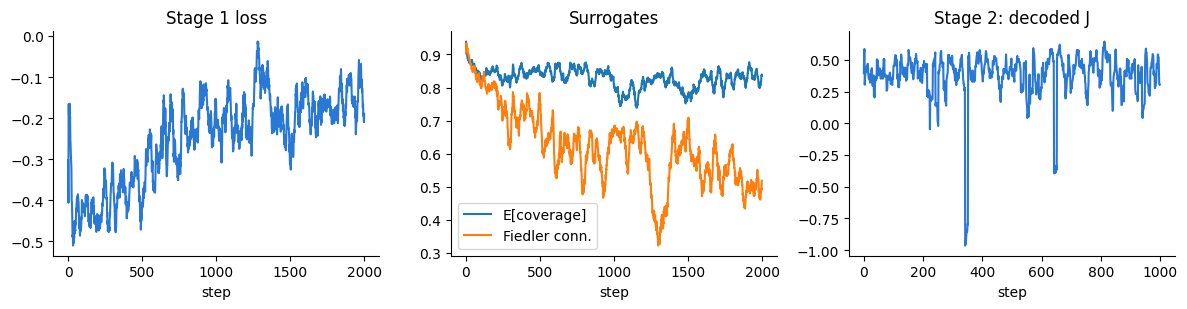

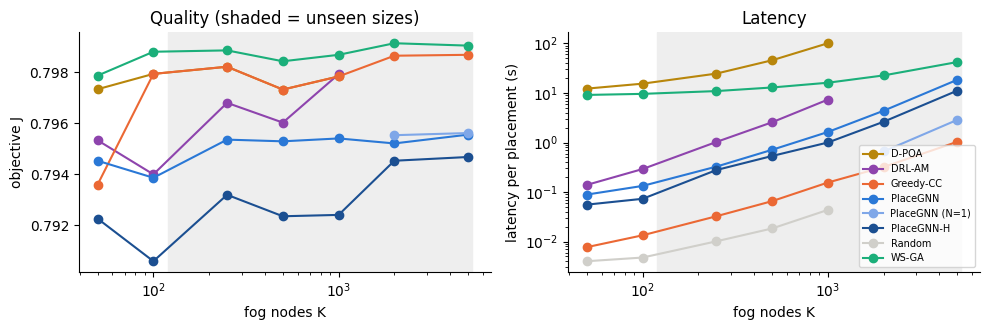

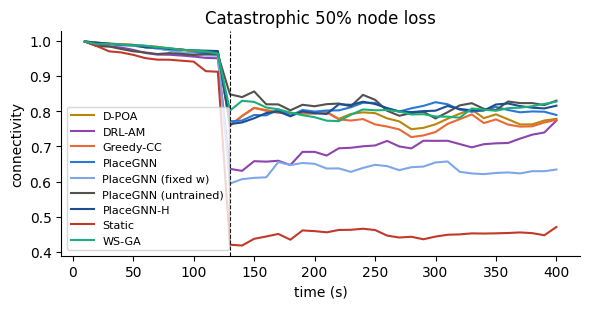

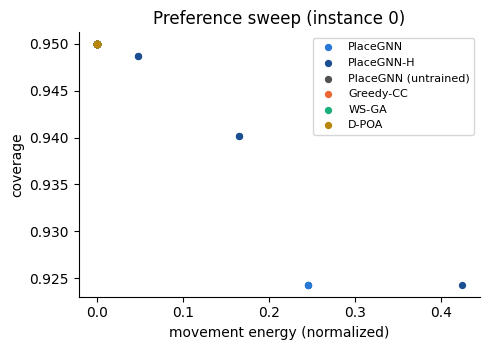

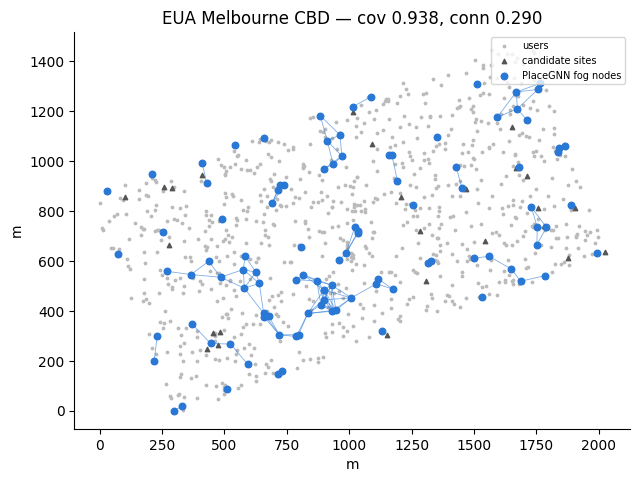

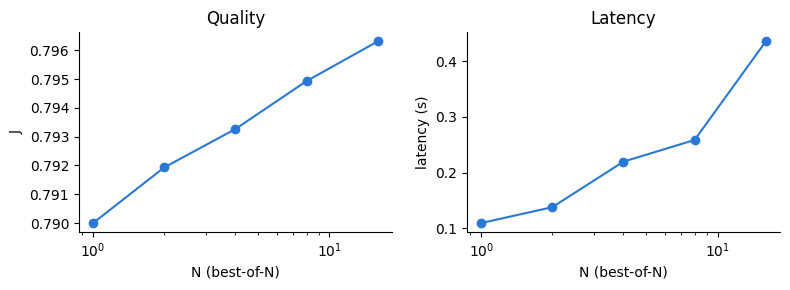

In [33]:
FIG = lambda n: os.path.join(RUN_DIR, "figures", n)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COL = {"PlaceGNN": "#2a78d6", "PlaceGNN-H": "#1b4f91", "Greedy-CC": "#eb6834", "WS-GA": "#1baf7a", "D-POA": "#b8860b",
       "PSO": "#8a8987", "GWO": "#a3a29d", "DE": "#6f6e6a", "TLBO": "#c7c6c1", "DRL-AM": "#8e44ad", "Random": "#d0cfca",
       "Static": "#c0392b", "Supervised-GNN": "#b07cc6", "PlaceGNN w/o repair": "#7fa7e8", "PlaceGNN (fixed w)": "#7fa7e8",
       "PlaceGNN (N=1)": "#7fa7e8", "PlaceGNN (untrained)": "#52514e"}

# F1 training curves
h = pd.DataFrame(hist_main); h1, h2 = h[h.stage == 1], h[h.stage == 2]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(h1.step, h1.loss.rolling(20, min_periods=1).mean(), color=COL["PlaceGNN"]); ax[0].set(title="Stage 1 loss", xlabel="step")
ax[1].plot(h1.step, h1["cov"].rolling(20, min_periods=1).mean(), label="E[coverage]")
ax[1].plot(h1.step, h1["conn"].rolling(20, min_periods=1).mean(), label="Fiedler conn."); ax[1].legend(); ax[1].set(title="Surrogates", xlabel="step")
if len(h2):
    ax[2].plot(h2.step, h2.J_greedy.rolling(10, min_periods=1).mean(), color=COL["PlaceGNN"])
ax[2].set(title="Stage 2: decoded J", xlabel="step"); fig.tight_layout(); fig.savefig(FIG("F1_training.png"), dpi=300); plt.show()

# F2 scalability
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for m, g in main_rows(df_e3).groupby("method"):
    gg = g.groupby("K").agg(J=("J", "mean"), lat=("latency", "mean"))
    if m != "Random":   # Random (J ~ 0.6) would flatten the quality axis; it is in the tables
        ax[0].plot(gg.index, gg.J, "o-", label=m, color=COL.get(m))
    ax[1].plot(gg.index, gg.lat, "o-", label=m, color=COL.get(m))
for a in ax:
    a.axvspan(CFG["train_K"][1], max(CFG["scal_K"] + CFG["scal_K_big"]) * 1.05, color="#eeeeee", zorder=0); a.set_xscale("log"); a.set_xlabel("fog nodes K")
ax[0].set(ylabel="objective J", title="Quality (shaded = unseen sizes)"); ax[1].set(ylabel="latency per placement (s)", yscale="log", title="Latency")
ax[1].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG("F2_scalability.png"), dpi=300); plt.show()

# F3 catastrophic failure time series
fig, ax = plt.subplots(figsize=(6, 3.2))
for m, g in main_rows(df_e5[df_e5.scenario == "catastrophic"]).groupby("method"):
    s = np.mean(np.vstack(g.series_conn.values), 0)
    ax.plot(np.arange(1, len(s) + 1) * CFG["dt"], s, label=m, color=COL.get(m))
ax.axvline(max(1, CFG["dyn_T"] // 3) * CFG["dt"], ls="--", c="k", lw=0.8)
ax.set(xlabel="time (s)", ylabel="connectivity", title="Catastrophic 50% node loss"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG("F3_catastrophic.png"), dpi=300); plt.show()

# F4 Pareto projection (instance 0)
fig, ax = plt.subplots(figsize=(5, 3.6))
for r in [r for r in e6 if r["i"] == 0]:
    p = np.array(r["points"]); ax.scatter(p[:, 2], 1 - p[:, 0], label=r["method"], color=COL.get(r["method"]), s=18)
ax.set(xlabel="movement energy (normalized)", ylabel="coverage", title="Preference sweep (instance 0)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG("F4_pareto.png"), dpi=300); plt.show()

# F5 EUA Melbourne CBD placement
x = EUA[0]; sel, pos, _, _ = gnn_place(_HM, x, W_DEF)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(x.dev_xy[:, 0], x.dev_xy[:, 1], s=3, c="#bbbbbb", label="users")
ax.scatter(x.cand_xy[:, 0], x.cand_xy[:, 1], s=10, marker="^", c="#555555", label="candidate sites")
t = cKDTree(pos); r_sel = x.cand_r[sel]
for i_, j_ in t.query_pairs(CFG["r_max"]):
    if np.linalg.norm(pos[i_] - pos[j_]) <= min(r_sel[i_], r_sel[j_]):
        ax.plot(*pos[[i_, j_]].T, c=COL["PlaceGNN"], lw=0.6, alpha=0.6)
ax.scatter(pos[:, 0], pos[:, 1], s=22, c=COL["PlaceGNN"], label=f"{HEAD} fog nodes")
ev = evaluate(x, sel, pos, W_DEF)
ax.set(title=f"EUA Melbourne CBD — cov {ev['cov']:.3f}, conn {ev['conn']:.3f}", xlabel="m", ylabel="m"); ax.set_aspect("equal"); ax.legend(fontsize=7, loc="upper right")
fig.tight_layout(); fig.savefig(FIG("F5_eua_cbd.png"), dpi=300); plt.show()

# F6 sensitivity: best-of-N quality vs latency
gN = df_e8[df_e8.method.str.contains(r"\[N=")].copy(); gN["N"] = gN.method.str.extract(r"N=(\d+)", expand=False).astype(int)
aggN = gN.groupby("N").agg(J=("J", "mean"), lat=("latency", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].plot(aggN.index, aggN.J, "o-", color=COL["PlaceGNN"]); ax[0].set(xscale="log", xlabel="N (best-of-N)", ylabel="J", title="Quality")
ax[1].plot(aggN.index, aggN.lat, "o-", color=COL["PlaceGNN"]); ax[1].set(xscale="log", xlabel="N (best-of-N)", ylabel="latency (s)", title="Latency")
fig.tight_layout(); fig.savefig(FIG("F6_sensitivity_N.png"), dpi=300); plt.show()

## Summary

In [34]:
def _m(df, method, col):
    g = df[df.method == method][col]
    return g.mean() if len(g) else float("nan")
BASE_SHOW = ["Greedy-CC", "WS-GA", "D-POA", "PSO", "GWO", "DE", "TLBO", "DRL-AM", "Supervised-GNN"]
_fmt = lambda df, col, ms, sc=1, d=4: " | ".join(f"{m} {_m(df, m, col)*sc:.{d}f}" for m in ms)
_KB = max(CFG["scal_K"] + CFG["scal_K_big"])
lines = [
    f"MODE={MODE}  run={RUN_DIR}  total session time {minutes_used():.1f} min  headline={HEAD}",
    "E1  J: " + _fmt(df_e1, "J", ["PlaceGNN", "PlaceGNN-H"] + BASE_SHOW),
    "E1  latency (s): " + _fmt(df_e1, "latency", ["PlaceGNN", "PlaceGNN-H"] + BASE_SHOW, d=3),
    "E2  MILP gap (%): " + _fmt(df_e2, "gap", ["PlaceGNN", "PlaceGNN-H"] + BASE_SHOW, sc=100, d=2),
    f"E3  K={_KB}: " + " | ".join(f"{m} J {df_e3[(df_e3.K == _KB) & (df_e3.method == m)].J.mean():.4f} "
                                  f"({df_e3[(df_e3.K == _KB) & (df_e3.method == m)].latency.mean():.2f}s)" for m in E3_BIG),
    f"E3b incremental: {df_e3b.t_full.mean()/max(df_e3b.t_incr.mean(),1e-9):.1f}x GNN-pass speed-up, max relative logit diff {df_e3b.rel_diff.max():.1e}, "
    f"identical top-K decisions in {df_e3b.same_topK.mean()*100:.0f}% of events",
    "E4  EUA J: " + _fmt(df_e4, "J", ["PlaceGNN", "PlaceGNN-H"] + BASE_SHOW),
    f"E5  mean J over the 6 scenarios: " + " | ".join(f"{m} {df_e5[df_e5.method==m].J.mean():.4f}" for m in E5_METHODS if "(seed " not in m),
    f"E5  catastrophic J / conn: " + " | ".join(f"{m} {df_e5[(df_e5.scenario=='catastrophic')&(df_e5.method==m)].J.mean():.4f} / "
                                              f"{df_e5[(df_e5.scenario=='catastrophic')&(df_e5.method==m)].conn.mean():.3f}" for m in E5_METHODS if "(seed " not in m),
    f"E6  J_pref (best share): " + " | ".join(f"{m} {_m(df_e6, m, 'J_pref'):.4f} ({_m(df_e6, m, 'best_share')*100:.0f}%)" for m in E6_METHODS),
    f"E6  HV: " + " | ".join(f"{m} {_m(df_e6, m, 'HV'):.4f}" for m in E6_METHODS),
    f"V0  validation (same budget): " + " | ".join(f"{k} {v:.4f}" for k, v in _same.items()),
    f"V0  headline: PlaceGNN {tab_v0.loc['PlaceGNN','J']:.4f} vs PlaceGNN-H {tab_v0.loc['PlaceGNN-H','J']:.4f} -> {HEAD}",
    "E8  best-of-N J: " + " | ".join(f"N={n} {_m(df_e8, f'{HEAD} [N={n}]', 'J'):.4f} ({_m(df_e8, f'{HEAD} [N={n}]', 'latency'):.2f}s)" for n in CFG["sens_N"]),
    "SIG " + " || ".join(f"{m}: " + ", ".join(f"{ex} {v}" for ex, v in T_SIG.loc[m].items() if isinstance(v, str)) for m in T_SIG.index),
    "SEEDS " + " || ".join(f"{r['metric']}: U {r['PlaceGNN mean ± std']}, H {r['PlaceGNN-H mean ± std']} (Greedy {r['Greedy-CC']}, GA {r['WS-GA']}, D-POA {r['D-POA']}, DRL {r['DRL-AM']})" for r in T_SEED.to_dict("records")),
]
print("\n".join(lines))
open(os.path.join(RUN_DIR, "SUMMARY.txt"), "w").write("\n".join(lines))
if MODE.upper() == "QUICK":
    print("\nQUICK mode numbers are a pipeline smoke test only. Set MODE='FULL' for paper results.")

MODE=FULL  run=/content/drive/MyDrive/PlaceGNN_runs/placegnn_full_v5  total session time 68.8 min  headline=PlaceGNN
E1  J: PlaceGNN 0.7954 | PlaceGNN-H 0.7913 | Greedy-CC 0.7967 | WS-GA 0.7986 | D-POA 0.7977 | PSO 0.7983 | GWO 0.7975 | DE 0.7976 | TLBO 0.7979 | DRL-AM 0.7950 | Supervised-GNN 0.7983
E1  latency (s): PlaceGNN 0.172 | PlaceGNN-H 0.085 | Greedy-CC 0.014 | WS-GA 9.608 | D-POA 15.071 | PSO 13.548 | GWO 14.448 | DE 14.802 | TLBO 16.125 | DRL-AM 0.314 | Supervised-GNN 0.131
E2  MILP gap (%): PlaceGNN 0.33 | PlaceGNN-H 0.75 | Greedy-CC 0.00 | WS-GA 0.00 | D-POA 0.00 | PSO 0.00 | GWO 0.00 | DE 0.00 | TLBO 0.00 | DRL-AM 0.23 | Supervised-GNN 0.00
E3  K=5000: PlaceGNN J 0.7956 (18.52s) | PlaceGNN-H J 0.7947 (11.18s) | PlaceGNN (N=1) J 0.7956 (2.87s) | Greedy-CC J 0.7987 (1.04s) | WS-GA J 0.7990 (42.19s)
E3b incremental: 0.7x GNN-pass speed-up, max relative logit diff 4.9e-07, identical top-K decisions in 100% of events
E4  EUA J: PlaceGNN 0.3711 | PlaceGNN-H 0.3548 | Greedy-CC 0.